In [42]:
# ===== 팀 프로젝트 시작 셀 =====
import os, sys
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
NAME = "본인이름"
REPO_URL = "github.com/DA15-Lab/team3-ping-analytics.git"
PROJECT_DIR = "/content/team3-ping-analytics"

if not os.path.exists(PROJECT_DIR):
    !git clone -q https://{TOKEN}@{REPO_URL}
    %cd {PROJECT_DIR}
else:
    %cd {PROJECT_DIR}
    !git pull -q

!git config user.email "{NAME}@example.com"
!git config user.name "{NAME}"

!pip install -q -r requirements.txt

sys.path.append("/content/team3-ping-analytics/src")
from preprocessing import *

print(module_test())
print("✅ 준비 완료")

/content/team3-ping-analytics
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 64.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
✅ 모듈 설치 완료
✅ 준비 완료


In [ ]:
# ===== 작업 저장 셀 =====
NAME = "Donghee"
PROJECT_DIR = "/content/team3-ping-analytics"

%cd {PROJECT_DIR}
!git config pull.rebase false
!git config core.editor "true"

!git pull
!pip install -q -r requirements.txt

from google.colab import _message
import json

with open(f'notebooks/{NAME}_analysis.ipynb', 'w') as f:
    json.dump(_message.blocking_request('get_ipynb', timeout_sec=30)['ipynb'], f)

!pip freeze | grep -v "google-colab" > requirements.txt

!git add .
!git commit -m "polls_question, polls_questionpiece 전처리"
!git push

/content/team3-ping-analytics
Already up to date.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 19.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.font_manager as fm
# import urllib.request
# import seaborn as sns

# font_path = "/tmp/Malgun.ttf"
# urllib.request.urlretrieve("https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf", font_path)

# # 최신 matplotlib 버전의 표준 메서드(addfont) 사용
# fm.fontManager.addfont(font_path)
# plt.rc('font', family='NanumGothic')
# plt.rcParams['axes.unicode_minus'] = False

#### 질문 데이터 테이블

In [ ]:
# 데이터프레임으로 불러오기
questions = pd.read_csv('/content/drive/MyDrive/00_원본 csv/polls_question.csv')

# 상위 5개 행 확인
print(questions.head())

    id                 question_text           created_at
0   99            가장 신비한 매력이 있는 사람은?  2023-03-31 15:22:53
1  100  "이 사람으로 한 번 살아보고 싶다" 하는 사람은?  2023-03-31 15:22:53
2  101                     미래의 틱톡커는?  2023-03-31 15:22:54
3  102               여기서 제일 특이한 친구는?  2023-03-31 15:22:54
4  103               가장 지켜주고 싶은 사람은?  2023-03-31 15:22:55


### polls_question 전처리

In [ ]:
# 필수 컬럼 결측치 제거 및 타입 변환
questions_clean = questions.dropna(subset=['id', 'question_text', 'created_at']).copy()
questions_clean['created_at'] = pd.to_datetime(questions_clean['created_at'])

# 중복 ID 제거 및 created_at 기준 오름차순 정렬
questions_clean = questions_clean.drop_duplicates(subset=['id'])
questions_clean = questions_clean.sort_values(by='created_at', ascending=True)

In [ ]:
# 텍스트별 가장 먼저 생성된 대표 ID 추출
text_to_canonical_id = (
    questions_clean.drop_duplicates(subset=['question_text'], keep='first')
    .set_index('question_text')['id']
    .to_dict()
)

# 모든 원본 ID를 대표 ID로 연결하는 맵핑 딕셔너리(id_mapping) 구축
id_mapping = {}
for idx, row in questions_clean.iterrows():
    q_id = row['id']
    q_text = row['question_text']
    if q_text in text_to_canonical_id:
        id_mapping[q_id] = text_to_canonical_id[q_text]

print(f"매핑 딕셔너리 생성 완료: 총 {len(id_mapping)}개의 ID가 매핑되었습니다.")

매핑 딕셔너리 생성 완료: 총 5025개의 ID가 매핑되었습니다.


In [ ]:
# 대표 ID 목록 추출
canonical_ids = list(text_to_canonical_id.values())

# 대표 ID에 해당하는 행들만 남기기
questions_clean = questions_clean[questions_clean['id'].isin(canonical_ids)].copy()

print(f"중복 제거 후 남은 최종 질문 데이터 개수: {len(questions_clean)}개")

중복 제거 후 남은 최종 질문 데이터 개수: 3903개


In [ ]:
# # 전처리가 완료된 questions_clean 테이블을 CSV 파일로 저장
# output_path = '/content/drive/MyDrive/00_원본 csv/questions_clean.csv'
# questions_clean.to_csv(output_path, index=False, encoding='utf-8-sig')

# print(f"파일 저장 완료: {output_path}")

파일 저장 완료: /content/drive/MyDrive/00_원본 csv/questions_clean.csv


#### polls_questionpiece 전처리

#### 질문 조각

In [ ]:
# # 데이터프레임으로 불러오기
# question_piece = pd.read_csv('/content/drive/MyDrive/00_원본 csv/polls_questionpiece.csv')

# # 상위 5개 행 확인
# print(question_piece.head())

       id  is_voted           created_at  question_id  is_skipped
0  998458         1  2023-04-28 12:27:22          252           0
1  998459         1  2023-04-28 12:27:22          244           0
2  998460         1  2023-04-28 12:27:22          183           0
3  998461         1  2023-04-28 12:27:22          101           0
4  998462         1  2023-04-28 12:27:22          209           0


In [ ]:
# question_piece

,id,is_voted,created_at,question_id,is_skipped
0,998458,1,2023-04-28 12:27:22,252,0
1,998459,1,2023-04-28 12:27:22,244,0
2,998460,1,2023-04-28 12:27:22,183,0
3,998461,1,2023-04-28 12:27:22,101,0
4,998462,1,2023-04-28 12:27:22,209,0
...,...,...,...,...,...
1265471,208385226,0,2024-05-07 11:32:30,960,0
1265472,208385227,0,2024-05-07 11:32:30,1402,0
1265473,208385228,0,2024-05-07 11:32:30,1676,0
1265474,208385229,0,2024-05-07 11:32:30,3115,0


In [ ]:
# question_piece.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1265476 entries, 0 to 1265475
Data columns (total 5 columns):
 #   Column       Non-Null Count    Dtype 
---  ------       --------------    ----- 
 0   id           1265476 non-null  int64 
 1   is_voted     1265476 non-null  int64 
 2   created_at   1265476 non-null  object
 3   question_id  1265476 non-null  int64 
 4   is_skipped   1265476 non-null  int64 
dtypes: int64(4), object(1)
memory usage: 48.3+ MB


In [ ]:
# # 결측치 확인
# print("--- polls_questionpiece 결측치 확인 ---")
# print(question_piece.isnull().sum())

--- polls_questionpiece 결측치 확인 ---
id             0
is_voted       0
created_at     0
question_id    0
is_skipped     0
dtype: int64


In [ ]:
# # 필수 컬럼 기준 결측치 제거
# essential_cols = ['question_id', 'is_voted', 'is_skipped', 'created_at']
# question_piece_clean = question_piece.dropna(subset=essential_cols).copy()

In [ ]:
# # created_at 컬럼을 datetime 형식으로 변환
# question_piece_clean['created_at'] = pd.to_datetime(question_piece_clean['created_at'])

# # created_at 최소값 및 최대값 확인
# print("\n--- created_at 범위 확인 ---")
# print(f"최소값(시작일): {question_piece_clean['created_at'].min()}")
# print(f"최대값(종료일): {question_piece_clean['created_at'].max()}")


--- created_at 범위 확인 ---
최소값(시작일): 2023-04-28 12:27:22
최대값(종료일): 2024-05-07 11:32:30


In [ ]:
# # 타겟 값(is_voted, is_skipped) 타입 정수형 변환 및 범위 확인 (0 또는 1이어야 함)
# question_piece_clean['is_voted'] = question_piece_clean['is_voted'].astype(int)
# question_piece_clean['is_skipped'] = question_piece_clean['is_skipped'].astype(int)

# # 논리적 이상치 확인: 투표와 스킵이 동시에 1이 된 비정상 데이터 체크
# invalid_rows = ((question_piece_clean['is_voted'] == 1) & (question_piece_clean['is_skipped'] == 1)).sum()
# print(f"\n투표와 스킵이 동시에 체크된 비정상 데이터 개수: {invalid_rows}개")

# # 비정상 데이터가 있다면 제거
# if invalid_rows > 0:
#     question_piece_clean = question_piece_clean[
#         ~((question_piece_clean['is_voted'] == 1) & (question_piece_clean['is_skipped'] == 1))
#     ]

# print(f"polls_questionpiece 전처리 완료 후 최종 데이터 개수: {len(question_piece_clean)}개")


투표와 스킵이 동시에 체크된 비정상 데이터 개수: 1127개
polls_questionpiece 전처리 완료 후 최종 데이터 개수: 1264349개


In [ ]:
# # is_voted 컬럼의 고유값 확인
# print("--- is_voted 컬럼의 고유값 ---")
# print(question_piece['is_voted'].value_counts(dropna=False))

# # is_skipped 컬럼의 고유값 확인
# print("\n--- is_skipped 컬럼의 고유값 ---")
# print(question_piece['is_skipped'].value_counts(dropna=False))

# # cross_tab(교차표)
# # is_voted와 is_skipped의 교차표(Cross-tabulation) 확인
# print(pd.crosstab(question_piece['is_voted'], question_piece['is_skipped'], margins=True))

--- is_voted 컬럼의 고유값 ---
is_voted
1    1218687
0      46789
Name: count, dtype: int64

--- is_skipped 컬럼의 고유값 ---
is_skipped
0    1264349
1       1127
Name: count, dtype: int64
is_skipped        0     1      All
is_voted                          
0             46789     0    46789
1           1217560  1127  1218687
All         1264349  1127  1265476


In [ ]:
# # is_voted와 is_skipped가 동시에 1인 비정상 데이터(로그 오류) 제거
# question_piece = question_piece[
#     ~((question_piece['is_voted'] == 1) & (question_piece['is_skipped'] == 1))
# ]

In [ ]:
# # id_mapping 딕셔너리를 활용해 question_piece의 question_id를 최초 생성된 대표 ID로 직접 치환
# question_piece['question_id'] = question_piece['question_id'].map(id_mapping).fillna(question_piece['question_id'])

# # 변환 결과 확인
# print(f"question_piece 고유 ID 변환 완료. 총 데이터 행 수: {len(question_piece)}")
# print(question_piece.head())

question_piece 고유 ID 변환 완료. 총 데이터 행 수: 1264349
       id  is_voted           created_at  question_id  is_skipped
0  998458         1  2023-04-28 12:27:22          252           0
1  998459         1  2023-04-28 12:27:22          244           0
2  998460         1  2023-04-28 12:27:22          183           0
3  998461         1  2023-04-28 12:27:22          101           0
4  998462         1  2023-04-28 12:27:22          209           0


/tmp/ipykernel_1648/2759024848.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  question_piece['question_id'] = question_piece['question_id'].map(id_mapping).fillna(question_piece['question_id'])


In [ ]:
# question_piece

,id,is_voted,created_at,question_id,is_skipped
0,998458,1,2023-04-28 12:27:22,252,0
1,998459,1,2023-04-28 12:27:22,244,0
2,998460,1,2023-04-28 12:27:22,183,0
3,998461,1,2023-04-28 12:27:22,101,0
4,998462,1,2023-04-28 12:27:22,209,0
...,...,...,...,...,...
1265471,208385226,0,2024-05-07 11:32:30,960,0
1265472,208385227,0,2024-05-07 11:32:30,1402,0
1265473,208385228,0,2024-05-07 11:32:30,1676,0
1265474,208385229,0,2024-05-07 11:32:30,3115,0


In [ ]:
# # 전처리가 완료된 question_piece 테이블을 CSV 파일로 저장
# output_path = '/content/drive/MyDrive/00_원본 csv/polls_question_piece_cleaned.csv'
# question_piece.to_csv(output_path, index=False, encoding='utf-8-sig')

# print(f"파일 저장 완료: {output_path}")

파일 저장 완료: /content/drive/MyDrive/00_원본 csv/polls_question_piece_cleaned.csv


#### accounts_userquestionrecord 테이블 질문 추가 전처리

In [ ]:
# 만약 accounts_userquestionrecord가 CSV 파일이라면 먼저 로드해 줍니다.
# file_path_record = 'accounts_userquestionrecord.csv'
df_record = pd.read_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/accounts_userquestionrecord_cleaned.csv')

# (주의) df_record는 실제 사용 중인 accounts_userquestionrecord 데이터프레임 변수명으로 변경해주세요.
# 예시: df_record = accounts_userquestionrecord

print(f"변환 전 데이터 행 수: {len(df_record)}")

# id_mapping 딕셔너리를 활용해 question_id를 최초 생성된 대표 ID로 직접 치환
# 매칭되는 값이 없는 경우 기존 ID 그대로 유지(.fillna)
df_record['question_id'] = df_record['question_id'].map(id_mapping).fillna(df_record['question_id'])

# 변환 결과 확인
print(f"accounts_userquestionrecord의 question_id 고유 ID 변환 완료. 총 데이터 행 수: {len(df_record)}")
print(df_record.head())

# (선택) 만약 수정한 결과를 다시 CSV 파일로 저장하고 싶다면 아래 주석을 해제하세요.
df_record.to_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/accounts_userquestionrecord_updated.csv', index=False, encoding='utf-8-sig')

변환 전 데이터 행 수: 1213926
accounts_userquestionrecord의 question_id 고유 ID 변환 완료. 총 데이터 행 수: 1213926
       id status           created_at  chosen_user_id  question_id  user_id  \
0  771777      C  2023-04-28 12:27:49          849469          252   849436   
1  771800      C  2023-04-28 12:28:02          849446          244   849436   
2  771812      C  2023-04-28 12:28:09          849454          183   849436   
3  771828      C  2023-04-28 12:28:16          847375          101   849436   
4  771851      C  2023-04-28 12:28:26          849477          209   849436   

   question_piece_id  has_read answer_status    answer_updated_at  \
0             998458         0             N  2023-04-28 12:27:49   
1             998459         0             N  2023-04-28 12:28:02   
2             998460         1             N  2023-04-28 12:28:09   
3             998461         0             N  2023-04-28 12:28:16   
4             998462         1             N  2023-04-28 12:28:26   

   report_count

#### 맵핑 과정 검증

In [ ]:
# # question_piece 테이블의 question_id에 앞서 만든 id_mapping 딕셔너리를 적용
# # (중복된 질문 ID들을 최초 생성된 대표 ID로 치환하여 데이터 손실 방지)
# question_piece['question_id_mapped'] = question_piece['question_id'].map(id_mapping).fillna(question_piece['question_id'])

# # 맵핑된 ID(question_id_mapped)를 기준으로 questions_clean 테이블과 Left Join 결합
# df_merged = question_piece.merge(
#     questions_clean,
#     left_on='question_id_mapped',
#     right_on='id',
#     how='left',
#     suffixes=('_piece', '_question')
# )

# # 결합 후 데이터프레임 크기 및 결측치 확인
# print(f"결합 완료된 df_merged 크기: {df_merged.shape}")
# print("--- 결합 후 결측치 확인 ---")
# print(df_merged.isnull().sum())

/tmp/ipykernel_1648/282077320.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  question_piece['question_id_mapped'] = question_piece['question_id'].map(id_mapping).fillna(question_piece['question_id'])


결합 완료된 df_merged 크기: (1264349, 9)
--- 결합 후 결측치 확인 ---
id_piece               0
is_voted               0
created_at_piece       0
question_id            0
is_skipped             0
question_id_mapped     0
id_question            0
question_text          0
created_at_question    0
dtype: int64


In [ ]:
# df_merged

,id_piece,is_voted,created_at_piece,question_id,is_skipped,question_id_mapped,id_question,question_text,created_at_question
0,998458,1,2023-04-28 12:27:22,252,0,252,252,손이 가장 이쁘게 생겼을거 같은 사람은?,2023-04-01 11:09:27
1,998459,1,2023-04-28 12:27:22,244,0,244,244,대학교에서 학생회장할 것 같은 사람은?,2023-04-01 11:09:26
2,998460,1,2023-04-28 12:27:22,183,0,183,183,나의 자존감을 가장 많이 높여줬던 사람은?,2023-04-01 11:09:14
3,998461,1,2023-04-28 12:27:22,101,0,101,101,미래의 틱톡커는?,2023-03-31 15:22:54
4,998462,1,2023-04-28 12:27:22,209,0,209,209,항상 좋은 냄새가 나는 사람은?,2023-04-01 11:09:20
...,...,...,...,...,...,...,...,...,...
1264344,208385226,0,2024-05-07 11:32:30,960,0,960,960,가장 인싸일 것 같은 친구는?,2023-05-15 14:00:19
1264345,208385227,0,2024-05-07 11:32:30,1402,0,1402,1402,가장 리더쉽 있을 것 같은 사람,2023-05-15 14:03:19
1264346,208385228,0,2024-05-07 11:32:30,1676,0,1676,1676,화장 전후 가장 비슷할 것 같은 사람은?,2023-06-02 08:06:24
1264347,208385229,0,2024-05-07 11:32:30,3115,0,3115,3115,가장 박새로이컷이 잘 어울릴 것 같은 사람,2023-06-02 08:07:08


### 1-1 분석

In [ ]:
# # 질문별 총 노출 횟수 집계
# question_exposure = df_merged.groupby('id_question').agg(
#     exposure_count=('id_piece', 'count'),
#     mean_vote_rate=('is_voted', 'mean')
# ).reset_index()

# # 노출 횟수 분포 요약 통계 확인
# print("--- 노출 횟수 요약 통계 ---")
# print(question_exposure['exposure_count'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

# # 노출 횟수가 1회인 질문 비중 확인
# single_exposure_count = (question_exposure['exposure_count'] == 1).sum()
# total_questions = len(question_exposure)
# print(f"\n노출 횟수가 1회뿐인 질문: {single_exposure_count}개 ({single_exposure_count / total_questions * 100:.2f}%)")

--- 노출 횟수 요약 통계 ---
count     3903.000000
mean       323.942864
std        542.878630
min          1.000000
25%         25.000000
50%         38.000000
75%        379.000000
90%       1462.800000
95%       1672.000000
99%       1893.960000
max      10160.000000
Name: exposure_count, dtype: float64

노출 횟수가 1회뿐인 질문: 2개 (0.05%)


In [ ]:
# # df_filtered가 정의되지 않은 상태이므로, df_merged를 기준으로 노출 횟수 계산 및 데이터프레임 재생성
# exposure_df = df_merged.groupby('id_question').size().reset_index(name='exposure_count')
# df_filtered = df_merged.merge(exposure_df, on='id_question', how='left')

# # 날짜형 변환 및 경과 일수 계산
# df_filtered['created_at_piece'] = pd.to_datetime(df_filtered['created_at_piece'])
# df_filtered['created_at_question'] = pd.to_datetime(df_filtered['created_at_question'])
# df_filtered['question_age_days'] = (df_filtered['created_at_piece'] - df_filtered['created_at_question']).dt.days

# # 질문별 노출 횟수 및 최초/최종 노출 시점, 투표 여부 집계
# question_summary = df_filtered.groupby('id_question').agg(
#     exposure_count=('id_piece', 'count'),
#     created_at_question=('created_at_question', 'first'),
#     first_exposure=('created_at_piece', 'min'),
#     last_exposure=('created_at_piece', 'max'),
#     vote_sum=('is_voted', 'sum')
# ).reset_index()

# # 질문 생존 일수 계산
# question_summary['question_lifespan_days'] = (question_summary['last_exposure'] - question_summary['created_at_question']).dt.days

# # 노출 수가 5회 이하인 '저노출 질문' 필터링
# low_exposure_questions = question_summary[question_summary['exposure_count'] <= 10]

# print(f"전체 질문 수: {len(question_summary):,d}개")
# print(f"노출 수 5회 이하인 저노출 질문 수: {len(low_exposure_questions):,d}개 ({len(low_exposure_questions)/len(question_summary)*100:.1f}%)")

# print("\n--- 저노출 질문의 생존 일수 및 투표 현황 요약 ---")
# print(low_exposure_questions[['exposure_count', 'question_lifespan_days', 'vote_sum']].describe())

전체 질문 수: 3,903개
노출 수 5회 이하인 저노출 질문 수: 39개 (1.0%)

--- 저노출 질문의 생존 일수 및 투표 현황 요약 ---
       exposure_count  question_lifespan_days   vote_sum
count       39.000000               39.000000  39.000000
mean         8.538462               95.179487   5.923077
std          2.382460               76.781259   2.464320
min          1.000000               11.000000   0.000000
25%          8.000000               37.000000   5.000000
50%          9.000000               74.000000   6.000000
75%         10.000000              118.500000   8.000000
max         10.000000              321.000000  10.000000


In [ ]:
# # 노출 수가 5회 이하인 저노출 질문 ID 추출
# low_exposure_ids = question_summary[question_summary['exposure_count'] <= 10]['id_question']

# # 해당 저노출 질문들의 전체 노출 로그 데이터 필터링
# df_low_exposure = df_filtered[df_filtered['id_question'].isin(low_exposure_ids)].copy()

# # 질문 생성일 기준으로 각 노출일이 며칠 만에 이루어졌는지 확인하기 위한 컬럼 선택
# low_exposure_details = df_low_exposure[[
#     'id_question',
#     'question_text',
#     'created_at_question',
#     'created_at_piece',
#     'question_age_days',
#     'exposure_count'
# ]].sort_values(by=['id_question', 'created_at_piece'])

# # 상위 20개 결과 출력
# print(low_exposure_details.head(40))

         id_question         question_text created_at_question  \
1224166         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1225047         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1226521         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1228304         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1238627         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1239762         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1249069         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1250130         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1263084         3225  무인도 한달살기에 데려가고 싶은 친구 2023-06-06 06:10:05   
1219422         3250          지켜주고 싶은 사람은? 2023-06-06 06:10:06   
1225599         3250          지켜주고 싶은 사람은? 2023-06-06 06:10:06   
1230353         3250          지켜주고 싶은 사람은? 2023-06-06 06:10:06   
1233759         3250          지켜주고 싶은 사람은? 2023-06-06 06:10:06   
1235857         3250          지켜주고 싶은 사람은? 2023-06-06 06:10:06   
1246151   

In [ ]:
# # 각 질문(id_question)별로 question_age_days가 가장 큰(가장 오래된 노출) 행의 인덱스를 추출
# idx_max_age = df_filtered.groupby('id_question')['question_age_days'].idxmax()

# # 해당 행들만 필터링하여 필요한 컬럼만 보기 쉽게 구성
# oldest_exposure_per_question = df_filtered.loc[idx_max_age, [
#     'id_question',
#     'question_text',
#     'created_at_question',
#     'created_at_piece',
#     'question_age_days',
#     'exposure_count'
# ]].reset_index(drop=True)

# # 경과 일수가 긴 순서대로 정렬하여 상위 20개 확인
# oldest_exposure_per_question = oldest_exposure_per_question.sort_values(by='question_age_days', ascending=False)

# print(oldest_exposure_per_question.tail(20))

      id_question                  question_text created_at_question  \
1462         1593        손이 닿았을 때 가장 설렐것 같은 사람은? 2023-05-15 14:04:36   
1456         1586             사귀면 애교가 많을 것 같은 사람 2023-05-15 14:04:33   
1994         2167               웹툰에 나올 것 같은 사람은? 2023-06-02 08:06:39   
2708         2927       기념일 엄청 꼼꼼하게 챙길 것 같은 사람은? 2023-06-02 08:07:02   
1814         1974  좋아하는 사람이 있는데 숨기고 있을 것 같은 사람은? 2023-06-02 08:06:33   
2024         2201           옷장이 제일 깔끔할 것 같은 사람은? 2023-06-02 08:06:40   
1669         1822          큰 돈을 바로 빌려줄 것 같은 친구는? 2023-06-02 08:06:28   
2717         2936                  군인이 어울리는 친구는? 2023-06-02 08:07:03   
2647         2859            나중에 외제차 탈 것 같은 사람은? 2023-06-02 08:07:00   
3132         3375          학원을 제일 많이 다닐것 같은 친구는? 2023-06-06 06:10:07   
1543         1685          혼자 다니면 길 잃어버릴 것 같은 친구 2023-06-02 08:06:24   
2365         2559         발에서 블루베리 향 날 것 같은 사람은? 2023-06-02 08:06:51   
3497         3746         시험지 찍으면 다 틀릴 것 같은 친구는? 2023-06-06 06:1

In [ ]:
# # 노출 횟수가 정확히 1회인 데이터 필터링
# single_exposure_df = df_filtered[df_filtered['exposure_count'] == 20].copy()

# print(f"노출 횟수가 1회인 전체 데이터 행 수: {len(single_exposure_df):,d}개")

# # 필요한 컬럼만 추출하여 상위 20개 확인
# print("\n--- 노출 횟수 1회 데이터 샘플 ---")
# print(single_exposure_df[[
#     'id_question',
#     'question_text',
#     'created_at_question',
#     'created_at_piece',
#     'question_age_days',
#     'exposure_count'
# ]].head(20))

노출 횟수가 1회인 전체 데이터 행 수: 1,640개

--- 노출 횟수 1회 데이터 샘플 ---
         id_question        question_text created_at_question  \
1189417         2011         점이 매력적인 사람은? 2023-06-02 08:06:34   
1189499         2415    성우하면 좋을 것 같은 사람은? 2023-06-02 08:06:46   
1189541         2011         점이 매력적인 사람은? 2023-06-02 08:06:34   
1192289         2415    성우하면 좋을 것 같은 사람은? 2023-06-02 08:06:46   
1193484         1783  포근해서 계속 안기고 싶은 사람은? 2023-06-02 08:06:27   
1193642         2415    성우하면 좋을 것 같은 사람은? 2023-06-02 08:06:46   
1194370         1783  포근해서 계속 안기고 싶은 사람은? 2023-06-02 08:06:27   
1195745         2011         점이 매력적인 사람은? 2023-06-02 08:06:34   
1198583         1783  포근해서 계속 안기고 싶은 사람은? 2023-06-02 08:06:27   
1200743         1783  포근해서 계속 안기고 싶은 사람은? 2023-06-02 08:06:27   
1203964         2011         점이 매력적인 사람은? 2023-06-02 08:06:34   
1204579         1783  포근해서 계속 안기고 싶은 사람은? 2023-06-02 08:06:27   
1205146         2011         점이 매력적인 사람은? 2023-06-02 08:06:34   
1205336         1783  포근해서 계속 안기고 싶

In [ ]:
# # 질문 생성일과 노출(응답)일의 차이(question_age_days)가 0인 데이터 필터링
# zero_age_df = df_filtered[df_filtered['question_age_days'] == 0].copy()

# print(f"생성 당일 노출된 데이터 행 수: {len(zero_age_df):,d}개 (전체의 {len(zero_age_df)/len(df_filtered)*100:.2f}%)")

# # 주요 컬럼 추출하여 상위 20개 샘플 확인
# print("\n--- 생성 당일 노출 데이터 샘플 ---")
# print(zero_age_df[[
#     'id_question',
#     'question_text',
#     'created_at_question',
#     'created_at_piece',
#     'question_age_days',
#     'exposure_count'
# ]].head(20))

생성 당일 노출된 데이터 행 수: 66,472개 (전체의 5.26%)

--- 생성 당일 노출 데이터 샘플 ---
       id_question                 question_text created_at_question  \
48350          373                        영어 ACE 2023-05-02 05:32:43   
48351          398                등빨이 가장 좋은 사람은? 2023-05-02 05:32:50   
48369          387             주짓수 같이 하고 싶은 사람은? 2023-05-02 05:32:47   
48370          427  요즘 유행하는 밈을 다 알고 있을 것 같은 사람은? 2023-05-02 05:32:56   
48371          343               연락을 잘 받아주는 친구는? 2023-05-02 05:32:36   
48373          410       발냄새가 호두과자 냄새일 것 같은 사람은? 2023-05-02 05:32:52   
48375          383             워터파크 같이 가고싶은 사람은? 2023-05-02 05:32:46   
48376          491       조언이 필요할 때 가장 먼저 찾는 친구는? 2023-05-02 05:33:13   
48377          379           롯데월드 둘이서 가고 싶은 사람은? 2023-05-02 05:32:45   
48381          425              닮은꼴 연예인이 있는 사람은? 2023-05-02 05:32:56   
48382          449        ISFJ에 가장 가까울 것 같은 사람은? 2023-05-02 05:33:02   
48383          524               웃는 모습이 호감인 친구는? 2023-05-02 05:33:22   


In [ ]:
# # 생성일이 2023년 6월 6일인 데이터 필터링
# df_filtered['created_at_question'] = pd.to_datetime(df_filtered['created_at_question'])
# target_date = pd.to_datetime('2023-06-06').date()

# date_target_df = df_filtered[df_filtered['created_at_question'].dt.date == target_date].copy()

# # 질문별 고유 정보 및 노출 횟수 추출 (중복 행 제거)
# questions_by_date = date_target_df[['id_question', 'question_text', 'exposure_count', 'created_at_question']].drop_duplicates()

# # 노출 횟수가 높은 순서(내림차순)로 정렬
# questions_sorted = questions_by_date.sort_values(by='exposure_count', ascending=False).reset_index(drop=True)

# print(f"2023년 6월 6일에 생성된 총 질문 수: {len(questions_sorted):,d}개")
# print("\n--- 노출 횟수 상위 질문 목록 ---")
# print(questions_sorted.head(2000))

2023년 6월 6일에 생성된 총 질문 수: 972개

--- 노출 횟수 상위 질문 목록 ---
     id_question                         question_text  exposure_count  \
0           3565                             신비로운 친구는?              35   
1           4043             사투리를 가장 맛깔나게 살릴 것 같은 사람은?              34   
2           3612                          은근 재능충인 사람은?              34   
3           4013                   혼자서도 잘해먹고 살것 같은사람은?              32   
4           3664                    벙거지가 잘 어울릴 것 같은 사람              32   
..           ...                                   ...             ...   
967         3860                   한번쯤 목마를 태워주고 싶은사람은?               7   
968         4412  할머니,  할아버지가 돼도 이 친구만큼은 연락하고 지낼 것 같아!               5   
969         4280          너에게 칭찬을 받는다면 가장 기분 좋을 것 같아!                2   
970         4313                  사달라는거 다 사줄 것 같은 사람은?               1   
971         4970                   개학 하자마자 인사 될것 같은 사람               1   

    created_at_question  
0   2023-06-06 06:10:10  
1   2

- 질문의 마지막 생성일인 2023-06-06일에 가까울 수록 질문의 노출 빈도가 적음

In [ ]:
# # 생성일 컬럼을 datetime으로 변환 후 날짜만 추출
# df_filtered['created_at_question'] = pd.to_datetime(df_filtered['created_at_question'])
# df_filtered['question_date'] = df_filtered['created_at_question'].dt.date

# # 존재하는 모든 질문 생성일을 내림차순(최신순)으로 정렬하여 고유값 추출
# unique_dates = sorted(df_filtered['question_date'].unique(), reverse=True)

# # 가장 마지막 날짜(2023-06-06)의 바로 직전 날짜(인덱스 1) 자동 탐색
# if len(unique_dates) > 1:
#     prev_target_date = unique_dates[1]
#     print(f"탐색된 직전 질문 생성일: {prev_target_date}")

#     # 4. 직전 생성일에 만들어진 데이터 필터링
#     date_target_df = df_filtered[df_filtered['question_date'] == prev_target_date].copy()

#     # 5. 질문별 고유 정보 및 노출 횟수 추출 (중복 행 제거)
#     questions_by_date = date_target_df[['id_question', 'question_text', 'exposure_count', 'created_at_question']].drop_duplicates()

#     # 6. 노출 횟수가 높은 순서(내림차순)로 정렬
#     questions_sorted = questions_by_date.sort_values(by='exposure_count', ascending=False).reset_index(drop=True)

#     print(f"{prev_target_date}에 생성된 총 질문 수: {len(questions_sorted):,d}개")
#     print("\n--- 직전 생성일 노출 횟수 상위 질문 목록 ---")
#     print(questions_sorted.head(20))
# else:
#     print("비교할 수 있는 이전 생성일이 존재하지 않습니다.")

탐색된 직전 질문 생성일: 2023-06-02
2023-06-02에 생성된 총 질문 수: 1,418개

--- 직전 생성일 노출 횟수 상위 질문 목록 ---
    id_question                question_text  exposure_count  \
0          2428               선물을 주고 싶은 사람은?              83   
1          2220              연예인의 기질이 보이는 친구              82   
2          1772            플래너 잘 쓸 것 같은 사람은?              79   
3          2007            제일 마음씨 착할 것 같은 친구              75   
4          1670             회사 비서에 잘 어울리는 사람              75   
5          2801       내가 전화하면 바로 달려올 것 같은 친구              74   
6          2052             잠버릇이 특이할 것 같은 친구              73   
7          3084            가장 열심히 사는 것 같은 사람              68   
8          2128                   이 학교의 퀸카는?              64   
9          2720              돈 관리 잘할 것 같은 친구              64   
10         2775       노래방에서 같이 춤 출 수 있는 친구는?              63   
11         2449            새해 첫날에 보고 싶은 친구는?              62   
12         1929        집안일을 가장 잘 할 것 같은 사람은?              61   
13         2868 

In [ ]:
# # 생성일 컬럼을 datetime으로 변환 후 날짜 추출
# df_filtered['created_at_question'] = pd.to_datetime(df_filtered['created_at_question'])
# df_filtered['question_date'] = df_filtered['created_at_question'].dt.date

# # 존재하는 모든 질문 생성일을 내림차순(최신순)으로 정렬
# unique_dates = sorted(df_filtered['question_date'].unique(), reverse=True)

# # 모든 생성일에 대해 반복문 수행 (전체 날짜를 보려면 슬라이싱을 제거하거나 조절하세요)
# for target_date in unique_dates:  # 전체 날짜를 순회하려면 unique_dates 그대로 사용
#     print(f"\n==================== [생성일: {target_date}] ====================")

#     # 해당 날짜에 생성된 데이터 필터링
#     date_target_df = df_filtered[df_filtered['question_date'] == target_date].copy()

#     # 질문별 고유 정보 및 노출 횟수 추출 (중복 제거)
#     questions_by_date = date_target_df[['id_question', 'question_text', 'exposure_count', 'created_at_question']].drop_duplicates()

#     # 노출 횟수가 높은 순서(내림차순)로 정렬
#     questions_sorted = questions_by_date.sort_values(by='exposure_count', ascending=False).reset_index(drop=True)

#     print(f"총 질문 수: {len(questions_sorted):,d}개")
#     print("--- 노출 횟수 상위 5개 질문 ---")
#     print(questions_sorted.head(3))
#     print('----------------------------------------------------------------------------------------------------')
#     print("--- 노출 횟수 하위 5개 질문 ---")
#     print(questions_sorted.tail(3))


==================== [생성일: 2023-06-06] ====================
총 질문 수: 972개
--- 노출 횟수 상위 5개 질문 ---
   id_question              question_text  exposure_count created_at_question
0         3565                  신비로운 친구는?              35 2023-06-06 06:10:10
1         4043  사투리를 가장 맛깔나게 살릴 것 같은 사람은?              34 2023-06-06 06:10:16
2         3612               은근 재능충인 사람은?              34 2023-06-06 06:10:10
----------------------------------------------------------------------------------------------------
--- 노출 횟수 하위 5개 질문 ---
     id_question                 question_text  exposure_count  \
969         4280  너에게 칭찬을 받는다면 가장 기분 좋을 것 같아!                2   
970         4313          사달라는거 다 사줄 것 같은 사람은?               1   
971         4970           개학 하자마자 인사 될것 같은 사람               1   

    created_at_question  
969 2023-06-06 06:15:40  
970 2023-06-06 06:15:41  
971 2023-06-06 06:15:50  

==================== [생성일: 2023-06-02] ====================
총 질문 수: 1,418개
--- 노출 횟수 상위 5개 질문 ---

--- 생애 주기별 투표율 감쇠 집계 결과 ---
  age_group  total_exposure  vote_count  vote_rate
0     1일 이내          137653      132803   0.964766
1      2~3일          129924      125780   0.968104
2      4~7일          197520      190025   0.962054
3     8~14일          275288      265191   0.963322
4    15~30일          149141      141954   0.951811
5    31~60일          365444      356435   0.975348
6    60일 이상            9379        5372   0.572769


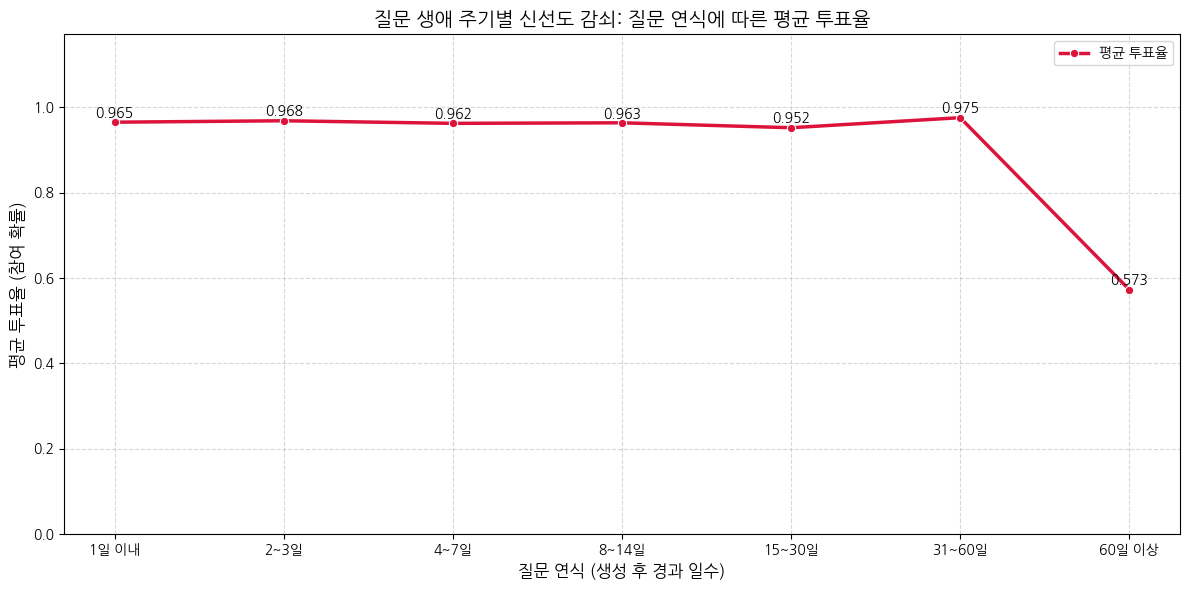

In [ ]:
# # 날짜형 변환 및 경과 일수(Question Age) 계산
# df_filtered['created_at_question'] = pd.to_datetime(df_filtered['created_at_question'])
# df_filtered['created_at_piece'] = pd.to_datetime(df_filtered['created_at_piece'])
# df_filtered['question_age_days'] = (df_filtered['created_at_piece'] - df_filtered['created_at_question']).dt.days

# # 음수 값(데이터 오차 등으로 노출일이 생성일보다 앞선 경우) 예외 처리
# df_filtered = df_filtered[df_filtered['question_age_days'] >= 0].copy()

# # 질문의 생애 주기 구간(Bins) 설정
# # 질문이 태어난 직후의 변화를 세밀하게 보기 위해 초기 구간을 촘촘하게 설정합니다.
# bins = [-1, 1, 3, 7, 14, 30, 60, float('inf')]
# labels = ['1일 이내', '2~3일', '4~7일', '8~14일', '15~30일', '31~60일', '60일 이상']

# df_filtered['age_group'] = pd.cut(df_filtered['question_age_days'], bins=bins, labels=labels)

# # 생애 주기 구간별 총 노출 수 및 평균 투표율(Vote Rate) 집계
# freshness_decay_df = df_filtered.groupby('age_group', observed=False).agg(
#     total_exposure=('id_piece', 'count'),       # 구간별 총 노출 횟수
#     vote_count=('is_voted', 'sum'),            # 구간별 총 투표 수
#     vote_rate=('is_voted', 'mean')             # 평균 투표율 (참여율)
# ).reset_index()

# print("--- 생애 주기별 투표율 감쇠 집계 결과 ---")
# print(freshness_decay_df)

# # 신선도 감쇠 곡선(Freshness Decay Curve) 시각화
# plt.figure(figsize=(12, 6))

# # 투표율 선 그래프 그리기
# ax1 = sns.lineplot(
#     data=freshness_decay_df,
#     x='age_group',
#     y='vote_rate',
#     marker='o',
#     color='crimson',
#     linewidth=2.5,
#     label='평균 투표율'
# )

# plt.title('질문 생애 주기별 신선도 감쇠: 질문 연식에 따른 평균 투표율', fontsize=14, fontweight='bold')
# plt.xlabel('질문 연식 (생성 후 경과 일수)', fontsize=12)
# plt.ylabel('평균 투표율 (참여 확률)', fontsize=12)
# plt.ylim(0, max(freshness_decay_df['vote_rate']) * 1.2)
# plt.grid(True, linestyle='--', alpha=0.5)

# # 값 데이터 라벨 추가
# for i, row in freshness_decay_df.iterrows():
#     ax1.text(i, row['vote_rate'] + 0.01, f"{row['vote_rate']:.3f}",
#              color='black', ha='center', fontsize=10)

# plt.tight_layout()
# plt.show()

--- 60일 이후 세분화된 생애 주기별 투표율 감쇠 결과 ---
  age_group_detailed  total_exposure  vote_count  vote_rate
0              1일 이내          137653      132803   0.964766
1               2~3일          129924      125780   0.968104
2               4~7일          197520      190025   0.962054
3              8~14일          275288      265191   0.963322
4             15~30일          149141      141954   0.951811
5             31~60일          365444      356435   0.975348
6             61~90일            4628        3283   0.709378
7            91~120일            1910         855   0.447644
8            120일 이상            2841        1234   0.434354


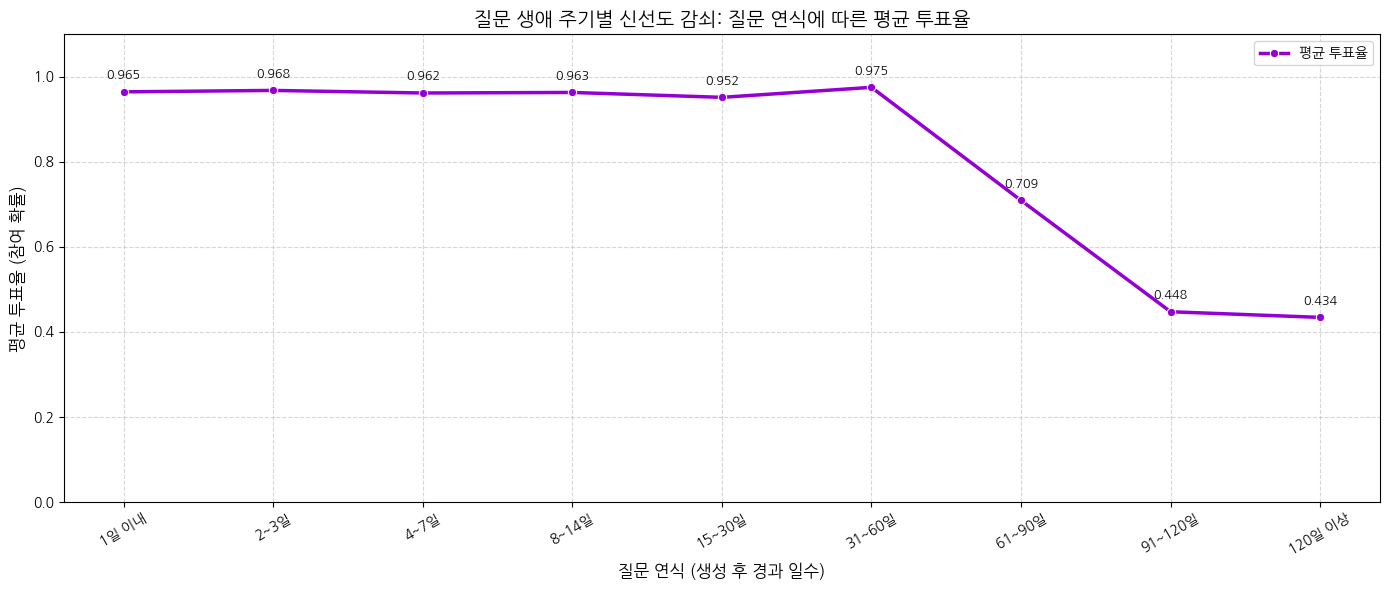

In [ ]:
# # 60일 이후 구간을 더 세분화한 Bins 설정 (예: 60~90일, 90~120일, 120일 이상)
# bins_detailed = [-1, 1, 3, 7, 14, 30, 60, 90, 120, float('inf')]
# labels_detailed = ['1일 이내', '2~3일', '4~7일', '8~14일', '15~30일', '31~60일', '61~90일', '91~120일', '120일 이상']

# df_filtered['age_group_detailed'] = pd.cut(df_filtered['question_age_days'], bins=bins_detailed, labels=labels_detailed)

# # 세분화된 구간별 집계
# freshness_decay_detailed = df_filtered.groupby('age_group_detailed', observed=False).agg(
#     total_exposure=('id_piece', 'count'),
#     vote_count=('is_voted', 'sum'),
#     vote_rate=('is_voted', 'mean')
# ).reset_index()

# print("--- 60일 이후 세분화된 생애 주기별 투표율 감쇠 결과 ---")
# print(freshness_decay_detailed)

# # 세분화된 신선도 감쇠 곡선 시각화
# plt.figure(figsize=(14, 6))

# ax2 = sns.lineplot(
#     data=freshness_decay_detailed,
#     x='age_group_detailed',
#     y='vote_rate',
#     marker='o',
#     color='darkviolet',
#     linewidth=2.5,
#     label='평균 투표율'
# )

# plt.title('질문 생애 주기별 신선도 감쇠: 질문 연식에 따른 평균 투표율', fontsize=14, fontweight='bold')
# plt.xlabel('질문 연식 (생성 후 경과 일수)', fontsize=12)
# plt.ylabel('평균 투표율 (참여 확률)', fontsize=12)
# plt.ylim(0, 1.1)
# plt.grid(True, linestyle='--', alpha=0.5)

# # 값 데이터 라벨 추가
# for i, row in freshness_decay_detailed.iterrows():
#     ax2.text(i, row['vote_rate'] + 0.03, f"{row['vote_rate']:.3f}",
#              color='black', ha='center', fontsize=9)

# plt.xticks(rotation=30)
# plt.tight_layout()
# plt.show()

## 텍스트 감성분석

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import urllib.request
import seaborn as sns

font_path = "/tmp/Malgun.ttf"
urllib.request.urlretrieve("https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf", font_path)

# 최신 matplotlib 버전의 표준 메서드(addfont) 사용
fm.fontManager.addfont(font_path)
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

In [ ]:
# 투표 기록 테이블(전처리된)
accounts_userquestionrecord = pd.read_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/accounts_userquestionrecord_cleaned.csv')
accounts_userquestionrecord

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
0,771777,C,2023-04-28 12:27:49,849469,252,849436,998458,0,N,2023-04-28 12:27:49,0,0
1,771800,C,2023-04-28 12:28:02,849446,244,849436,998459,0,N,2023-04-28 12:28:02,0,0
2,771812,C,2023-04-28 12:28:09,849454,183,849436,998460,1,N,2023-04-28 12:28:09,0,0
3,771828,C,2023-04-28 12:28:16,847375,101,849436,998461,0,N,2023-04-28 12:28:16,0,0
4,771851,C,2023-04-28 12:28:26,849477,209,849436,998462,1,N,2023-04-28 12:28:26,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1213921,161666166,C,2024-05-07 11:29:07,945560,2614,1001607,190864020,1,N,2024-05-07 11:29:07,0,0
1213922,161666461,C,2024-05-08 01:34:56,850774,1679,855525,200139931,0,N,2024-05-08 01:34:56,0,0
1213923,161666462,C,2024-05-08 01:35:02,855509,2605,855525,200139932,0,N,2024-05-08 01:35:02,0,0
1213924,161666463,C,2024-05-08 01:36:00,855526,3801,855525,200139933,0,N,2024-05-08 01:36:00,0,0


In [ ]:
# 질문 내용 테이블(전처리된)
questions = pd.read_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_cleaned.csv')
questions

,id,question_text,created_at
0,99,가장 신비한 매력이 있는 사람은?,2023-03-31 15:22:53
1,100,"""이 사람으로 한 번 살아보고 싶다"" 하는 사람은?",2023-03-31 15:22:53
2,101,미래의 틱톡커는?,2023-03-31 15:22:54
3,102,여기서 제일 특이한 친구는?,2023-03-31 15:22:54
4,103,가장 지켜주고 싶은 사람은?,2023-03-31 15:22:55
...,...,...,...
3898,4112,MBTI 제일 반전이였던 친구는?,2023-06-06 06:10:17
3899,4280,너에게 칭찬을 받는다면 가장 기분 좋을 것 같아!,2023-06-06 06:15:40
3900,4313,사달라는거 다 사줄 것 같은 사람은?,2023-06-06 06:15:41
3901,4412,"할머니, 할아버지가 돼도 이 친구만큼은 연락하고 지낼 것 같아!",2023-06-06 06:15:42


In [ ]:
# 질문 테이블(전처리된)
questionpiece = pd.read_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/polls_question_piece_cleaned.csv')
questionpiece

,id,is_voted,created_at,question_id,is_skipped
0,998458,1,2023-04-28 12:27:22,252,0
1,998459,1,2023-04-28 12:27:22,244,0
2,998460,1,2023-04-28 12:27:22,183,0
3,998461,1,2023-04-28 12:27:22,101,0
4,998462,1,2023-04-28 12:27:22,209,0
...,...,...,...,...,...
1264344,208385226,0,2024-05-07 11:32:30,960,0
1264345,208385227,0,2024-05-07 11:32:30,1402,0
1264346,208385228,0,2024-05-07 11:32:30,1676,0
1264347,208385229,0,2024-05-07 11:32:30,3115,0


In [ ]:
# filtered_df = accounts_userquestionrecord[accounts_userquestionrecord['id'] == 771777]
# print(filtered_df)

       id status           created_at  chosen_user_id  question_id  user_id  \
0  771777      C  2023-04-28 12:27:49          849469          252   849436   

   question_piece_id  has_read answer_status    answer_updated_at  \
0             998458         0             N  2023-04-28 12:27:49   

   report_count  opened_times  
0             0             0  


In [ ]:
# find = questions[questions['id'] == 252]
# print(find)

      id           question_text           created_at
153  252  손이 가장 이쁘게 생겼을거 같은 사람은?  2023-04-01 11:09:27


In [ ]:
# questionpiece[questionpiece['id'] == 998458]

,id,is_voted,created_at,question_id,is_skipped
0,998458,1,2023-04-28 12:27:22,252,0


In [ ]:
# accounts_userquestionrecord[accounts_userquestionrecord['user_id'] == 849436]

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
0,771777,C,2023-04-28 12:27:49,849469,252,849436,998458,0,N,2023-04-28 12:27:49,0,0
1,771800,C,2023-04-28 12:28:02,849446,244,849436,998459,0,N,2023-04-28 12:28:02,0,0
2,771812,C,2023-04-28 12:28:09,849454,183,849436,998460,1,N,2023-04-28 12:28:09,0,0
3,771828,C,2023-04-28 12:28:16,847375,101,849436,998461,0,N,2023-04-28 12:28:16,0,0
4,771851,C,2023-04-28 12:28:26,849477,209,849436,998462,1,N,2023-04-28 12:28:26,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1162459,146144869,C,2023-06-04 13:49:46,849469,245,849436,24084436,0,N,2023-06-04 13:49:46,0,0
1173788,149418359,C,2023-06-06 12:48:22,878054,2151,849436,187930341,0,N,2023-06-06 12:48:22,0,0
1173791,149419023,C,2023-06-06 12:48:44,849559,2615,849436,187930343,0,N,2023-06-06 12:48:44,0,0
1173794,149419647,C,2023-06-06 12:49:06,849559,2378,849436,187930346,0,N,2023-06-06 12:49:06,0,0


In [ ]:
# # 만약 created_at이 문자열 형태라면 날짜 문자열 매칭으로 조회
# # (시간까지 포함된 문자열일 수 있으므로 '2023-04-28'로 시작하는 데이터 필터링)
# # condition = accounts_userquestionrecord['created_at'].astype(str).str.startswith('2023-04-28')

# # 만약 created_at이 이미 datetime 타입이라면 아래 주석 처럼 날짜 비교를 할 수도 있습니다.
# condition = (accounts_userquestionrecord['created_at'] <= '2023-04-28 12:30:00') & (accounts_userquestionrecord['user_id'] == 849436)

# # 조건에 맞는 데이터프레임 추출
# filtered_df = accounts_userquestionrecord[condition]

# # 데이터 갯수 확인
# print(f"조건에 맞는 데이터 갯수: {len(filtered_df)}")

# # 데이터 조회 (상위 몇 개 또는 전체)
# print(filtered_df)

조건에 맞는 데이터 갯수: 10
        id status           created_at  chosen_user_id  question_id  user_id  \
0   771777      C  2023-04-28 12:27:49          849469          252   849436   
1   771800      C  2023-04-28 12:28:02          849446          244   849436   
2   771812      C  2023-04-28 12:28:09          849454          183   849436   
3   771828      C  2023-04-28 12:28:16          847375          101   849436   
4   771851      C  2023-04-28 12:28:26          849477          209   849436   
5   771864      C  2023-04-28 12:28:32          849670          239   849436   
7   771908      C  2023-04-28 12:28:55          849446          146   849436   
10  771940      I  2023-04-28 12:29:13          849634          297   849436   
11  771952      C  2023-04-28 12:29:21          849442          294   849436   
14  771974      C  2023-04-28 12:29:33          849453          201   849436   

    question_piece_id  has_read answer_status    answer_updated_at  \
0              998458         0

In [ ]:
questions

,id,question_text,created_at
0,99,가장 신비한 매력이 있는 사람은?,2023-03-31 15:22:53
1,100,"""이 사람으로 한 번 살아보고 싶다"" 하는 사람은?",2023-03-31 15:22:53
2,101,미래의 틱톡커는?,2023-03-31 15:22:54
3,102,여기서 제일 특이한 친구는?,2023-03-31 15:22:54
4,103,가장 지켜주고 싶은 사람은?,2023-03-31 15:22:55
...,...,...,...
3898,4112,MBTI 제일 반전이였던 친구는?,2023-06-06 06:10:17
3899,4280,너에게 칭찬을 받는다면 가장 기분 좋을 것 같아!,2023-06-06 06:15:40
3900,4313,사달라는거 다 사줄 것 같은 사람은?,2023-06-06 06:15:41
3901,4412,"할머니, 할아버지가 돼도 이 친구만큼은 연락하고 지낼 것 같아!",2023-06-06 06:15:42


In [ ]:
questionpiece

,id,is_voted,created_at,question_id,is_skipped
0,998458,1,2023-04-28 12:27:22,252,0
1,998459,1,2023-04-28 12:27:22,244,0
2,998460,1,2023-04-28 12:27:22,183,0
3,998461,1,2023-04-28 12:27:22,101,0
4,998462,1,2023-04-28 12:27:22,209,0
...,...,...,...,...,...
1264344,208385226,0,2024-05-07 11:32:30,960,0
1264345,208385227,0,2024-05-07 11:32:30,1402,0
1264346,208385228,0,2024-05-07 11:32:30,1676,0
1264347,208385229,0,2024-05-07 11:32:30,3115,0


In [ ]:
# polls_question과 polls_questionpiece 조인 (질문 기본 정보와 보기/조각 정보 결합)
# 질문 테이블의 id와 questionpiece 테이블의 question_id를 기준으로 결합합니다.
question_full_df = pd.merge(
    questions,
    questionpiece,
    left_on='id',
    right_on='question_id',
    how='right',
    suffixes=('_question', '_piece')
)

# 결합된 데이터 확인
print(f"조인 완료된 데이터 갯수: {len(question_full_df)}")
print(question_full_df.head())

조인 완료된 데이터 갯수: 1264349
   id_question            question_text  created_at_question  id_piece  \
0          252   손이 가장 이쁘게 생겼을거 같은 사람은?  2023-04-01 11:09:27    998458   
1          244    대학교에서 학생회장할 것 같은 사람은?  2023-04-01 11:09:26    998459   
2          183  나의 자존감을 가장 많이 높여줬던 사람은?  2023-04-01 11:09:14    998460   
3          101                미래의 틱톡커는?  2023-03-31 15:22:54    998461   
4          209        항상 좋은 냄새가 나는 사람은?  2023-04-01 11:09:20    998462   

   is_voted     created_at_piece  question_id  is_skipped  
0         1  2023-04-28 12:27:22          252           0  
1         1  2023-04-28 12:27:22          244           0  
2         1  2023-04-28 12:27:22          183           0  
3         1  2023-04-28 12:27:22          101           0  
4         1  2023-04-28 12:27:22          209           0  


In [ ]:
# accounts_userquestionrecord를 기준으로 하고, 두 개의 키(['question_id', 'question_piece_id'])를 매칭하여 결합
final_analysis_df = pd.merge(
    accounts_userquestionrecord,
    question_full_df,
    left_on=['question_id', 'question_piece_id'],
    right_on=['id_question', 'id_piece'], # question_full_df 생성 시 설정된 컬럼명에 맞게 조정 필요
    how='inner',
    suffixes=('_question', '_piece')
)

# 결합 완료된 데이터 및 매칭 여부 확인
print(f"조인 완료된 데이터 갯수: {len(final_analysis_df)}")
print(final_analysis_df)

# 이후 결합되지 못한(매칭 실패한) 데이터 조회용 코드 (예시)
# unmapped_records = final_analysis_df[final_analysis_df['id_question'].isnull()]

조인 완료된 데이터 갯수: 1199797
                id status           created_at  chosen_user_id  \
0           771777      C  2023-04-28 12:27:49          849469   
1           771800      C  2023-04-28 12:28:02          849446   
2           771812      C  2023-04-28 12:28:09          849454   
3           771828      C  2023-04-28 12:28:16          847375   
4           771851      C  2023-04-28 12:28:26          849477   
...            ...    ...                  ...             ...   
1199792  161666166      C  2024-05-07 11:29:07          945560   
1199793  161666461      C  2024-05-08 01:34:56          850774   
1199794  161666462      C  2024-05-08 01:35:02          855509   
1199795  161666463      C  2024-05-08 01:36:00          855526   
1199796  161666464      C  2024-05-08 01:36:18          874566   

         question_id_question  user_id  question_piece_id  has_read  \
0                         252   849436             998458         0   
1                         244   849436    

In [ ]:
final_analysis_df['question_text']

,question_text
0,손이 가장 이쁘게 생겼을거 같은 사람은?
1,대학교에서 학생회장할 것 같은 사람은?
2,나의 자존감을 가장 많이 높여줬던 사람은?
3,미래의 틱톡커는?
4,항상 좋은 냄새가 나는 사람은?


In [ ]:
# !pip install konlpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 56.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 438.5/438.5 kB 25.6 MB/s eta 0:00:00


In [ ]:
!pip install sentence-transformers scikit-learn

### 문장 임베딩 & K-means 군집화

In [ ]:
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans

# 고유 질문 텍스트 추출 및 결측치 제거
unique_texts = final_analysis_df['question_text'].dropna().unique().tolist()
print(f"총 고유 질문 개수: {len(unique_texts)}")

# 한국어 문장 임베딩 모델 로드 (가볍고 성능이 검증된 Ko-SBERT 모델)
model = SentenceTransformer('jhgan/ko-sroberta-multitask')

# 텍스트를 고차원 숫자 벡터로 변환 (임베딩)
print("문장 임베딩 생성 중...")
embeddings = model.encode(unique_texts, show_progress_bar=True)

총 고유 질문 개수: 3902


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.86k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/744 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

문장 임베딩 생성 중...


Batches:   0%|          | 0/122 [00:00<?, ?it/s]

k=2 완료 (실루엣 점수: 0.0425)
k=3 완료 (실루엣 점수: 0.0359)
k=4 완료 (실루엣 점수: 0.0325)
k=5 완료 (실루엣 점수: 0.0319)
k=6 완료 (실루엣 점수: 0.0305)
k=7 완료 (실루엣 점수: 0.0295)
k=8 완료 (실루엣 점수: 0.0309)
k=9 완료 (실루엣 점수: 0.0316)
k=10 완료 (실루엣 점수: 0.0275)


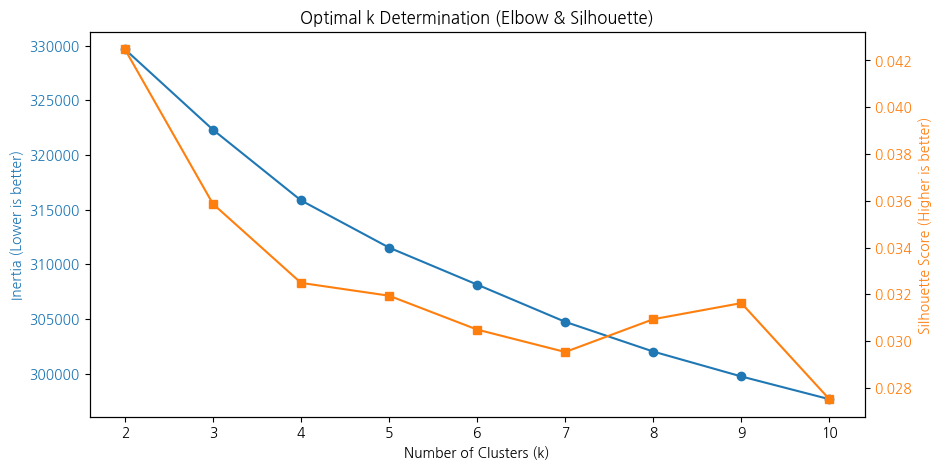

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 임베딩 벡터가 이미 생성되어 있다고 가정 (embeddings 변수)
inertia = []
silhouette_scores = []
K_range = range(2, 11)  # 2부터 10까지 테스트

for k in K_range:
  # K-Means 모델 학습
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  cluster_labels = kmeans.fit_predict(embeddings)

  # 엘보우 기법을 위한 Inertia (응집도 지표) 저장
  inertia.append(kmeans.inertia_)

  # 3. 실루엣 계수 계산 (데이터 간 응집도와 분리도 측정)
  score = silhouette_score(embeddings, cluster_labels)
  silhouette_scores.append(score)
  print(f'k={k} 완료 (실루엣 점수: {score:.4f})')

# 시각화 그래프 그리기
fig, ax1 = plt.subplots(figsize=(10, 5))

# 엘보우 그래프 (Inertia)
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (Lower is better)', color='tab:blue')
ax1.plot(K_range, inertia, marker='o', color='tab:blue', label='Inertia')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# 실루엣 계수 그래프 (Silhouette Score)
ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score (Higher is better)', color='tab:orange')
ax2.plot(
    K_range,
    silhouette_scores,
    marker='s',
    color='tab:orange',
    label='Silhouette Score',
)
ax2.tick_params(axis='y', labelcolor='tab:orange')

plt.title('Optimal k Determination (Elbow & Silhouette)')
plt.show()

In [ ]:
from sentence_transformers import SentenceTransformer

# K-Means 군집화 수행 (질문 성격에 따라 5개 그룹으로 분류)
num_clusters = 5
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(embeddings)

# 결과를 데이터프레임으로 묶기
cluster_df = pd.DataFrame({
    'question_text': unique_texts,
    'cluster': cluster_labels
})

# 각 군집별 대표 질문 5개씩 출력 (어떤 주제로 묶였는지 확인)
for i in range(num_clusters):
    print(f"\n--- Cluster {i} 대표 질문 ---")
    sample_questions = cluster_df[cluster_df['cluster'] == i]['question_text'].head(5)
    for q in sample_questions:
        print(f"- {q}")


--- Cluster 0 대표 질문 ---
- 손이 가장 이쁘게 생겼을거 같은 사람은?
- 나의 자존감을 가장 많이 높여줬던 사람은?
- 항상 좋은 냄새가 나는 사람은?
- 여기서 가장 귀여운 사람은?
- 피부가 제일 좋은거 같은 사람은?

--- Cluster 1 대표 질문 ---
- 대학교에서 학생회장할 것 같은 사람은?
- 미래의 틱톡커는?
- 단기기억력 대박인 사람은?
- 공부를 남에게 잘 가르쳐줄 거 같은 사람은?
- 숨겨진 댄싱 머신이라고 생각하는 사람은?

--- Cluster 2 대표 질문 ---
- 내 친구에게 소개시켜주고 싶은 친구 한명은?
- 나에게 항상 응원과 용기를 주는 사람은?
- 여기서 제일 특이한 친구는?
- 친구들에게 생일선물을 가장 많이 받을거 같은 사람은?
- 뭔가 스며드는 친구는?

--- Cluster 3 대표 질문 ---
- vote
- 얘와 함께라면 어떤 상황이든 죽지는 않을 것 같다!
- 틱톡 팔로워가 가장 많을 것 같은 사람
- 회사에 들어가면 매일 깔끔한 칼정장에 구두를 신고 향수를 뿌릴 것 같은 사람은?
- 트렌드세터

--- Cluster 4 대표 질문 ---
- 이별 후 자기가 먼저 화해메시지 보낼 것 같은 사람?
- 첫 키스를 가장 먼저 해봤을 것 같은 사람은?
- 무인도에 떨어진다면 같이 있고싶은 사람은?
- 10년 후 미래에 같이 여행가보고 싶은 사람은?
- 가장 이성친구가 많을 것 같은 사람은?


### 명사/형용사 기반 빈도분석 & 노출 빈도 상위 텍스트

In [ ]:
from collections import Counter
import re
from konlpy.tag import Okt

okt = Okt()

# 1. 고유 질문(question_text)만 추출하여 결측치 제거
unique_questions = final_analysis_df['question_text'].dropna().unique()
print(f"분석 대상 고유 질문 수: {len(unique_questions)}")

# 2. 명사/형용사 빈도 분석
all_words = []
for text in unique_questions:
  clean_text = re.sub(r'[^가-힣a-zA-Z0-9\s]', '', text)
  pos_results = okt.pos(clean_text, norm=True, stem=True)
  # 2글자 이상의 명사(Noun), 형용사(Adjective)만 추출
  words = [
      word for word, pos in pos_results if pos in ['Noun', 'Adjective'] and len(word) > 1
  ]
  all_words.extend(words)

word_counts = Counter(all_words)
print("--- [방법 1] 명사/형용사 빈도 상위 50개 단어 ---")
for word, count in word_counts.most_common(50):
  print(f"{word}: {count}회")

# 3. [방법 2] 데이터프레임 내에서 질문별 노출 빈도(데이터 건수 기준)가 높은 상위 질문 텍스트 확인
top_exposed_questions = final_analysis_df['question_text'].value_counts().head(20)
print("\n--- [방법 2] 가장 많이 노출된 상위 질문 텍스트 Top 20 ---")
for text, cnt in top_exposed_questions.items():
  print(f"[노출 {cnt}건] {text}")

분석 대상 고유 질문 수: 3902
--- [방법 1] 명사/형용사 빈도 상위 50개 단어 ---
사람: 2864회
같다: 2124회
친구: 981회
가장: 925회
제일: 347회
있다: 330회
좋다: 122회
좋아하다: 110회
많다: 104회
먼저: 59회
학교: 53회
보고: 52회
예쁘다: 49회
매력: 41회
연락: 41회
노래: 40회
나중: 37회
연애: 36회
지금: 36회
생각: 35회
없다: 35회
시간: 33회
공부: 32회
귀엽다: 31회
생일: 31회
애인: 31회
항상: 30회
누구: 30회
미래: 29회
여기: 29회
인스타: 29회
매일: 28회
혼자: 28회
결혼: 27회
선물: 25회
게임: 25회
노래방: 24회
하루: 24회
가면: 24회
카페: 24회
바로: 24회
고백: 24회
머리: 23회
높다: 22회
궁금하다: 22회
이쁘다: 21회
인생: 21회
인기: 21회
사진: 21회
재밌다: 20회

--- [방법 2] 가장 많이 노출된 상위 질문 텍스트 Top 20 ---
[노출 1994건] 처음 보는 사람과 가장 빨리 친해질 것 같은 사람은?
[노출 1982건] 모든 사람과 잘 지낼 것 같은 사람은?
[노출 1979건] 축제에서 공연을 제일 잘 할거 같은 사람은?
[노출 1969건] 앞으로의 인생을 가장 재미있게 살것 같은 사람은?
[노출 1948건] 반려동물과 가장 잘 지낼거 같은 사람은?
[노출 1945건] vote
[노출 1942건] 대학교에서 학생회장할 것 같은 사람은?
[노출 1936건] 여기서 제일 특이한 친구는?
[노출 1926건] 흰티에 청바지가 잘 어울릴것 같은 사람은?
[노출 1926건] 숨겨진 댄싱 머신이라고 생각하는 사람은?
[노출 1910건] 자신감이 제일 높을거 같은 사람은?
[노출 1910건] 어떤 모임에서도 항상 리드를 할 것 같은 사람은?
[노출 1902건] 성격이 가장 시원시원한 사람은?
[노출 1895건] 무서운 놀이기구를 제일 잘탈것 같은 사람은?
[노출 1895건] 틱톡 팔로워가

In [ ]:
# 앞서 정의한 비즈니스 딕셔너리 기반 키워드 규칙 설정
# (빈도 분석 결과를 참고하여 실제 데이터에 맞게 키워드를 추가/수정하세요)
category_dict = {
    '연애/호감': ['이상형', '고백', '남친', '여친', '사귀', '좋아하는', '썸', '사랑', '첫눈', '호감'],
    '외모/인기': ['인기', '얼굴', '외모', '스타일', '몸매', '키', '존잘', '존예', '옷차림', '매력'],
    '성격/관계': ['성격', '착한', '의리', '비밀', '친구', '손절', '배신', '멘탈', '인성', '싸움'],
    '학교생활': ['시험', '공부', '급식', '지각', '학교', '반', '선생님', '수업', '체육대회', '성적'],
    '재미/상황형': ['무인도', '로또', '시간', '초능력', '세계', '만약', '라면', '이상한', '밸런스']
}

# 키워드 매칭을 통해 카테고리를 부여하는 함수 정의
def classify_by_rule(text):
    if pd.isna(text):
        return '기타'

    for category, keywords in category_dict.items():
        # 질문 텍스트 안에 키워드가 하나라도 포함되어 있는지 확인
        if any(keyword in text for keyword in keywords):
            return category

    return '기타' # 어떤 규칙에도 걸리지 않은 문장

# 전체 데이터프레임에 카테고리 자동 분류 적용
final_analysis_df['category'] = final_analysis_df['question_text'].apply(classify_by_rule)

# 카테고리별 분류 결과 확인 (비율 및 건수)
print("--- 카테고리별 분류 결과 (%) ---")
print(final_analysis_df['category'].value_counts(normalize=True) * 100)

print("\n--- 카테고리별 데이터 건수 ---")
print(final_analysis_df['category'].value_counts())

# '기타'로 분류된 데이터만 따로 추출하여 어떤 단어들이 남았는지 확인 (2차 딕셔너리 보완용)
other_df = final_analysis_df[final_analysis_df['category'] == '기타']
print(f"\n'기타'로 분류된 질문 수: {len(other_df)}")
print("--- '기타' 그룹 샘플 질문 10개 ---")
print(other_df['question_text'].dropna().head(10).tolist())

# 추후 엑셀 검수 및 수동 보정을 위한 CSV 파일 저장
# final_analysis_df.to_csv('final_analysis_with_category.csv', index=False, encoding='utf-8-sig')

--- 카테고리별 분류 결과 (%) ---
category
기타        69.770553
성격/관계     17.801428
외모/인기      4.213713
학교생활       3.512428
연애/호감      2.570018
재미/상황형     2.131861
Name: proportion, dtype: float64

--- 카테고리별 데이터 건수 ---
category
기타        837105
성격/관계     213581
외모/인기      50556
학교생활       42142
연애/호감      30835
재미/상황형     25578
Name: count, dtype: int64

'기타'로 분류된 질문 수: 837105
--- '기타' 그룹 샘플 질문 10개 ---
['손이 가장 이쁘게 생겼을거 같은 사람은?', '나의 자존감을 가장 많이 높여줬던 사람은?', '미래의 틱톡커는?', '항상 좋은 냄새가 나는 사람은?', '여기서 가장 귀여운 사람은?', '피부가 제일 좋은거 같은 사람은?', '본인과 가장 어울리는 옷을 입는 사람은?', '아이큐가 제일 높을것 같은 사람은?', '단기기억력 대박인 사람은?', '공과사를 가장 구분 잘할거 같은 사람은?']


In [ ]:
import re
from collections import Counter

# '기타'로 분류된 데이터 중 고유 질문만 추출 (속도 향상 및 중복 방지)
other_unique_questions = final_analysis_df[final_analysis_df['category'] == '기타']['question_text'].dropna().unique()

# 형태소 분석기 없이 띄어쓰기 기반으로 단어 빠르게 쪼개기
other_words = []
for text in other_unique_questions:
    clean_text = re.sub(r'[^가-힣a-zA-Z0-9\s]', '', text)
    # 2글자 이상인 단어만 추출
    other_words.extend([w for w in clean_text.split() if len(w) > 1])

# '기타' 그룹에서 가장 많이 쓰인 단어 Top 50 확인
word_counts = Counter(other_words)
print("--- '기타' 그룹 누락 키워드 Top 50 ---")
for word, count in word_counts.most_common(50):
    print(f"{word}: {count}회")

--- '기타' 그룹 누락 키워드 Top 50 ---
사람은: 1640회
같은: 1360회
사람: 676회
가장: 638회
싶은: 259회
제일: 257회
같이: 148회
많이: 96회
있을: 76회
어울리는: 67회
좋아할: 54회
있는: 46회
가고: 37회
먼저: 36회
좋은: 34회
하고: 32회
하는: 31회
먹을: 31회
어울릴: 31회
나중에: 30회
좋을: 30회
내가: 29회
받을: 25회
많을: 24회
잘할: 22회
인스타: 21회
여기서: 19회
보고: 19회
지금: 19회
많은: 18회
매일: 18회
혼자: 18회
예쁜: 17회
나를: 17회
미래에: 16회
자주: 16회
가까울: 16회
닮은: 15회
같은사람: 15회
항상: 14회
빨리: 14회
집에서: 14회
귀여운: 13회
잘하는: 13회
노래: 13회
좋겠는: 12회
가서: 12회
함께: 12회
나에게: 11회
있으면: 11회


### 기타 추가

In [ ]:
import pandas as pd
import re
from collections import Counter

# 확장된 키워드 딕셔너리 설정 (누락된 표현 추가 반영)
category_dict = {
    '연애/호감': ['이상형', '고백', '남친', '여친', '사귀', '좋아하는', '썸', '사랑', '첫눈', '호감', '설레'],
    '외모/인기': ['인기', '얼굴', '외모', '스타일', '몸매', '키', '존잘', '존예', '옷차림', '매력', '예쁜', '귀여운', '귀엽', '피부', '옷', '냄새', '잘생긴'],
    '성격/관계': ['성격', '착한', '의리', '비밀', '친구', '손절', '배신', '멘탈', '인성', '싸움', '자존감', '공과사', '닮은'],
    '학교생활': ['시험', '공부', '급식', '지각', '학교', '반', '선생님', '수업', '체육대회', '성적', '아이큐', '기억력', '인스타'],
    '재미/상황형': ['무인도', '로또', '시간', '초능력', '세계', '만약', '라면', '이상한', '밸런스', '틱톡커', '유튜버', '노래', '먹을', '가고', '집에서']
}

# 키워드 매칭 함수 정의
def classify_by_rule(text):
    if pd.isna(text):
        return '기타'

    for category, keywords in category_dict.items():
        if any(keyword in text for keyword in keywords):
            return category

    return '기타'

# 전체 데이터프레임에 카테고리 자동 분류 적용
final_analysis_df['category'] = final_analysis_df['question_text'].apply(classify_by_rule)

# 카테고리별 분류 결과 확인
print("--- 카테고리별 분류 결과 (%) ---")
print(final_analysis_df['category'].value_counts(normalize=True) * 100)

print("\n--- 카테고리별 데이터 건수 ---")
print(final_analysis_df['category'].value_counts())

# 문장 구조 불용어(Stopwords) 정의
stopwords = {
    '사람은', '같은', '사람', '가장', '싶은', '제일', '같이', '많이', '있을', '있는',
    '가고', '먼저', '좋은', '하고', '하는', '먹을', '나중에', '좋을', '내가', '받을',
    '많을', '잘할', '여기서', '보고', '지금', '많은', '매일', '혼자', '나를', '미래에',
    '자주', '가까울', '항상', '빨리', '집에서', '가서', '함께', '나에게', '있으면'
}

# '기타' 데이터 중 고유 질문 추출 후 불용어 제외 단어 빈도 분석
other_unique_questions = final_analysis_df[final_analysis_df['category'] == '기타']['question_text'].dropna().unique()

filtered_words = []
for text in other_unique_questions:
    clean_text = re.sub(r'[^가-힣a-zA-Z0-9\s]', '', text)
    words = clean_text.split()
    # 2글자 이상이면서 불용어 및 '~는'으로 끝나는 구조어 제외
    valid_words = [w for w in words if len(w) > 1 and w not in stopwords and not w.endswith('는')]
    filtered_words.extend(valid_words)

word_counts = Counter(filtered_words)
print("\n--- 불용어 제거 후 '기타' 그룹 잔여 키워드 Top 50 ---")
for word, count in word_counts.most_common(50):
    print(f"{word}: {count}회")

--- 카테고리별 분류 결과 (%) ---
category
기타        61.389302
성격/관계     17.884942
외모/인기      7.784567
재미/상황형     5.902582
학교생활       4.290976
연애/호감      2.747631
Name: proportion, dtype: float64

--- 카테고리별 데이터 건수 ---
category
기타        736547
성격/관계     214583
외모/인기      93399
재미/상황형     70819
학교생활       51483
연애/호감      32966
Name: count, dtype: int64

--- 불용어 제거 후 '기타' 그룹 잔여 키워드 Top 50 ---
좋아할: 52회
어울릴: 30회
같은사람: 12회
바로: 11회
모든: 10회
커서: 10회
궁금한: 10회
해줄: 9회
먹고: 9회
찍을: 9회
오래: 9회
나올: 9회
다닐: 9회
같은사람은: 9회
말을: 8회
사람과: 8회
싶어: 8회
전생에: 8회
자기: 8회
심할: 8회
나랑: 8회
못할: 8회
늦게: 8회
일이: 7회
만나고: 7회
주말에: 7회
첫인상이: 7회
모습이: 7회
잠을: 7회
높은: 7회
보면: 7회
있다: 7회
머리: 7회
나한테: 7회
생긴: 7회
열심히: 7회
주고: 7회
믿을: 7회
빠를: 7회
연락: 7회
하면: 7회
10년: 6회
친해지고: 6회
목소리가: 6회
머리가: 6회
이쁜: 6회
있다면: 6회
연락할: 6회
연애를: 6회
다시: 6회


In [ ]:
import pandas as pd
import re
from collections import Counter

# 어간 및 확장 키워드 중심의 정교화된 딕셔너리 설정
category_dict = {
    '연애/호감': [
        '이상형', '고백', '남친', '여친', '사귀', '좋아', '썸', '사랑', '첫눈', '호감', '설레', '연애', '첫인상'
    ],
    '외모/인기': [
        '인기', '얼굴', '외모', '스타일', '몸매', '키', '존잘', '존예', '옷차림', '매력',
        '예쁜', '귀여운', '귀엽', '피부', '옷', '냄새', '잘생긴', '머리', '목소리', '이쁜'
    ],
    '성격/관계': [
        '성격', '착한', '의리', '비밀', '친구', '손절', '배신', '멘탈', '인성', '싸움',
        '자존감', '공과사', '닮은', '친해', '믿을', '사람과'
    ],
    '학교생활': [
        '시험', '공부', '급식', '지각', '학교', '반', '선생님', '수업', '체육대회', '성적',
        '아이큐', '기억력', '인스타', '다닐', '늦게'
    ],
    '재미/상황형': [
        '무인도', '로또', '시간', '초능력', '세계', '만약', '라면', '이상한', '밸런스',
        '틱톡커', '유튜버', '노래', '먹을', '먹고', '가고', '집에서', '전생', '주말',
        '커서', '찍을', '10년', '나중에'
    ]
}

# 키워드 매칭 함수 (어간이나 부분 문자열이 포함되면 해당 카테고리로 분류)
def classify_by_rule(text):
    if pd.isna(text):
        return '기타'

    for category, keywords in category_dict.items():
        # 텍스트 안에 키워드가 포함되어 있는지 확인
        if any(keyword in text for keyword in keywords):
            return category

    return '기타'

# 전체 데이터프레임에 카테고리 자동 분류 적용
final_analysis_df['category'] = final_analysis_df['question_text'].apply(classify_by_rule)

# 카테고리별 분류 결과 확인 (비율 및 건수)
print("--- 카테고리별 분류 결과 (%) ---")
print(final_analysis_df['category'].value_counts(normalize=True) * 100)

print("\n--- 카테고리별 데이터 건수 ---")
print(final_analysis_df['category'].value_counts())

# 불용어 리스트 업데이트 (구조적 잔여어 차단)
stopwords = {
    '사람은', '같은', '사람', '가장', '싶은', '제일', '같이', '많이', '있을', '있는',
    '가고', '먼저', '좋은', '하고', '하는', '나중에', '좋을', '내가', '받을',
    '많을', '잘할', '여기서', '보고', '지금', '많은', '매일', '혼자', '나를', '미래에',
    '자주', '가까울', '항상', '빨리', '가서', '함께', '나에게', '있으면', '바로', '모든',
    '궁금한', '해줄', '오래', '나올', '말을', '싶어', '자기', '심할', '나랑', '못할',
    '일이', '만나고', '모습이', '잠을', '높은', '보면', '있다', '나한테', '생긴', '열심히',
    '주고', '빠를', '연락', '하면', '있다면', '연락할', '다시', '같은사람', '같은사람은'
}

# 남은 '기타' 그룹의 잔여 키워드 재추출하여 추가 보완점 파악
other_unique_questions = final_analysis_df[final_analysis_df['category'] == '기타']['question_text'].dropna().unique()

filtered_words = []
for text in other_unique_questions:
    clean_text = re.sub(r'[^가-힣a-zA-Z0-9\s]', '', text)
    words = clean_text.split()
    valid_words = [w for w in words if len(w) > 1 and w not in stopwords and not w.endswith('는')]
    filtered_words.extend(valid_words)

word_counts = Counter(filtered_words)
print("\n--- 2차 불용어 제거 후 잔여 키워드 Top 30 ---")
for word, count in word_counts.most_common(30):
    print(f"{word}: {count}회")

--- 카테고리별 분류 결과 (%) ---
category
기타        54.473798
성격/관계     18.160822
외모/인기      8.908757
재미/상황형     8.593870
연애/호감      5.699464
학교생활       4.163288
Name: proportion, dtype: float64

--- 카테고리별 데이터 건수 ---
category
기타        653575
성격/관계     217893
외모/인기     106887
재미/상황형    103109
연애/호감      68382
학교생활       49951
Name: count, dtype: int64

--- 2차 불용어 제거 후 잔여 키워드 Top 30 ---
어울릴: 23회
멋진: 6회
있어도: 6회
사주고: 6회
죽기: 6회
성공할: 6회
애인이: 6회
핸드폰: 6회
mbti: 6회
들을: 6회
재밌을: 5회
있을때: 5회
해도: 5회
연락하고: 5회
엄청: 5회
웃긴: 5회
영어: 5회
선물: 5회
해줬으면: 5회
누가: 5회
버스: 5회
사람이: 5회
살아남을: 5회
마실: 5회
다른: 5회
편한: 5회
당장: 5회
알람: 5회
사줄: 5회
갑자기: 5회


#### 질문 랜덤 100개 추출

In [ ]:
# 고유 질문(unique question_text)만 추출 후 결측치 제거
unique_questions = final_analysis_df['question_text'].dropna().unique()

# 고유 질문 중에서 무작위로 100개 샘플링 (재현성을 위해 random_state 설정)
sampled_questions = pd.Series(unique_questions).sample(n=100, random_state=11).tolist()

# 샘플링된 고유 질문 100개 출력
for idx, text in enumerate(sampled_questions, 1):
    print(f"{idx}. {text}")

1. 함께 영화관에 가고 싶은 사람은?
2. 겨울에 눈싸움하면 재미있을 것 같은 사람은?
3. 같이 콘서트 가고 싶은 사람은?
4. 이별 후 후폭풍 올 것 같은 사람
5. 지구 멸망같은 상상 제일 많이 할 것 같은 사람은?
6. 이상한 물건도 말빨로 완판시킬 것 같은 사람은?
7. 학교 좋아할 것 같은 사람
8. 컨버스가 잘 어울릴 것 같은 친구
9. 공룡시대에 살았어도 생존 쌉가능일 것 같은 사람
10. 가장 많이 장난치는 친구는?
11. 가장 자유로운 친구는?
12. 내 여동생을 소개시켜줄 수 있는 사람
13. 스타일이 제일 예쁜 사람은?
14. 시험 당일 벼락치기 할 것 같은 친구는?
15. 가장 생일이 빠를 것 같은 사람은?
16. 사람들과 어색함이 없는 친구는?
17. 더 알아가고 싶은데 부끄러워서 말을 못 걸겠는 사람은?
18. 왜 애인이 안 생기는지 모르겠는 친구는?
19. 산책하는 걸 좋아할 것 같은 사람은?
20. 엄마랑 싸운 후 문을 살살 닫을 것 같은 사람은?
21. 발표를 가장 잘 할 것 같은 사람
22. 여기서 가장 깜찍한 사람은?
23. 밤 새서 수다떨고 싶은 친구는?
24. 군인이 어울리는 친구는?
25. 공포게임 잘 할 것 같은 친구
26. 안기고 싶은 사람
27. 키가 더 커질거 같은 사람은?
28. 복고풍 옷이 제일 잘 어울릴 것 같은 사람
29. 뱀을 만나도 안 무서워할 것 같은 친구는?
30. 가장 용감한 사람은?
31. 변덕이 제일 심할 것 같은 사람은?
32. 가장 열심히 사는 것 같은 사람은?
33. 체육할때 제일 멋있을 것 같은 사람은?
34. 미용사라는 직업이 잘 어울리는 사람은?
35. 같이 있으면 마음이 따뜻해지는 사람은?
36. 30살까지 서로 애인이 없다면 너랑 결혼하고 싶어
37. 글씨가 제일 예쁜 사람은?
38. 가장 꾸안꾸인 사람은?
39. 젓가락질을 가장 잘할 것 같은 사람은?
40. 밸런스 게임하면 잘 맞을 것 같은 사람
41. 최근에 리즈를 찍은 사람은?
42. 수업시간이랑 쉬는시간 텐션이 가장 다

In [ ]:
# 데이터 로드
questions = pd.read_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_cleaned.csv')
questions

,id,question_text,created_at
0,99,가장 신비한 매력이 있는 사람은?,2023-03-31 15:22:53
1,100,"""이 사람으로 한 번 살아보고 싶다"" 하는 사람은?",2023-03-31 15:22:53
2,101,미래의 틱톡커는?,2023-03-31 15:22:54
3,102,여기서 제일 특이한 친구는?,2023-03-31 15:22:54
4,103,가장 지켜주고 싶은 사람은?,2023-03-31 15:22:55
...,...,...,...
3898,4112,MBTI 제일 반전이였던 친구는?,2023-06-06 06:10:17
3899,4280,너에게 칭찬을 받는다면 가장 기분 좋을 것 같아!,2023-06-06 06:15:40
3900,4313,사달라는거 다 사줄 것 같은 사람은?,2023-06-06 06:15:41
3901,4412,"할머니, 할아버지가 돼도 이 친구만큼은 연락하고 지낼 것 같아!",2023-06-06 06:15:42


In [ ]:
# 데이터 로드
questions = pd.read_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_cleaned.csv')

# 전체 데이터를 무작위로 섞기 (재현성을 위해 random_state 고정)
shuffled_df = questions.sample(frac=1.0, random_state=42).reset_index(drop=True)

# 정확히 반으로 쪼개기 (인덱스 기준 절반 지점 계산)
mid_point = len(shuffled_df) // 2

team_member_A = shuffled_df.iloc[:mid_point]  # 전반부 데이터
team_member_B = shuffled_df.iloc[mid_point:]  # 후반부 데이터

print(f"전체 데이터 수: {len(questions)}")
print(f"팀원 A 담당 데이터 수: {len(team_member_A)}")
print(f"팀원 B 담당 데이터 수: {len(team_member_B)}")

# 각각 CSV 파일로 저장해서 팀원에게 전달하기
team_member_A.to_csv('questions_part_A.csv', index=False, encoding='utf-8-sig')
team_member_B.to_csv('questions_part_B.csv', index=False, encoding='utf-8-sig')

전체 데이터 수: 3903
팀원 A 담당 데이터 수: 1951
팀원 B 담당 데이터 수: 1952


### 모델링 (비지도 학습)

In [ ]:
# 라이브러리 설치
!pip install sentence-transformers scikit-learn pandas -q

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import euclidean_distances
from sentence_transformers import SentenceTransformer
from sklearn.metrics import silhouette_score

In [ ]:
# 데이터 로드
file_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_cleaned.csv'
df = pd.read_csv(file_path)

In [ ]:
# 텍스트 내에 영어 알파벳이 포함되어 있는지 확인하는 함수
def contains_english(text):
    # 알파벳 대소문자(a-z, A-Z)가 포함되어 있는지 정규표현식으로 검사
    return bool(re.search(r'[a-zA-Z]', str(text)))

# question_text 컬럼에 영어가 포함된 행들만 필터링
df_english = df[df['question_text'].apply(contains_english)].copy()

print(f"🔍 영어가 포함된 질문 데이터 총 개수: {len(df_english)}행\n")

print("="*50)
print(" [영어가 포함된 질문 샘플 미리보기 (상위 10개)]")
print("="*50)

# 상위 10개 행 출력
for idx, row in df_english.iterrows():
    print(f"• 인덱스 {idx}: {row['question_text']}")

In [ ]:
# 'vote'와 '포인트'가 포함된 행을 제외한 나머지 데이터만 다시 담기
df = df[~df['question_text'].isin(['vote', '포인트'])].reset_index(drop=True)

print(f"필터링 후 데이터 수: {len(df)}행")

필터링 후 데이터 수: 3901행


In [ ]:
# question_text 컬럼 추출
texts = df['question_text'].dropna().tolist()
print(f"총 분석할 질문 데이터 수: {len(texts)}행")

총 분석할 질문 데이터 수: 3901행


In [ ]:
# 한국어 문맥 파악에 최적화된 SBERT 모델 로드
print("SBERT 모델('jhgan/ko-sroberta-multitask') 로드 중...")
model = SentenceTransformer('jhgan/ko-sroberta-multitask')

SBERT 모델('jhgan/ko-sroberta-multitask') 로드 중...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [ ]:
# 문장 전체를 통째로 임베딩 벡터로 변환
print("문장 전체 의미 벡터 추출 중...")
embeddings = model.encode(texts, show_progress_bar=True)

문장 전체 의미 벡터 추출 중...


Batches:   0%|          | 0/122 [00:00<?, ?it/s]

### 최적의 군집 수 k

#### 엘보우 기법


[k값별 Inertia 계산 결과]
 • k = 2 일 때 Inertia: 329521.09
 • k = 3 일 때 Inertia: 322155.75
 • k = 4 일 때 Inertia: 315687.75
 • k = 5 일 때 Inertia: 311353.97
 • k = 6 일 때 Inertia: 307912.81
 • k = 7 일 때 Inertia: 304714.28
 • k = 8 일 때 Inertia: 301884.44


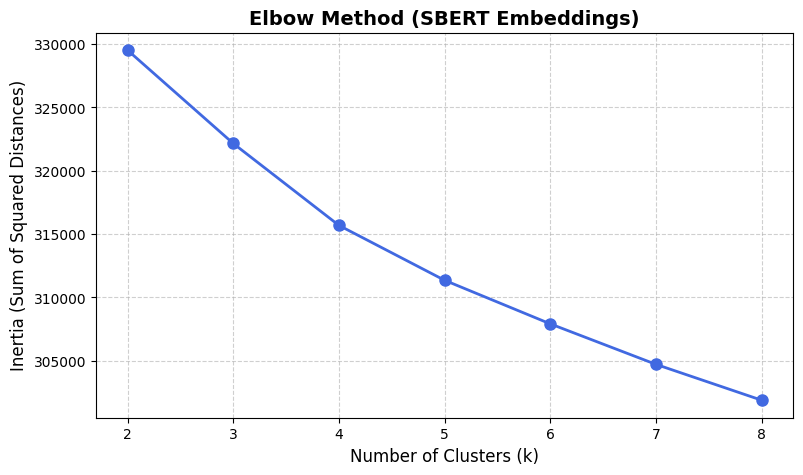

In [ ]:
# k값(2부터 8까지)에 따른 Inertia(군집 내 오차 합계) 계산
inertias = []
K_range = range(2, 9)

print("\n[k값별 Inertia 계산 결과]")
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(embeddings)
    inertias.append(kmeans.inertia_)
    print(f" • k = {k} 일 때 Inertia: {kmeans.inertia_:.2f}")

# 엘보우 곡선(Elbow Curve) 시각화
plt.figure(figsize=(9, 5))
plt.plot(K_range, inertias, marker='o', linestyle='-', color='royalblue', linewidth=2, markersize=8)
plt.title('Elbow Method (SBERT Embeddings)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia (Sum of Squared Distances)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(list(K_range))
plt.show()

#### 실루엣 계수


[k값별 평균 실루엣 점수 계산 결과]
 • k = 2 일 때 평균 실루엣 점수: 0.0424
 • k = 3 일 때 평균 실루엣 점수: 0.0359
 • k = 4 일 때 평균 실루엣 점수: 0.0328
 • k = 5 일 때 평균 실루엣 점수: 0.0337
 • k = 6 일 때 평균 실루엣 점수: 0.0284
 • k = 7 일 때 평균 실루엣 점수: 0.0266
 • k = 8 일 때 평균 실루엣 점수: 0.0310

🎯 실루엣 점수 기준으로 가장 적절한 최적의 k값: 2 (점수: 0.0424)


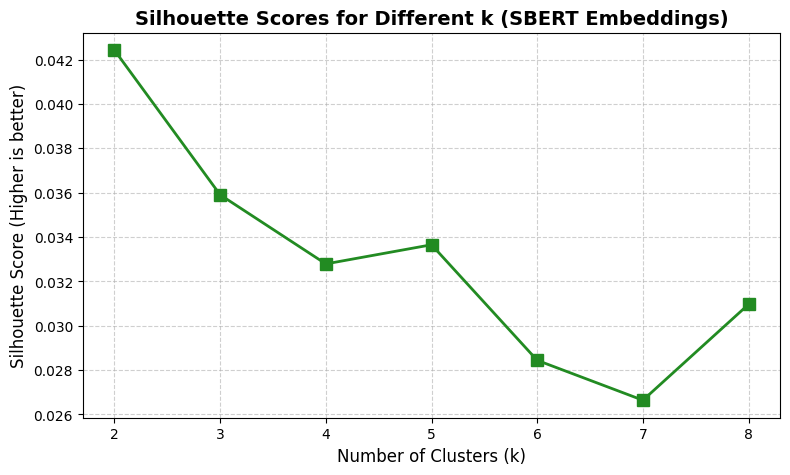

In [ ]:
# k값(2부터 8까지)에 따른 평균 실루엣 점수 계산
silhouette_scores = []
K_range = range(2, 9)

print("\n[k값별 평균 실루엣 점수 계산 결과]")
for k in K_range:
    # K-Means 모델 학습
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(embeddings)

    # 실루엣 점수 계산 (SBERT 임베딩 벡터와 클러스터 레이블 사용)
    score = silhouette_score(embeddings, cluster_labels)
    silhouette_scores.append(score)
    print(f" • k = {k} 일 때 평균 실루엣 점수: {score:.4f}")

# 가장 높은 실루엣 점수를 가진 최적의 k값 찾기
best_k = K_range[np.argmax(silhouette_scores)]
print(f"\n🎯 실루엣 점수 기준으로 가장 적절한 최적의 k값: {best_k} (점수: {max(silhouette_scores):.4f})")

# 실루엣 점수 변화 시각화
plt.figure(figsize=(9, 5))
plt.plot(K_range, silhouette_scores, marker='s', linestyle='-', color='forestgreen', linewidth=2, markersize=8)
plt.title('Silhouette Scores for Different k (SBERT Embeddings)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Silhouette Score (Higher is better)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(list(K_range))
plt.show()

In [ ]:
# K-Means 알고리즘을 사용해 정확히 5개의 군집으로 자동 분류
num_clusters = 5
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(embeddings)

# 데이터프레임에 클러스터 번호 컬럼 추가
df['cluster'] = cluster_labels

In [ ]:
# 각 군집별 대표 질문(중심점과 가장 가까운 질문) 3개씩 확인하기
print("\n[SBERT 군집별 대표 질문 미리보기]")
for i in range(num_clusters):
    cluster_indices = np.where(cluster_labels == i)[0]
    cluster_embeddings = embeddings[cluster_indices]
    center = kmeans.cluster_centers_[i]

    # 중심점과의 유클리드 거리가 가까운 순서로 정렬
    distances = euclidean_distances(cluster_embeddings, [center]).flatten()
    closest_indices = cluster_indices[np.argsort(distances)]

    print(f"\n--- 군집 {i+1} (총 {len(cluster_indices)}개 질문) ---")
    for idx in closest_indices[:3]:
        print(f"  • {texts[idx]}")


[SBERT 군집별 대표 질문 미리보기]

--- 군집 1 (총 616개 질문) ---
  • 봄웜톤일 것 같은 사람
  • 똘똘할 것 같은 사람
  • 장점이 제일 많을 것 같은 사람

--- 군집 2 (총 986개 질문) ---
  • 가장 잘보이고 싶은 사람이 누구야?
  • 이 중에서 나를 제일 잘 알 것 같은 사람은?
  • 장난치면 제일 잘받아줄 것 같은 사람은?

--- 군집 3 (총 850개 질문) ---
  • 가장 쩝쩝박사일 것 같은 친구는?
  • 친화력이 제일 좋을 것 같은 친구는?
  • 친구 제일 잘 사귈것 같은 사람은?

--- 군집 4 (총 729개 질문) ---
  • 빈 말 안 할 것 같은 사람은?
  • 너의 삶에 없어선 안될 것 같은 사람은?
  • 아무리 나쁘게 굴어도 웃어 줄 것 같은 사람은?

--- 군집 5 (총 720개 질문) ---
  • 사귀고 싶은 사람은?
  • 나랑 사귀고 싶어할 것 같은 사람은?
  • 특별한 날일 때 같이 있고 싶은 친구는 누구야?


In [ ]:
# 결과 파일 저장
output_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_cleaned_clustered.csv'
df.to_csv(output_path, index=False, encoding='utf-8-sig')
print(f"\n비지도 군집화 완료! 저장 경로: {output_path}")


비지도 군집화 완료! 저장 경로: /content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_cleaned_clustered.csv


In [ ]:
# 군집화가 완료된 CSV 파일 불러오기
file_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_cleaned_clustered.csv'
df = pd.read_csv(file_path)

# 'cluster' 컬럼을 기준으로 오름차순 정렬 (0 -> 1 -> 2 -> 3 -> 4)
df_sorted = df.sort_values(by='cluster').reset_index(drop=True)

# 정렬된 결과를 하나의 CSV 파일로 저장
output_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_sorted_by_cluster.csv'
df_sorted.to_csv(output_path, index=False, encoding='utf-8-sig')

print(f"클러스터 순서대로 정렬된 파일이 저장되었습니다: {output_path}")

# 각 클러스터별 데이터 개수 확인
print("\n[클러스터별 데이터 수]")
print(df_sorted['cluster'].value_counts().sort_index())

클러스터 순서대로 정렬된 파일이 저장되었습니다: /content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_sorted_by_cluster.csv

[클러스터별 데이터 수]
cluster
0    616
1    986
2    850
3    729
4    720
Name: count, dtype: int64


#### 1. TF-IDF 방식

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 정렬된 클러스터 파일 로드 (본인의 파일 경로에 맞게 수정)
file_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_sorted_by_cluster.csv'
df = pd.read_csv(file_path)

print(f"총 데이터 수: {len(df)}행\n")
print("="*60)
print(" [객관적 검증 1단계] SBERT 클러스터별 TF-IDF 핵심 키워드 추출")
print("="*60)

# 전체 클러스터의 텍스트를 문서 리스트로 구성
cluster_ids = sorted(df['cluster'].unique())
cluster_documents = []

for cid in cluster_ids:
    # 각 클러스터별 질문 텍스트들을 하나의 문자열로 이어붙임
    combined_text = " ".join(df[df['cluster'] == cid]['question_text'].dropna().tolist())
    cluster_documents.append(combined_text)

# TF-IDF Vectorizer 적용 (5개 클러스터 문서 간의 단어 가중치 비교)
tfidf = TfidfVectorizer(max_features=1000)
tfidf_matrix = tfidf.fit_transform(cluster_documents)
feature_names = tfidf.get_feature_names_out()

# 클러스터별 상위 핵심 키워드 출력
for idx, cid in enumerate(cluster_ids):
    scores = tfidf_matrix[idx].toarray().flatten()
    top_keyword_indices = scores.argsort()[::-1][5:10] # 상위 5개

    top_keywords = [(feature_names[i], round(scores[i], 4)) for i in top_keyword_indices]

    cluster_size = len(df[df['cluster'] == cid])
    print(f"\n🔹 클러스터 {cid} (질문 수: {cluster_size}개)")
    print(f"   • TF-IDF 상위 핵심 키워드 (단어, 가중치 점수):")
    for kw, score in top_keywords:
        print(f"     - {kw} ({score})")

총 데이터 수: 3901행

 [객관적 검증 1단계] SBERT 클러스터별 TF-IDF 핵심 키워드 추출

🔹 클러스터 0 (질문 수: 616개)
   • TF-IDF 상위 핵심 키워드 (단어, 가중치 점수):
     - 많이 (0.0361)
     - 사람은 (0.0299)
     - 같은사람 (0.0265)
     - 있는 (0.0251)
     - 어울리는 (0.0251)

🔹 클러스터 1 (질문 수: 986개)
   • TF-IDF 상위 핵심 키워드 (단어, 가중치 점수):
     - 어울리는 (0.0426)
     - 가까울 (0.0286)
     - 사람 (0.0264)
     - 좋은 (0.0239)
     - 많을 (0.0239)

🔹 클러스터 2 (질문 수: 850개)
   • TF-IDF 상위 핵심 키워드 (단어, 가중치 점수):
     - 제일 (0.0746)
     - 사람은 (0.0445)
     - 같이 (0.0432)
     - 많이 (0.0327)
     - 있는 (0.0314)

🔹 클러스터 3 (질문 수: 729개)
   • TF-IDF 상위 핵심 키워드 (단어, 가중치 점수):
     - 제일 (0.0411)
     - 친구는 (0.0398)
     - 싶은 (0.0311)
     - 먹을 (0.0261)
     - 많이 (0.0261)

🔹 클러스터 4 (질문 수: 720개)
   • TF-IDF 상위 핵심 키워드 (단어, 가중치 점수):
     - 가고 (0.1015)
     - 가장 (0.088)
     - 친구는 (0.0832)
     - 하고 (0.0724)
     - 있을 (0.044)


#### 2. 중심점 기반 대표 질문 추출

In [ ]:
from sklearn.metrics.pairwise import euclidean_distances

# 정렬된 클러스터 파일 로드 (본인의 파일 경로에 맞게 수정)
file_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_sorted_by_cluster.csv'
df = pd.read_csv(file_path)

# 2. SBERT 모델 로드 (임베딩 공간 상의 중심점 및 거리 계산용)
# print("SBERT 모델('jhgan/ko-sroberta-multitask') 로드 및 임베딩 재추출 중...")
# model = SentenceTransformer('jhgan/ko-sroberta-multitask')
# embeddings = model.encode(df['question_text'].tolist(), show_progress_bar=False)

# 데이터프레임에 임베딩 벡터 컬럼 추가
df['embedding'] = list(embeddings)

print("\n" + "="*60)
print(" [객관적 검증 2단계] 클러스터 중심점(Centroid) 기반 대표 질문 추출")
print("="*60)

# 각 클러스터별 중심점 계산 및 가장 가까운 질문 3개 추출
for cluster_id in sorted(df['cluster'].unique()):
    cluster_df = df[df['cluster'] == cluster_id].reset_index(drop=True)
    cluster_texts = cluster_df['question_text'].tolist()
    cluster_embeddings = np.array(cluster_df['embedding'].tolist())

    # 클러스터 중심점(Centroid) 계산 (평균 벡터)
    centroid = cluster_embeddings.mean(axis=0)

    # 중심점과 각 질문 벡터 간의 유클리드 거리 계산
    distances = euclidean_distances(cluster_embeddings, [centroid]).flatten()

    # 거리가 가까운 순서대로 정렬된 인덱스 추출
    closest_indices = np.argsort(distances)

    print(f"\n🔹 클러스터 {cluster_id} (총 질문 수: {len(cluster_df)}개)")
    print(f"   • 중심점과 가장 가까운 대표 질문 Top 3:")

    # 상위 3개 질문 출력
    for rank, idx in enumerate(closest_indices[:5], start=1):
        question = cluster_texts[idx]
        dist_score = distances[idx]
        print(f"     {rank}. {question} (거리: {dist_score:.4f})")


 [객관적 검증 2단계] 클러스터 중심점(Centroid) 기반 대표 질문 추출

🔹 클러스터 0 (총 질문 수: 616개)
   • 중심점과 가장 가까운 대표 질문 Top 3:
     1. 커서 운동선수일 것 같은사람 (거리: 5.9338)
     2. 가장 기계를 잘 다룰 것 같은 사람 (거리: 6.0099)
     3. 홍삼게임 제일 잘 할 것 같은 사람 (거리: 6.2072)
     4. 편지 쓰기 만렙일 것 같은 사람! (거리: 6.2453)
     5. UFO 타고 다닐 것 같은 사람 (거리: 6.2760)

🔹 클러스터 1 (총 질문 수: 986개)
   • 중심점과 가장 가까운 대표 질문 Top 3:
     1. 딱 보자마자 눈에 띄는 사람은?? (거리: 6.5095)
     2. 개미와 뽀뽀를 잘 할 것 같은 사람은? (거리: 6.5692)
     3. 사진빨을 잘받는 사람은? (거리: 6.6209)
     4. 동성에게 인기 제일 많을 것 같은 사람은? (거리: 6.6835)
     5. 영어 발음이 가장 좋을 것 같은 사람은? (거리: 6.7357)

🔹 클러스터 2 (총 질문 수: 850개)
   • 중심점과 가장 가까운 대표 질문 Top 3:
     1. 인어공주가 꿈일 것 같은 친구는? (거리: 6.4026)
     2. 방송인 느낌나는 친구는? (거리: 6.4406)
     3. 기계체조를 가장 잘 할 것 같은 친구는? (거리: 6.5368)
     4. 맥도날드에서 싸이버거 시킬 것 같은 친구 (거리: 6.5560)
     5. 길에서 만나면 반갑게 인사해줄것 같은 친구 (거리: 6.7098)

🔹 클러스터 3 (총 질문 수: 729개)
   • 중심점과 가장 가까운 대표 질문 Top 3:
     1. 항상 집에 가고 싶다고 할 것 같은 사람은? (거리: 7.3462)
     2. 산타할아버지가 선물 안줄것 같은사람은? (거리: 7.3821)
     3. 아플 때 가장 먼저 생각나는 사람은? (거리

#### 키워드 딕셔너리 기반

In [ ]:
# 정렬된 클러스터 파일 로드 (본인의 파일 경로에 맞게 수정)
file_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_sorted_by_cluster.csv'
df = pd.read_csv(file_path)

# 새롭게 정의한 5가지 카테고리 맞춤형 딕셔너리 사전
category_dicts = {
    '1. 외적 매력, 연애 호감': [
        '외모', '얼굴', '몸매', '스타일', '꾸밀', '이상형', '이성', '남친', '여친',
        '사귀', '고백', '연애', '썸', '설레', '반할', '매력', '호감', '눈빛', '데이트'
    ],
    '2. 취향, 생활습관, 상황': [
        '취향', '취미', '음악', '노래방', '영화', '밥', '먹을', '음식', '주말', '여행',
        '선물', '생일', '시간', '약속', '돈', '소비', '습관', '상황', '만약', '라면'
    ],
    '3. 우정, 신뢰, 관계 친밀도': [
        '친구', '우정', '의리', '비밀', '고민', '연락', '만남', '함께', '같이', '친해',
        '믿음', '신뢰', '서운', '손절', '단짝', '베프', '사라이', '관계'
    ],
    '4. 성격, 감정, 사회적 태도': [
        '성격', '착한', '멘탈', '자존감', '화', '다정', '긍정', '소심', '센스', '인성',
        '배려', '예의', '눈치', '감정', '화날', '스트레스', '태도', '성향', '인간관계'
    ],
    '5. 능력, 학업, 미래': [
        '능력', '일잘', '똘똘', '똑똑', '시험', '공부', '학교', '성적', '과제', '1등',
        '일등', '면접', '직장', '회사', '취업', '미래', '돈벌', '성공', '커리어', '지각'
    ]
}

print("="*60)
print(" [객관적 검증 3단계] 5대 카테고리 맞춤형 딕셔너리 확률 매핑")
print("="*60)

# 각 클러스터별 텍스트 스캔 및 키워드 매칭 비율 계산
for cluster_id in sorted(df['cluster'].unique()):
    cluster_df = df[df['cluster'] == cluster_id]
    full_text_blob = " ".join(cluster_df['question_text'].dropna().astype(str))

    dict_scores = {}
    total_cluster_matches = 0

    # 각 카테고리 사전별 키워드 빈도 측정
    for cat_name, keywords in category_dicts.items():
        score = sum(full_text_blob.count(kw) for kw in keywords)
        dict_scores[cat_name] = score
        total_cluster_matches += score

    print(f"\n🔹 클러스터 {cluster_id} (총 질문 수: {len(cluster_df)}개)")
    print(f"   • 카테고리별 키워드 매칭 비율:")

    if total_cluster_matches > 0:
        sorted_scores = sorted(dict_scores.items(), key=lambda x: x[1], reverse=True)
        for cat_name, score in sorted_scores:
            ratio = (score / total_cluster_matches) * 100
            print(f"     - {cat_name}: {score}개 매칭 ({ratio:.1f}%)")

        best_cat = sorted_scores[0][0]
        print(f"   🎯 [통계적 추천 카테고리]: {best_cat}")
    else:
        print("     - 매칭된 키워드 없음")

 [객관적 검증 3단계] 5대 카테고리 맞춤형 딕셔너리 확률 매핑

🔹 클러스터 0 (총 질문 수: 616개)
   • 카테고리별 키워드 매칭 비율:
     - 2. 취향, 생활습관, 상황: 53개 매칭 (32.9%)
     - 5. 능력, 학업, 미래: 47개 매칭 (29.2%)
     - 3. 우정, 신뢰, 관계 친밀도: 26개 매칭 (16.1%)
     - 4. 성격, 감정, 사회적 태도: 18개 매칭 (11.2%)
     - 1. 외적 매력, 연애 호감: 17개 매칭 (10.6%)
   🎯 [통계적 추천 카테고리]: 2. 취향, 생활습관, 상황

🔹 클러스터 1 (총 질문 수: 986개)
   • 카테고리별 키워드 매칭 비율:
     - 1. 외적 매력, 연애 호감: 52개 매칭 (28.3%)
     - 2. 취향, 생활습관, 상황: 47개 매칭 (25.5%)
     - 5. 능력, 학업, 미래: 39개 매칭 (21.2%)
     - 4. 성격, 감정, 사회적 태도: 30개 매칭 (16.3%)
     - 3. 우정, 신뢰, 관계 친밀도: 16개 매칭 (8.7%)
   🎯 [통계적 추천 카테고리]: 1. 외적 매력, 연애 호감

🔹 클러스터 2 (총 질문 수: 850개)
   • 카테고리별 키워드 매칭 비율:
     - 3. 우정, 신뢰, 관계 친밀도: 927개 매칭 (82.9%)
     - 2. 취향, 생활습관, 상황: 70개 매칭 (6.3%)
     - 1. 외적 매력, 연애 호감: 42개 매칭 (3.8%)
     - 5. 능력, 학업, 미래: 40개 매칭 (3.6%)
     - 4. 성격, 감정, 사회적 태도: 39개 매칭 (3.5%)
   🎯 [통계적 추천 카테고리]: 3. 우정, 신뢰, 관계 친밀도

🔹 클러스터 3 (총 질문 수: 729개)
   • 카테고리별 키워드 매칭 비율:
     - 2. 취향, 생활습관, 상황: 111개 매칭 (40.2%)
     - 3. 우정, 신뢰, 관계 친밀도: 63개 매칭 (22.8

####

## SBERT 코사인 유사도 매핑

In [ ]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
# 데이터 로드
file_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_cleaned.csv'
df = pd.read_csv(file_path)

# 'vote'와 '포인트'가 포함된 행을 제외
df = df[~df['question_text'].isin(['vote', '포인트'])].reset_index(drop=True)

texts = df['question_text'].dropna().tolist()
print(f"총 분석 데이터 수: {len(texts)}행")

총 분석 데이터 수: 3901행


In [ ]:
# SBERT 모델 로드
print("SBERT 모델('jhgan/ko-sroberta-multitask') 로드 중...")
model = SentenceTransformer('jhgan/ko-sroberta-multitask')

SBERT 모델('jhgan/ko-sroberta-multitask') 로드 중...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [ ]:
# 미리 정의한 5가지 카테고리 정의
categories = [
    "1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)",
    "2. 취향, 생활습관, 상황 (취향, 취미, 음식, 여행, 소비, 일상 습관 등)",
    "3. 우정, 신뢰, 관계 친밀도 (친구, 우정, 비밀, 고민, 신뢰, 의리 등)",
    "4. 성격, 감정, 사회적 태도 (성격, 멘탈, 화, 배려, 눈치, 인간관계 등)",
    "5. 능력, 학업, 미래 (능력, 공부, 성적, 면접, 직장, 커리어, 성공 등)"
]

In [ ]:
# 질문 임베딩과 카테고리 임베딩 추출
print("질문 및 카테고리 임베딩 추출 중...")
question_embeddings = model.encode(texts, show_progress_bar=True)
category_embeddings = model.encode(categories, show_progress_bar=False)

질문 및 카테고리 임베딩 추출 중...


Batches:   0%|          | 0/122 [00:00<?, ?it/s]

In [ ]:
# 코사인 유사도 계산 (질문 수 x 카테고리 수 Matrix 생성)
# shape: (총 질문 수, 5)
similarity_matrix = cosine_similarity(question_embeddings, category_embeddings)

In [ ]:
# 각 질문별로 가장 높은 유사도를 가진 카테고리 인덱스 및 점수 추출
best_category_indices = np.argmax(similarity_matrix, axis=1)
best_similarity_scores = np.max(similarity_matrix, axis=1)

# 데이터프레임에 결과 매핑
df['assigned_category'] = [categories[idx] for idx in best_category_indices]
df['similarity_score'] = best_similarity_scores

# 결과 요약 출력
print("\n" + "="*60)
print(" [SBERT 코사인 유사도 기반 직행 매핑 결과 요약]")
print("="*60)
print(df['assigned_category'].value_counts())

print("\n[매핑된 샘플 미리보기 (상위 5개)]")
print(df[['question_text', 'assigned_category', 'similarity_score']].head(5))


 [SBERT 코사인 유사도 기반 직행 매핑 결과 요약]
assigned_category
1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)       2282
3. 우정, 신뢰, 관계 친밀도 (친구, 우정, 비밀, 고민, 신뢰, 의리 등)      914
5. 능력, 학업, 미래 (능력, 공부, 성적, 면접, 직장, 커리어, 성공 등)     381
2. 취향, 생활습관, 상황 (취향, 취미, 음식, 여행, 소비, 일상 습관 등)     222
4. 성격, 감정, 사회적 태도 (성격, 멘탈, 화, 배려, 눈치, 인간관계 등)     102
Name: count, dtype: int64

[매핑된 샘플 미리보기 (상위 5개)]
                  question_text  \
0            가장 신비한 매력이 있는 사람은?   
1  "이 사람으로 한 번 살아보고 싶다" 하는 사람은?   
2                     미래의 틱톡커는?   
3               여기서 제일 특이한 친구는?   
4               가장 지켜주고 싶은 사람은?   

                               assigned_category  similarity_score  
0     1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)          0.550454  
1     1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)          0.467034  
2  5. 능력, 학업, 미래 (능력, 공부, 성적, 면접, 직장, 커리어, 성공 등)          0.303427  
3     1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)          0.466355  
4   3. 우정, 신뢰, 관계 친밀도 (친구, 우정, 비밀, 고민, 신뢰, 의리 등)          0.504206  


In [ ]:
df.to_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_mapped_by_sbert.csv', index=False, encoding='utf-8-sig')

### 카테고리 업데이트

In [ ]:
categories_updated = [
    "외적 매력과 연애 호감에 관한 질문",
    "취향, 생활습관, 그리고 일상 상황에 관한 질문",
    "우정과 신뢰, 그리고 관계 친밀도에 관한 질문",
    "성격과 감정, 그리고 사회적 태도에 관한 질문",
    "능력과 학업, 그리고 미래에 관한 질문"
]

In [ ]:
# 질문 임베딩과 카테고리 임베딩 추출
print("질문 및 카테고리 임베딩 추출 중...")
question_embeddings = model.encode(texts, show_progress_bar=True)
category_embeddings = model.encode(categories_updated, show_progress_bar=False)

질문 및 카테고리 임베딩 추출 중...


Batches:   0%|          | 0/122 [00:00<?, ?it/s]

In [ ]:
# 코사인 유사도 계산 (질문 수 x 카테고리 수 Matrix 생성)
# shape: (총 질문 수, 5)
similarity_matrix = cosine_similarity(question_embeddings, category_embeddings)

In [ ]:
# 각 질문별로 가장 높은 유사도를 가진 카테고리 인덱스 및 점수 추출
best_category_indices = np.argmax(similarity_matrix, axis=1)
best_similarity_scores = np.max(similarity_matrix, axis=1)

# 데이터프레임에 결과 매핑
df['assigned_category'] = [categories[idx] for idx in best_category_indices]
df['similarity_score'] = best_similarity_scores

# 결과 요약 출력
print("\n" + "="*60)
print(" [SBERT 코사인 유사도 기반 직행 매핑 결과 요약]")
print("="*60)
print(df['assigned_category'].value_counts())

print("\n[매핑된 샘플 미리보기 (상위 5개)]")
print(df[['question_text', 'assigned_category', 'similarity_score']].head(5))


 [SBERT 코사인 유사도 기반 직행 매핑 결과 요약]
assigned_category
1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)       2117
3. 우정, 신뢰, 관계 친밀도 (친구, 우정, 비밀, 고민, 신뢰, 의리 등)      898
5. 능력, 학업, 미래 (능력, 공부, 성적, 면접, 직장, 커리어, 성공 등)     591
2. 취향, 생활습관, 상황 (취향, 취미, 음식, 여행, 소비, 일상 습관 등)     183
4. 성격, 감정, 사회적 태도 (성격, 멘탈, 화, 배려, 눈치, 인간관계 등)     112
Name: count, dtype: int64

[매핑된 샘플 미리보기 (상위 5개)]
                  question_text  \
0            가장 신비한 매력이 있는 사람은?   
1  "이 사람으로 한 번 살아보고 싶다" 하는 사람은?   
2                     미래의 틱톡커는?   
3               여기서 제일 특이한 친구는?   
4               가장 지켜주고 싶은 사람은?   

                               assigned_category  similarity_score  
0     1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)          0.606964  
1     1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)          0.498346  
2  5. 능력, 학업, 미래 (능력, 공부, 성적, 면접, 직장, 커리어, 성공 등)          0.373804  
3     1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)          0.484969  
4   3. 우정, 신뢰, 관계 친밀도 (친구, 우정, 비밀, 고민, 신뢰, 의리 등)          0.465483  


In [ ]:
df.to_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_mapped_category_updated_sbert.csv', index=False, encoding='utf-8-sig')

### LLM vs SBERT 비교

In [ ]:
# 데이터 로드
path_final = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_final_category.csv' # 기존 방식 결과 파일
path_sbert = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_mapped_by_sbert.csv' # SBERT 직행 매핑 결과 파일

df_final = pd.read_csv(path_final)
df_sbert = pd.read_csv(path_sbert)

print(f"기존 파일 행 수: {len(df_final)}행")
print(f"SBERT 직행 매핑 파일 행 수: {len(df_sbert)}행")

기존 파일 행 수: 3901행
SBERT 직행 매핑 파일 행 수: 3901행


In [ ]:
df_final

,id,question_text,created_at,category
0,1070,내 결혼식 때 부케를 받았으면 하는 사람은?,2023-05-15 14:01:03,우정·신뢰·관계 친밀도
1,3319,손톱이 가장 긴 사람은?,2023-06-06 06:10:06,외적 매력·연애 호감
2,2113,이성을 가장 잘 꼬실 것 같은 사람은?,2023-06-02 08:06:37,외적 매력·연애 호감
3,3745,소소한 행복들을 모아 사람들에게 선물해줄것 같은 사람,2023-06-06 06:10:12,성격·감정·사회적 태도
4,1868,취미가 잠자기인 것 같은 사람,2023-06-02 08:06:29,취향·생활습관·상황
...,...,...,...,...
3896,1253,전교회장이 된다면 가장 뽑고 싶은 사람은?,2023-05-15 14:02:18,능력·학업·미래
3897,1421,고기를 가장 잘 구울 것 같은 사람은?,2023-05-15 14:03:27,능력·학업·미래
3898,980,짝사랑 가장 오래 해본 것 같은 사람은?,2023-05-15 14:00:27,외적 매력·연애 호감
3899,3756,화장 안할 것 같은 친구,2023-06-06 06:10:12,외적 매력·연애 호감


In [ ]:
df_sbert

,id,question_text,created_at,assigned_category,similarity_score
0,99,가장 신비한 매력이 있는 사람은?,2023-03-31 15:22:53,"1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)",0.550454
1,100,"""이 사람으로 한 번 살아보고 싶다"" 하는 사람은?",2023-03-31 15:22:53,"1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)",0.467034
2,101,미래의 틱톡커는?,2023-03-31 15:22:54,"5. 능력, 학업, 미래 (능력, 공부, 성적, 면접, 직장, 커리어, 성공 등)",0.303427
3,102,여기서 제일 특이한 친구는?,2023-03-31 15:22:54,"1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)",0.466355
4,103,가장 지켜주고 싶은 사람은?,2023-03-31 15:22:55,"3. 우정, 신뢰, 관계 친밀도 (친구, 우정, 비밀, 고민, 신뢰, 의리 등)",0.504206
...,...,...,...,...,...
3896,4112,MBTI 제일 반전이였던 친구는?,2023-06-06 06:10:17,"1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)",0.343351
3897,4280,너에게 칭찬을 받는다면 가장 기분 좋을 것 같아!,2023-06-06 06:15:40,"1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)",0.447578
3898,4313,사달라는거 다 사줄 것 같은 사람은?,2023-06-06 06:15:41,"1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)",0.323253
3899,4412,"할머니, 할아버지가 돼도 이 친구만큼은 연락하고 지낼 것 같아!",2023-06-06 06:15:42,"3. 우정, 신뢰, 관계 친밀도 (친구, 우정, 비밀, 고민, 신뢰, 의리 등)",0.423384


In [ ]:
# id를 기준으로 두 데이터프레임 병합
merged_df = pd.merge(df_final, df_sbert, on='id', suffixes=('_final', '_sbert'))
print(f"병합된 데이터 총 행 수: {len(merged_df)}행\n")

병합된 데이터 총 행 수: 3901행



In [ ]:
# df_sbert의 assigned_category에서 '숫자.'와 '(괄호 내용)'을 제거하는 함수
def clean_sbert_category(text):
    if pd.isna(text):
        return ""
    # 앞쪽 숫자와 점 제거 (예: "1. ")
    text = re.sub(r'^\d+\.\s*', '', text)
    # 뒤쪽 괄호 및 내부 설명 제거 (예: " (외모, 이상형...)")
    text = re.sub(r'\s*\(.*\)$', '', text)
    return text.strip()

merged_df['sbert_clean'] = merged_df['assigned_category'].apply(clean_sbert_category)

In [ ]:
# 두 카테고리 텍스트 형식을 통일하기 위한 정규화 함수
# (df_final의 '·' 기호와 df_sbert의 ', ' 기호 차이를 없애고 공백 제거)
def normalize_category(text):
    if pd.isna(text):
        return ""
    # 쉼표를 중간점으로 변경하여 형식 맞추기
    text = text.replace(', ', '·').replace(',', '·')
    # 모든 공백 제거
    return re.sub(r'\s+', '', str(text))


merged_df['final_norm'] = merged_df['category'].apply(normalize_category)
merged_df['sbert_norm'] = merged_df['sbert_clean'].apply(normalize_category)

In [ ]:
# 두 방식의 카테고리가 정확히 일치하는지 비교
merged_df['is_match'] = merged_df['final_norm'] == merged_df['sbert_norm']

# 결과 요약 출력
match_count = merged_df['is_match'].sum()
total_count = len(merged_df)
print("="*60)
print(f"🎯 두 카테고리 분류가 일치하는 질문 수: {match_count} / {total_count}개 ({match_count/total_count*100:.1f}%)")
print("="*60)

# 불일치하거나 일치하는 샘플 확인
print("\n[비교 결과 샘플 미리보기 (상위 10개)]")
print(merged_df[['id', 'question_text_final', 'category', 'sbert_clean', 'is_match']].head(10))

🎯 두 카테고리 분류가 일치하는 질문 수: 1617 / 3901개 (41.5%)

[비교 결과 샘플 미리보기 (상위 10개)]
     id            question_text_final      category     sbert_clean  is_match
0  1070       내 결혼식 때 부케를 받았으면 하는 사람은?  우정·신뢰·관계 친밀도    외적 매력, 연애 호감     False
1  3319                  손톱이 가장 긴 사람은?   외적 매력·연애 호감    외적 매력, 연애 호감      True
2  2113          이성을 가장 잘 꼬실 것 같은 사람은?   외적 매력·연애 호감    외적 매력, 연애 호감      True
3  3745  소소한 행복들을 모아 사람들에게 선물해줄것 같은 사람  성격·감정·사회적 태도    외적 매력, 연애 호감     False
4  1868               취미가 잠자기인 것 같은 사람    취향·생활습관·상황    취향, 생활습관, 상황      True
5  1486           주말에 가장 많이 보고 싶은 친구는?  우정·신뢰·관계 친밀도  우정, 신뢰, 관계 친밀도      True
6  1449              자주 못 만나서 아쉬운 친구는?  우정·신뢰·관계 친밀도  우정, 신뢰, 관계 친밀도      True
7  1316      생일선물로 외계인 가면 사줄 것 같은 사람은?    취향·생활습관·상황    외적 매력, 연애 호감     False
8   421                    세상 제일 착한 친구  성격·감정·사회적 태도  우정, 신뢰, 관계 친밀도     False
9  1105    전세계 사람들과 친해질 수 있을 것 같은 사람은?  성격·감정·사회적 태도  우정, 신뢰, 관계 친밀도     False


In [ ]:
merged_df.to_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/category_comparison_result.csv', index=False, encoding='utf-8-sig')

#### 일치하지 않는 데이터 표본 조사

In [ ]:
import pandas as pd

# 파일 로드
file_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/category_comparison_result.csv'
df = pd.read_csv(file_path)

print(f"전체 데이터 행 수: {len(df)}행")

# is_match 컬럼이 False인(두 방식의 분류가 불일치하는) 데이터만 필터링
df_false = df[df['is_match'] == False].copy()
print(f"불일치(False) 데이터 총 행 수: {len(df_false)}행")

# 불일치 데이터 중 380개 랜덤 추출 (만약 전체 불일치 데이터가 380개보다 적을 경우를 대비해 예외 처리 포함)
sample_n = min(380, len(df_false))
df_sampled = df_false.sample(n=sample_n, random_state=42) # random_state를 지정하여 실행할 때마다 결과가 고정되도록 설정

# 요청하신 3개의 컬럼만 선택
result_df = df_sampled[['id', 'question_text_final', 'sbert_clean']]

print("\n" + "="*60)
print(f"🎯 최종 추출된 샘플 수: {len(result_df)}개")
print("="*60)

# 샘플 결과 미리보기 (상위 10개)
print(result_df.head(10))

전체 데이터 행 수: 3901행
불일치(False) 데이터 총 행 수: 2284행

🎯 최종 추출된 샘플 수: 380개
        id          question_text_final     sbert_clean
673   3898             영화 덕후일 것 같은 사람은?    외적 매력, 연애 호감
3725   489  지구가 1주일 뒤에 멸망한다면 누구랑 있고 싶어?    취향, 생활습관, 상황
3833  2539        방학에 집에서만 있을 것 같은 친구는?  우정, 신뢰, 관계 친밀도
3367  3828          웹툰에 나온 캐릭터를 닮은 사람은?    외적 매력, 연애 호감
1376  3397          자신의 롤모델과 가장 닮은 사람은?    외적 매력, 연애 호감
652   2430               선곡센스가 남다른 친구는?    외적 매력, 연애 호감
518   3930  엄마랑 싸운 후 문을 살살 닫을 것 같은 사람은?  우정, 신뢰, 관계 친밀도
781    347       노래 부를 때 감성이 가장 좋은 사람은?    외적 매력, 연애 호감
2679  3079                 가장 유니크한 사람은?    외적 매력, 연애 호감
1046  3852           아직 유니콘을 믿을 것 같은 친구    외적 매력, 연애 호감


In [ ]:
result_df.to_csv('/content/drive/MyDrive/[고급PJ] Preprocessed_Data/category_mismatch_sample_380.csv', index=False, encoding='utf-8-sig')

In [ ]:
# 파일 로드
file_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/questions_mapped_by_sbert.csv'
df_sbert = pd.read_csv(file_path)

print(f"전체 데이터 행 수: {len(df_sbert)}행\n")

# 코사인 유사도 점수가 0.3 이하인 행 필터링
low_score_df = df_sbert[df_sbert['similarity_score'] <= 0.3]

print("="*60)
print(f"🎯 코사인 유사도 0.3 이하인 행의 총 개수: {len(low_score_df)}개")
print(f"   (전체 대비 비율: {len(low_score_df) / len(df_sbert) * 100:.1f}%)")
print("="*60)

# 0.3 이하인 데이터 샘플 확인 (상위 10개)
if len(low_score_df) > 0:
    print("\n[유사도 0.3 이하 질문 샘플 미리보기]")
    print(low_score_df[['question_text', 'assigned_category', 'similarity_score']].head(10))
else:
    print("\n코사인 유사도가 0.3 이하인 데이터가 존재하지 않습니다. (임계값을 조금 높여서 확인해보세요!)")

전체 데이터 행 수: 3901행

🎯 코사인 유사도 0.3 이하인 행의 총 개수: 1036개
   (전체 대비 비율: 26.6%)

[유사도 0.3 이하 질문 샘플 미리보기]
                    question_text  \
14       싸울 때 반드시 내 편에 두고 싶은 사람은?   
18          샤워 1시간 동안 할 것 같은 사람은?   
21          본인 방이 제일 깨끗할거 같은 사람은?   
30      길에서 자주 번호를 따여봤을 것 같은 사람은?   
39               잘 때 전화하고 싶은 사람은?   
53         숨겨진 댄싱 머신이라고 생각하는 사람은?   
54         어디 내놔도 노래로 꿀리지 않는 친구는?   
58         나에게 항상 응원과 용기를 주는 사람은?   
64  10년 뒤에 가장 돈을 많이 벌었을 것 같은 사람은?   
73   얘와 함께라면 어떤 상황이든 죽지는 않을 것 같다!   

                                assigned_category  similarity_score  
14     1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)          0.286799  
18     1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)          0.263702  
21  2. 취향, 생활습관, 상황 (취향, 취미, 음식, 여행, 소비, 일상 습관 등)          0.220793  
30     1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)          0.288252  
39   3. 우정, 신뢰, 관계 친밀도 (친구, 우정, 비밀, 고민, 신뢰, 의리 등)          0.292370  
53     1. 외적 매력, 연애 호감 (외모, 이상형, 연애, 썸, 고백, 매력 등)          0.298743  
54  

## 유저별 초성 개봉 예측 모델링

- 유저별 초성 개봉 여부 ⇒ 개봉X(0)/ 개봉O(1) => 이진분류

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, average_precision_score, roc_auc_score
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE

In [4]:
# 2. 파일 경로 설정
base_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/'

user_path = base_path + 'accounts_user_cleaned.csv'
record_path = base_path + 'accounts_userquestionrecord_updated.csv'
question_path = base_path + 'questions_combined_final.csv'
piece_path = base_path + 'polls_question_piece_cleaned.csv'

# 3. 데이터프레임 로드
df_user = pd.read_csv(user_path)
df_record = pd.read_csv(record_path)
df_questions = pd.read_csv(question_path)
df_piece = pd.read_csv(piece_path)

# 4. 날짜 컬럼을 Datetime 형식으로 변환 (mixed 포맷 적용으로 파싱 에러 방지)
df_user['created_at'] = pd.to_datetime(df_user['created_at'], errors='coerce')
df_record['created_at'] = pd.to_datetime(df_record['created_at'], errors='coerce')
df_questions['created_at'] = pd.to_datetime(df_questions['created_at'], errors='coerce', format='mixed')
df_piece['created_at'] = pd.to_datetime(df_piece['created_at'], errors='coerce', format='mixed')


# ----------------------------------------------------
# 5. 유저별 기본 프로필 파생변수 생성
# ----------------------------------------------------
sent_votes = df_record.groupby('user_id').size().reset_index(name='sent_vote_count')
received_votes = df_record.groupby('chosen_user_id').size().reset_index(name='chosen_user_id_count')

df_user_features = df_user.copy()
df_user_features = pd.merge(df_user_features, sent_votes, left_on='id', right_on='user_id', how='left')
df_user_features = pd.merge(df_user_features, received_votes, left_on='id', right_on='chosen_user_id', how='left')

df_user_features['sent_vote_count'] = df_user_features['sent_vote_count'].fillna(0)
df_user_features['chosen_user_id_count'] = df_user_features['chosen_user_id_count'].fillna(0)

# 보낸 투표가 0보다 크거나 OR 받은 투표가 0보다 크면 1, 아니면 0
df_user_features['has_voted_before'] = (
    (df_user_features['sent_vote_count'] > 0) |
    (df_user_features['chosen_user_id_count'] > 0)
).astype(int)

df_user_features = df_user_features.drop(columns=['user_id', 'chosen_user_id'], errors='ignore')


# ----------------------------------------------------
# 6. 타겟(Target) 변수 생성 및 기본 데이터마트 조인
# ----------------------------------------------------
df_record['is_opened'] = (df_record['opened_times'] > 0).astype(int)

# 핵심 로그 + 유저 피쳐 병합
df_mart = pd.merge(
    df_record,
    df_user_features,
    left_on='user_id',
    right_on='id',
    how='inner',
    suffixes=('', '_user')
)

# 질문 정보(df_questions) 병합 (카테고리 정보 포함)
df_mart = pd.merge(
    df_mart,
    df_questions,
    left_on='question_id',
    right_on='id',
    how='inner',
    suffixes=('', '_question')
)



# ----------------------------------------------------
# 7. 추가 파생변수 생성 (초고속 벡터화 방식 적용)
# ----------------------------------------------------

# 데이터 전체를 유저별, 시간순으로 깔끔하게 정렬
df_mart = df_mart.sort_values(by=['user_id', 'created_at']).reset_index(drop=True)

# ① [유저 성향] 해당 날짜(투표 일자) 이전 같은 카테고리 투표 횟수 카운팅
# cumcount()를 이용해 유저별-카테고리별 누적 순번(0부터 시작)을 매기면 '이전까지의 횟수'가 완벽히 계산됩니다.
df_mart['past_same_category_vote_count'] = (
    df_mart.groupby(['user_id', 'category'])
    .cumcount()
)


# ② [유저 활동성] 해당 날짜 기준 최근 7일 이내 투표 횟수 계산
# pandas의 rolling 윈도우 기능을 활용하여 C언어 속도로 순식간에 계산합니다.
df_temp = df_mart[['user_id', 'created_at']].copy()
df_temp['event'] = 1
df_temp = df_temp.set_index('created_at')

df_mart['recent_7days_vote_count'] = (
    df_temp.groupby('user_id')
    .rolling('7D', closed='left')  # 현재 행의 시간 미만(과거 7일) 구간만 정확히 타겟팅
    ['event']
    .count()
    .reset_index(level=0, drop=True)
    .fillna(0)
    .astype(int)
    .values
)


# ----------------------------------------------------
# 8. 최종 결과 확인
# -------------------관---------------------------------
print("--- 최종 통합 데이터마트 형태 (Row x Column) ---")
print(df_mart.shape)

target_columns = [
    'user_id', 'question_id', 'category', 'is_opened',
    'recent_7days_vote_count', 'past_same_category_vote_count',
    'sent_vote_count', 'chosen_user_id_count', 'has_voted_before',
    'gender', 'point'
]
available_cols = [col for col in target_columns if col in df_mart.columns]
display(df_mart[available_cols].head(5))

--- 최종 통합 데이터마트 형태 (Row x Column) ---
(1204228, 31)


,user_id,question_id,category,is_opened,recent_7days_vote_count,past_same_category_vote_count,sent_vote_count,chosen_user_id_count,has_voted_before,gender
0,838023,121,성격·감정·사회적 태도,0,0,0,22.0,260.0,1,F
1,838023,224,취향·생활습관·상황,0,1,0,22.0,260.0,1,F
2,838023,121,성격·감정·사회적 태도,0,2,1,22.0,260.0,1,F
3,838023,310,성격·감정·사회적 태도,0,3,2,22.0,260.0,1,F
4,838023,203,성격·감정·사회적 태도,0,4,3,22.0,260.0,1,F


In [5]:
# 1. 이전 투표 여부 컬럼('has_voted_before')의 1과 0 개수 확인
print("--- has_voted_before 분포 ---")
print(df_mart['has_voted_before'].value_counts())

# 2. (참고) 타겟 변수인 초성 개봉 여부('is_opened')의 1과 0 개수 확인
print("\n--- is_opened 분포 ---")
print(df_mart['is_opened'].value_counts())

--- has_voted_before 분포 ---
has_voted_before
1    1204228
Name: count, dtype: int64

--- is_opened 분포 ---
is_opened
0    1147481
1      56747
Name: count, dtype: int64


In [ ]:
# ==========================================
# 1. 데이터 준비 및 인코딩 단계
# ==========================================
# (이미 만들어진 df_mart가 있다고 가정)
feature_cols = [
    'category', 'gender',
    'recent_7days_vote_count', 'past_same_category_vote_count',
    'sent_vote_count', 'chosen_user_id_count', 'has_voted_before'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')


# ==========================================
# 2. Train / Test 데이터셋 분할
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# ==========================================
# 3. LightGBM 모델 학습 (정상 학습 버전)
# ==========================================
model_baseline = lgb.LGBMClassifier(
    random_state=42,
    n_estimators=100,
    learning_rate=0.05
)

model_baseline.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=10)]
)


# ==========================================
# 4. 예측 확률 추출 및 임계값 조정
# ==========================================
y_pred_proba = model_baseline.predict_proba(X_test)[:, 1]

# 실제 개봉 비율(약 4~5%)을 고려한 상위 5% 커트라인 설정
threshold = np.percentile(y_pred_proba, 95)
y_pred_adjusted = (y_pred_proba >= threshold).astype(int)


# ==========================================
# 5. 성능 평가 결과 출력
# ==========================================
pr_auc = average_precision_score(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"\n[베이스라인 모델 평가 결과]")
print(f"PR-AUC Score: {pr_auc:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}\n")
print(classification_report(y_test, y_pred_adjusted))

Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's binary_logloss: 0.184919

[베이스라인 모델 평가 결과]
PR-AUC Score: 0.0775
ROC-AUC Score: 0.6341

              precision    recall  f1-score   support

           0       0.96      0.95      0.95    229497
           1       0.10      0.11      0.11     11349

    accuracy                           0.91    240846
   macro avg       0.53      0.53      0.53    240846
weighted avg       0.92      0.91      0.91    240846



#### 클래스 가중치 조절

In [6]:
# ==========================================
# 1. 데이터 준비 및 인코딩 단계
# ==========================================
feature_cols = [
    'category', 'gender',
    'recent_7days_vote_count', 'past_same_category_vote_count',
    'sent_vote_count', 'chosen_user_id_count', 'has_voted_before'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')


# ==========================================
# 2. Train / Test 데이터셋 분할
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# ==========================================
# 2-1. 클래스 가중치(scale_pos_weight) 자동 계산
# ==========================================
# (음성 클래스 개수 / 양성 클래스 개수)를 계산하여 모델에 부여
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = neg_count / pos_count

print(f"[안내] 훈련 데이터 클래스 비율에 따른 scale_pos_weight 값: {scale_pos_weight_val:.2f}\n")


# ==========================================
# 3. LightGBM 모델 학습 (클래스 가중치 적용 버전)
# ==========================================
model_baseline = lgb.LGBMClassifier(
    random_state=42,
    n_estimators=100,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight_val  # 👈 클래스 가중치 추가 완료!
)

model_baseline.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=10)]
)


# ==========================================
# 4. 예측 확률 추출 및 임계값 조정
# ==========================================
y_pred_proba = model_baseline.predict_proba(X_test)[:, 1]

# 실제 개봉 비율(약 4~5%)을 고려한 상위 5% 커트라인 설정
threshold = np.percentile(y_pred_proba, 95)
y_pred_adjusted = (y_pred_proba >= threshold).astype(int)


# ==========================================
# 5. 성능 평가 결과 출력
# ==========================================
pr_auc = average_precision_score(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"\n[클래스 가중치가 적용된 모델 평가 결과]")
print(f"PR-AUC Score: {pr_auc:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}\n")
print(classification_report(y_test, y_pred_adjusted))

[안내] 훈련 데이터 클래스 비율에 따른 scale_pos_weight 값: 20.22

[LightGBM] [Info] Number of positive: 45398, number of negative: 917984
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.036268 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1027
[LightGBM] [Info] Number of data points in the train set: 963382, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.047124 -> initscore=-3.006712
[LightGBM] [Info] Start training from score -3.006712
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[1]	valid_0's binary_logloss: 0.194196

[클래스 가중치가 적용된 모델 평가 결과]
PR-AUC Score: 0.0675
ROC-AUC Score: 0.6196

              precision    recall  f1-score   support

           0       0.95      0.94      0.95    229497
           1       0.08      0.10      0.09     11349

    accuracy           

#### SMOTE

In [8]:
# ==========================================
# 1. 데이터 준비 및 인코딩 단계
# ==========================================
feature_cols = [
    'category', 'gender',
    'recent_7days_vote_count', 'past_same_category_vote_count',
    'sent_vote_count', 'chosen_user_id_count', 'has_voted_before'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')


# ==========================================
# 2. Train / Test 데이터셋 분할
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# ==========================================
# 2-1. SMOTE 리샘플링 적용 (Train Set에만 수행!)
# ==========================================
# 주의: LightGBM은 카테고리형 타입을 자체 지원하므로, SMOTE 적용 시 잠시 category 타입을 숫자형태(int)로 변환했다가 복구해야 에러가 안 납니다.
X_train_numeric = X_train.copy()
X_train_numeric['category'] = X_train_numeric['category'].cat.codes

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_numeric, y_train)

# SMOTE가 끝난 후 다시 category 컬럼을 category 타입으로 변환
X_train_resampled['category'] = X_train_resampled['category'].astype('category')

print(f"[안내] SMOTE 적용 전 훈련 데이터 크기: {X_train.shape}")
print(f"[안내] SMOTE 적용 후 훈련 데이터 크기: {X_train_resampled.shape} (소수 클래스 증강 완료)\n")


# ==========================================
# 3. LightGBM 모델 학습 (리샘플링된 데이터 활용)
# ==========================================
model_baseline = lgb.LGBMClassifier(
    random_state=42,
    n_estimators=100,
    learning_rate=0.05
)

model_baseline.fit(
    X_train_resampled, y_train_resampled,  # 👈 증강된 훈련 데이터로 학습
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=10)]
)


# ==========================================
# 4. 예측 확률 추출 및 임계값 조정
# ==========================================
y_pred_proba = model_baseline.predict_proba(X_test)[:, 1]

# 실제 개봉 비율(약 4~5%)을 고려한 상위 5% 커트라인 설정
threshold = np.percentile(y_pred_proba, 50)
y_pred_adjusted = (y_pred_proba >= threshold).astype(int)


# ==========================================
# 5. 성능 평가 결과 출력
# ==========================================
pr_auc = average_precision_score(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"\n[SMOTE 적용 모델 평가 결과]")
print(f"PR-AUC Score: {pr_auc:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}\n")
print(classification_report(y_test, y_pred_adjusted))

[안내] SMOTE 적용 전 훈련 데이터 크기: (963382, 7)
[안내] SMOTE 적용 후 훈련 데이터 크기: (1835968, 7) (소수 클래스 증강 완료)

[LightGBM] [Info] Number of positive: 917984, number of negative: 917984
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.065727 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1027
[LightGBM] [Info] Number of data points in the train set: 1835968, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's binary_logloss: 0.351434

[SMOTE 적용 모델 평가 결과]
PR-AUC Score: 0.0494
ROC-AUC Score: 0.5116

              precision    recall  f1-score   support

           0       0.95      0.50      0.66    229497
           1       0.05      0.49      0.09     11349

    accuracy        

--- 오차 행렬 (Confusion Matrix) ---
[[218695  10802]
 [ 10108   1241]]

[해석 가이드]
 [[진짜 0을 0으로 맞춘 수(TN),  틀려서 1로 오탐지한 수(FP)]
  [놓쳐서 0으로 오판한 수(FN),    진짜 1을 1로 맞춘 수(TP)]]



/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48393 (\N{HANGUL SYLLABLE BONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


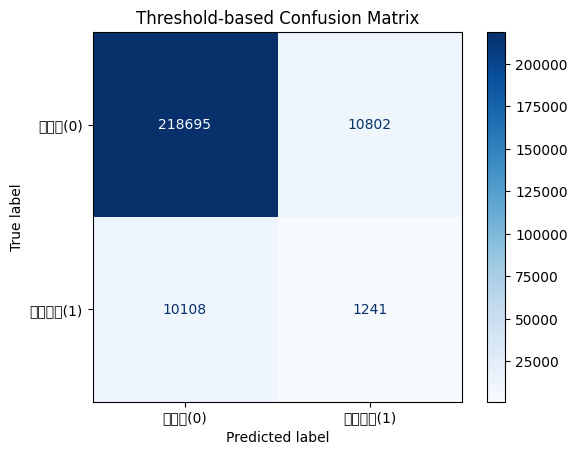


--- 모델이 '개봉(1)'한다고 예측한 샘플들 (상위 10개) ---


,actual_is_opened,predicted_proba,predicted_class,category,has_voted_before
630088,0,0.238554,1,우정·신뢰·관계 친밀도,1
522798,0,0.230973,1,외적 매력·연애 호감,1
522800,1,0.230973,1,외적 매력·연애 호감,1
522799,0,0.230973,1,외적 매력·연애 호감,1
522762,0,0.227548,1,외적 매력·연애 호감,1
522813,0,0.226552,1,우정·신뢰·관계 친밀도,1
522758,0,0.224051,1,외적 매력·연애 호감,1
522759,1,0.223512,1,외적 매력·연애 호감,1
522766,0,0.221361,1,외적 매력·연애 호감,1
630095,0,0.218735,1,우정·신뢰·관계 친밀도,1


In [ ]:
# 1. 임계값 기준으로 0과 1 변환 (상위 5% 커트라인)
threshold = np.percentile(y_pred_proba, 95)
y_pred_adjusted = (y_pred_proba >= threshold).astype(int)

# 2. 오차 행렬(Confusion Matrix) 계산
cm = confusion_matrix(y_test, y_pred_adjusted)
print("--- 오차 행렬 (Confusion Matrix) ---")
print(cm)
print("\n[해석 가이드]")
print(" [[진짜 0을 0으로 맞춘 수(TN),  틀려서 1로 오탐지한 수(FP)]")
print("  [놓쳐서 0으로 오판한 수(FN),    진짜 1을 1로 맞춘 수(TP)]]\n")

# 3. 시각화로 오차 행렬 확인하기
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['미개봉(0)', '초성개봉(1)'])
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Threshold-based Confusion Matrix")
plt.show()

# 4. 실제 정답과 예측값이 나란히 담긴 비교 데이터프레임 만들기
df_comparison = X_test.copy()
df_comparison['actual_is_opened'] = y_test.values          # 실제 정답
df_comparison['predicted_proba'] = y_pred_proba          # 모델이 예측한 확률
df_comparison['predicted_class'] = y_pred_adjusted       # 임계값 적용 후 판정 결과 (0 또는 1)

# 모델이 '초성을 열 것(1)'이라고 예측한 데이터들만 모아서 상위 10개 살펴보기
print("\n--- 모델이 '개봉(1)'한다고 예측한 샘플들 (상위 10개) ---")
display(
    df_comparison[df_comparison['predicted_class'] == 1]
    .sort_values(by='predicted_proba', ascending=False)
    .head(10)[['actual_is_opened', 'predicted_proba', 'predicted_class', 'category', 'has_voted_before']]
)

#### 파생변수 추가 생성

In [10]:
!pip install optuna -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 11.0 MB/s eta 0:00:00


In [11]:
!pip install helper-plot-hangul

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 9.7 MB/s eta 0:00:00


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import lightgbm as lgb
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor
import optuna
import helper_plot_hangul
from imblearn.over_sampling import SMOTE
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report, precision_score, recall_score, f1_score

In [13]:
# 파일 경로 설정
base_path = '/content/drive/MyDrive/[고급PJ] Preprocessed_Data/'

user_path = base_path + 'accounts_user_cleaned.csv'
record_path = base_path + 'accounts_userquestionrecord_updated.csv'
question_path = base_path + 'questions_combined_final.csv'
piece_path = base_path + 'polls_question_piece_cleaned.csv'

# 데이터프레임 로드
df_user = pd.read_csv(user_path)
df_record = pd.read_csv(record_path)
df_questions = pd.read_csv(question_path)
df_piece = pd.read_csv(piece_path)

# 날짜 컬럼을 Datetime 형식으로 변환
df_user['created_at'] = pd.to_datetime(df_user['created_at'], errors='coerce')
df_record['created_at'] = pd.to_datetime(df_record['created_at'], errors='coerce')
df_questions['created_at'] = pd.to_datetime(df_questions['created_at'], errors='coerce', format='mixed')
df_piece['created_at'] = pd.to_datetime(df_piece['created_at'], errors='coerce', format='mixed')


# 유저별 기본 프로필 파생변수 생성
sent_votes = df_record.groupby('user_id').size().reset_index(name='sent_vote_count')
received_votes = df_record.groupby('chosen_user_id').size().reset_index(name='chosen_user_id_count')

df_user_features = df_user.copy()
df_user_features = pd.merge(df_user_features, sent_votes, left_on='id', right_on='user_id', how='left')
df_user_features = pd.merge(df_user_features, received_votes, left_on='id', right_on='chosen_user_id', how='left')

df_user_features['sent_vote_count'] = df_user_features['sent_vote_count'].fillna(0)
df_user_features['chosen_user_id_count'] = df_user_features['chosen_user_id_count'].fillna(0)

df_user_features['has_voted_before'] = (
    (df_user_features['sent_vote_count'] > 0) |
    (df_user_features['chosen_user_id_count'] > 0)
).astype(int)

df_user_features = df_user_features.drop(columns=['user_id', 'chosen_user_id'], errors='ignore')


# 타겟(Target) 변수 생성 및 기본 데이터마트 조인
df_record['is_opened'] = (df_record['opened_times'] > 0).astype(int)

df_mart = pd.merge(
    df_record,
    df_user_features,
    left_on='user_id',
    right_on='id',
    how='inner',
    suffixes=('', '_user')
)

df_mart = pd.merge(
    df_mart,
    df_questions,
    left_on='question_id',
    right_on='id',
    how='inner',
    suffixes=('', '_question')
)


# 전체 데이터 시계열 정렬
df_mart = df_mart.sort_values(by=['created_at']).reset_index(drop=True)


# 파생변수 생성


# 해당 날짜 이전 같은 카테고리 노출 횟수 카운팅
df_mart['past_same_category_vote_count'] = (
    df_mart.groupby(['user_id', 'category']).cumcount()
)

# 카테고리별 과거 개봉 수 (cumsum - 현재값 = 이전까지의 누적 합산)
df_mart['category_past_opened_count'] = (
    df_mart.groupby(['user_id', 'category'])['is_opened'].cumsum() - df_mart['is_opened']
).fillna(0)

# 카테고리별 과거 받은 투표 횟수
df_mart['is_received_vote'] = (~df_mart['chosen_user_id'].isna()).astype(int)
df_mart['category_past_received_vote_count'] = (
    df_mart.groupby(['user_id', 'category'])['is_received_vote'].cumsum() - df_mart['is_received_vote']
).fillna(0)

# 카테고리별 과거 개봉률 (분모 0 방지 +1 스무딩)
df_mart['category_open_rate'] = (
    df_mart['category_past_opened_count'] / (df_mart['category_past_received_vote_count'] + 1)
)

# 유저 내 카테고리 선호 순위 (개봉률 기준 높은 순서대로 1위, 2위..)
df_mart['user_category_rank'] = (
    df_mart.groupby('user_id')['category_open_rate']
    .rank(ascending=False, method='min')
)

# Give / Take 비율 (시간순 누적 수신 및 발신 횟수)
df_mart['cumulative_received_vote'] = (
    df_mart.groupby('chosen_user_id')['is_received_vote'].cumsum() - df_mart['is_received_vote']
).fillna(0)

df_mart['is_sent_vote'] = 1
df_mart['cumulative_sent_vote'] = (
    df_mart.groupby('user_id')['is_sent_vote'].cumsum() - df_mart['is_sent_vote']
).fillna(0)

df_mart['give_take_ratio'] = (
    df_mart['cumulative_received_vote'] / (df_mart['cumulative_sent_vote'] + df_mart['cumulative_received_vote'] + 1)
)

# 최근 7일 이내 활동 횟수 계산
df_temp = df_mart[['user_id', 'created_at']].copy()
df_temp['event'] = 1
df_temp = df_temp.set_index('created_at')

df_mart['recent_7days_vote_count'] = (
    df_temp.groupby('user_id')
    .rolling('7D', closed='left')
    ['event']
    .count()
    .reset_index(level=0, drop=True)
    .fillna(0)
    .astype(int)
    .values
)

# 결측치 및 무한대(inf) 안전 처리
df_mart.replace([np.inf, -np.inf], np.nan, inplace=True)
df_mart.fillna(0, inplace=True)


# 최종 결과
print("--- 최종 통합 데이터마트 형태 (Row x Column) ---")
print(df_mart.shape)

target_columns = [
    'user_id', 'question_id', 'category', 'is_opened',
    'recent_7days_vote_count', 'past_same_category_vote_count',
    'category_open_rate','user_category_rank',
    'give_take_ratio', 'sent_vote_count', 'chosen_user_id_count', 'has_voted_before',
    'gender'
]
available_cols = [col for col in target_columns if col in df_mart.columns]
display(df_mart[available_cols].head(5))

--- 최종 통합 데이터마트 형태 (Row x Column) ---
(1204228, 40)


,user_id,question_id,category,is_opened,recent_7days_vote_count,past_same_category_vote_count,category_open_rate,user_category_rank,give_take_ratio,sent_vote_count,chosen_user_id_count,has_voted_before,gender
0,849436,252,외적 매력·연애 호감,0,0,0,0.0,279.0,0.0,637.0,376.0,1,F
1,849436,244,능력·학업·미래,0,1,0,0.0,279.0,0.0,637.0,376.0,1,F
2,849436,183,우정·신뢰·관계 친밀도,0,2,0,0.0,279.0,0.0,637.0,376.0,1,F
3,849436,101,능력·학업·미래,0,3,1,0.0,279.0,0.0,637.0,376.0,1,F
4,849436,209,외적 매력·연애 호감,0,4,1,0.0,279.0,0.0,637.0,376.0,1,F


In [14]:
# 모델링에 실제로 활용할 피쳐 컬럼 목록 정의 (범주형 및 타겟 제외, 수치형 변수 중심)
vif_cols = [
    'recent_7days_vote_count',
    'past_same_category_vote_count',
    'category_open_rate',
    'user_category_rank',
    'give_take_ratio',
    'sent_vote_count',
    'chosen_user_id_count',
    'has_voted_before'
]

# 결측치 및 무한대가 없는 상태의 피쳐 데이터프레임 추출
X_vif = df_mart[vif_cols].copy().astype(float)

# VIF 계산 데이터프레임 생성
vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# VIF가 높은 순서대로 정렬
vif_data = vif_data.sort_values(by='VIF', ascending=False).reset_index(drop=True)

print("--- [파생변수 다중공선성 VIF 진단 결과] ---")
display(vif_data)

--- [파생변수 다중공선성 VIF 진단 결과] ---


,Feature,VIF
0,sent_vote_count,3.780170
1,user_category_rank,2.727908
2,past_same_category_vote_count,1.982041
3,category_open_rate,1.201797
4,give_take_ratio,1.179214
5,chosen_user_id_count,1.074270
6,recent_7days_vote_count,1.000601
7,has_voted_before,1.000000


In [17]:
# 공통 데이터 준비 및 전처리

feature_cols = [
    'category', 'gender',
    'recent_7days_vote_count', 'past_same_category_vote_count',
    'category_open_rate', 'user_category_rank',
    'give_take_ratio', 'sent_vote_count', 'chosen_user_id_count', 'has_voted_before'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')

# Train / Test 데이터셋 분할 (공통)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 모델 성능 비교를 위한 결과를 담을 딕셔너리
model_results = {}

#### Random Forest

In [18]:
# ==========================================
# 1. Random Forest 모델 학습 및 평가
# ==========================================
# Random Forest용 데이터 준비 (범주형 변수를 수치 코드로 변환)
X_train_rf = X_train.copy()
X_test_rf = X_test.copy()

X_train_rf['category'] = X_train_rf['category'].cat.codes
X_test_rf['category'] = X_test_rf['category'].cat.codes

rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

print("--- [1/3] Random Forest 학습 시작 ---")
rf_model.fit(X_train_rf, y_train)

y_pred_proba_rf = rf_model.predict_proba(X_test_rf)[:, 1]
rf_pr_auc = average_precision_score(y_test, y_pred_proba_rf)
rf_roc_auc = roc_auc_score(y_test, y_pred_proba_rf)
model_results['Random Forest'] = {'PR-AUC': rf_pr_auc, 'ROC-AUC': rf_roc_auc}

print(f"[Random Forest 결과] PR-AUC: {rf_pr_auc:.4f} | ROC-AUC: {rf_roc_auc:.4f}\n")

--- [1/3] Random Forest 학습 시작 ---
[Random Forest 결과] PR-AUC: 0.1037 | ROC-AUC: 0.7061



#### LightGBM

In [19]:
# LightGBM 모델 학습 및 평가

lgb_model = lgb.LGBMClassifier(
    random_state=42,
    n_estimators=100,
    learning_rate=0.05
)

print("--- [2/3] LightGBM 학습 시작 ---")
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=10, verbose=False)]
)

y_pred_proba_lgb = lgb_model.predict_proba(X_test)[:, 1]
lgb_pr_auc = average_precision_score(y_test, y_pred_proba_lgb)
lgb_roc_auc = roc_auc_score(y_test, y_pred_proba_lgb)
model_results['LightGBM'] = {'PR-AUC': lgb_pr_auc, 'ROC-AUC': lgb_roc_auc}

threshold_lgb = np.percentile(y_pred_proba_lgb, 95)
y_pred_adjusted_lgb = (y_pred_proba_lgb >= threshold_lgb).astype(int)

print(f"[LightGBM 결과] PR-AUC: {lgb_pr_auc:.4f} | ROC-AUC: {lgb_roc_auc:.4f}\n")

--- [2/3] LightGBM 학습 시작 ---
[LightGBM] [Info] Number of positive: 45398, number of negative: 917984
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.028434 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1792
[LightGBM] [Info] Number of data points in the train set: 963382, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.047124 -> initscore=-3.006712
[LightGBM] [Info] Start training from score -3.006712
[LightGBM 결과] PR-AUC: 0.1280 | ROC-AUC: 0.7325



#### XGBoost

In [20]:
# XGBoost 모델 학습 및 평가

X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

X_train_xgb['category'] = X_train_xgb['category'].astype('category')
X_test_xgb['category'] = X_test_xgb['category'].astype('category')

xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='aucpr',
    random_state=42,
    enable_categorical=True,
    tree_method='hist'
)

print("--- [3/3] XGBoost 학습 시작 ---")
xgb_model.fit(
    X_train_xgb, y_train,
    eval_set=[(X_test_xgb, y_test)],
    verbose=False
)

y_pred_proba_xgb = xgb_model.predict_proba(X_test_xgb)[:, 1]
xgb_pr_auc = average_precision_score(y_test, y_pred_proba_xgb)
xgb_roc_auc = roc_auc_score(y_test, y_pred_proba_xgb)
model_results['XGBoost'] = {'PR-AUC': xgb_pr_auc, 'ROC-AUC': xgb_roc_auc}

print(f"[XGBoost 결과] PR-AUC: {xgb_pr_auc:.4f} | ROC-AUC: {xgb_roc_auc:.4f}\n")

--- [3/3] XGBoost 학습 시작 ---
[XGBoost 결과] PR-AUC: 0.1271 | ROC-AUC: 0.7338



#### 하이퍼 파라미터 튜닝

#### Random Forest

In [ ]:
# Random Forest용 데이터 준비 (범주형 변수 수치 인코딩)
X_train_rf = X_train_opt.copy()
X_test_rf = X_test_opt.copy()
X_train_rf['category'] = X_train_rf['category'].cat.codes
X_test_rf['category'] = X_test_rf['category'].cat.codes

def objective_rf(trial):
    params = {
        'random_state': 42,
        'n_jobs': -1,

        # 튜닝할 하이퍼파라미터 공간 정의
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'max_depth': trial.suggest_int('max_depth', 5, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 10, 50),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 5, 20),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2'])
    }

    model = RandomForestClassifier(**params)
    model.fit(X_train_rf, y_train)

    y_pred_proba = model.predict_proba(X_test_rf)[:, 1]
    score = average_precision_score(y_test, y_pred_proba)
    return score

# Optuna Study 생성 및 실행
study_rf = optuna.create_study(direction='maximize')
study_rf.optimize(objective_rf, n_trials=30)

print("\n[Random Forest 최적의 하이퍼파라미터 조합]")
print(study_rf.best_params)

# 최적 파라미터로 최종 Random Forest 모델 학습
best_rf_params = study_rf.best_params
best_rf_params['random_state'] = 42
best_rf_params['n_jobs'] = -1

final_rf = RandomForestClassifier(**best_rf_params)
final_rf.fit(X_train_rf, y_train)

y_pred_rf_opt = final_rf.predict_proba(X_test_rf)[:, 1]
print(f"\n[Random Forest 최적화 후 최종 PR-AUC Score]: {average_precision_score(y_test, y_pred_rf_opt):.4f}")

[I 2026-09-30 05:40:01,628] A new study created in memory with name: no-name-7ea7286b-ccd2-4c52-bd6c-8053d7f418f6
[I 2026-09-30 05:54:54,135] Trial 0 finished with value: 0.12567677354407455 and parameters: {'n_estimators': 252, 'max_depth': 20, 'min_samples_split': 26, 'min_samples_leaf': 11, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.12567677354407455.
[I 2026-09-30 05:56:57,111] Trial 1 finished with value: 0.1013393458020551 and parameters: {'n_estimators': 107, 'max_depth': 5, 'min_samples_split': 21, 'min_samples_leaf': 16, 'max_features': 'log2'}. Best is trial 0 with value: 0.12567677354407455.
[I 2026-09-30 06:09:53,425] Trial 2 finished with value: 0.12295057309595916 and parameters: {'n_estimators': 294, 'max_depth': 13, 'min_samples_split': 34, 'min_samples_leaf': 6, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.12567677354407455.
[I 2026-09-30 06:15:30,894] Trial 3 finished with value: 0.11794140953172906 and parameters: {'n_estimators': 167, 'max_dept

#### LightGBM

In [ ]:
# Optuna Objective 함수 정의 (PR-AUC를 최적화 목표로 설정)
def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'average_precision',  # PR-AUC 최적화
        'boosting_type': 'gbdt',
        'random_state': 42,
        'verbose': -1,

        # 튜닝할 핵심 하이퍼파라미터 공간 정의
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 5.0) # 클래스 불균형 보정 고려
    }

    # 모델 학습
    model = lgb.LGBMClassifier(**params, n_estimators=200)

    model.fit(
        X_train, y_train,
        eval_set=[(X_test, y_test)],
        callbacks=[lgb.early_stopping(stopping_rounds=15, verbose=False)]
    )

    # 평가 (PR-AUC 기준)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    score = average_precision_score(y_test, y_pred_proba)

    return score

# Optunastudy 생성 및 최적화 실행
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

# 최적의 파라미터 출력 및 적용
print("\n[최적의 하이퍼파라미터 조합]")
print(study.best_params)

best_params = study.best_params
best_params['objective'] = 'binary'
best_params['metric'] = 'average_precision'
best_params['random_state'] = 42

# 최적 파라미터로 최종 모델 학습 및 평가
final_model = lgb.LGBMClassifier(**best_params, n_estimators=300)
final_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=20)]
)

y_pred_proba_opt = final_model.predict_proba(X_test)[:, 1]
final_pr_auc = average_precision_score(y_test, y_pred_proba_opt)

print(f"\n[Optuna 최적화 후 최종 PR-AUC Score]: {final_pr_auc:.4f}")

#### XGBoost

In [ ]:
def objective_xgb(trial):
    params = {
        'objective': 'binary:logistic',
        'eval_metric': 'aucpr',  # PR-AUC 최적화 기준
        'random_state': 42,
        'tree_method': 'hist',
        'enable_categorical': True,

        # 튜닝할 하이퍼파라미터 공간 정의
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 5.0)
    }

    model = xgb.XGBClassifier(**params, n_estimators=200)
    model.fit(
        X_train_opt, y_train,
        eval_set=[(X_test_opt, y_test)],
        verbose=False
    )

    y_pred_proba = model.predict_proba(X_test_opt)[:, 1]
    score = average_precision_score(y_test, y_pred_proba)
    return score

# Optuna Study 생성 및 실행
study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective_xgb, n_trials=30)

print("\n[XGBoost 최적의 하이퍼파라미터 조합]")
print(study_xgb.best_params)

# 최적 파라미터로 최종 XGBoost 모델 학습
best_xgb_params = study_xgb.best_params
best_xgb_params['objective'] = 'binary:logistic'
best_xgb_params['eval_metric'] = 'aucpr'
best_xgb_params['random_state'] = 42
best_xgb_params['tree_method'] = 'hist'
best_xgb_params['enable_categorical'] = True

final_xgb = xgb.XGBClassifier(**best_xgb_params, n_estimators=300)
final_xgb.fit(X_train_opt, y_train, eval_set=[(X_test_opt, y_test)], verbose=False)

y_pred_xgb_opt = final_xgb.predict_proba(X_test_opt)[:, 1]
print(f"\n[XGBoost 최적화 후 최종 PR-AUC Score]: {average_precision_score(y_test, y_pred_xgb_opt):.4f}")

[I 2026-09-30 07:46:33,821] A new study created in memory with name: no-name-da846d38-acce-46f5-9b9e-af812a3a9c22
[I 2026-09-30 07:48:01,914] Trial 0 finished with value: 0.12892250830753307 and parameters: {'learning_rate': 0.05351896464250622, 'max_depth': 5, 'min_child_weight': 6, 'subsample': 0.6886737509247968, 'colsample_bytree': 0.9531214576693989, 'scale_pos_weight': 2.721086197915523}. Best is trial 0 with value: 0.12892250830753307.
[I 2026-09-30 07:49:22,716] Trial 1 finished with value: 0.12880334730280835 and parameters: {'learning_rate': 0.049763220457973746, 'max_depth': 9, 'min_child_weight': 6, 'subsample': 0.8250918075071642, 'colsample_bytree': 0.7238051753010921, 'scale_pos_weight': 4.236765822470831}. Best is trial 0 with value: 0.12892250830753307.
[I 2026-09-30 07:49:57,315] Trial 2 finished with value: 0.11233292158195364 and parameters: {'learning_rate': 0.010513979744146166, 'max_depth': 5, 'min_child_weight': 4, 'subsample': 0.7319189376603433, 'colsample_byt


[XGBoost 최적의 하이퍼파라미터 조합]
{'learning_rate': 0.05945641449570623, 'max_depth': 7, 'min_child_weight': 8, 'subsample': 0.7117656156601914, 'colsample_bytree': 0.9949184153365462, 'scale_pos_weight': 2.5183349073444554}

[XGBoost 최적화 후 최종 PR-AUC Score]: 0.1311


### 모델별 최적의 하이퍼파라미터

#### Random Forest

In [21]:
# 최고 성능 파라미터
best_params_rf = {
    'random_state': 42,
    'n_jobs': -1,
    'n_estimators': 255,
    'max_depth': 20,
    'min_samples_split': 48,
    'min_samples_leaf': 7,
    'max_features': 'sqrt'
}

# 최종 Random Forest 모델 생성 및 학습
final_model_rf = RandomForestClassifier(**best_params_rf)
final_model_rf.fit(X_train_rf, y_train)

# 예측 확률 추출
y_pred_proba_opt_rf = final_model_rf.predict_proba(X_test_rf)[:, 1]

# PR-AUC 및 ROC-AUC 지표 계산
rf_pr_auc = average_precision_score(y_test, y_pred_proba_opt_rf)
rf_roc_auc = roc_auc_score(y_test, y_pred_proba_opt_rf)

# 상위 5% 커트라인 기준 임계값(Threshold) 설정 및 이진 분류
threshold_rf = np.percentile(y_pred_proba_opt_rf, 95)
y_pred_adjusted_opt_rf = (y_pred_proba_opt_rf >= threshold_rf).astype(int)

# 결과 출력
print(f"\n[Random Forest 최적 파라미터 적용 모델 최종 평가]")
print(f"PR-AUC Score: {rf_pr_auc:.4f}")
print(f"ROC-AUC Score: {rf_roc_auc:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_opt_rf))


[Random Forest 최적 파라미터 적용 모델 최종 평가]
PR-AUC Score: 0.1258
ROC-AUC Score: 0.7282

              precision    recall  f1-score   support

           0       0.96      0.96      0.96    229497
           1       0.17      0.18      0.18     11349

    accuracy                           0.92    240846
   macro avg       0.56      0.57      0.57    240846
weighted avg       0.92      0.92      0.92    240846



#### LightGBM

In [22]:
# Optuna가 찾아낸 최적의 하이퍼파라미터 딕셔너리 정의
best_params = {
    'objective': 'binary',
    'metric': 'average_precision',
    'boosting_type': 'gbdt',
    'random_state': 42,
    'verbose': -1,
    'learning_rate': 0.05102914059572818,
    'max_depth': 8,
    'num_leaves': 60,
    'min_child_samples': 75,
    'subsample': 0.908825456343595,
    'colsample_bytree': 0.8326981650434347,
    'scale_pos_weight': 2.68222920124868
}

# 최적 파라미터로 모델 생성
final_model = lgb.LGBMClassifier(**best_params, n_estimators=500)

# 모델 학습
final_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=True)]
)

# 예측 확률 추출 및 임계값 조정 (상위 5% 커트라인)
y_pred_proba_opt = final_model.predict_proba(X_test)[:, 1]
threshold = np.percentile(y_pred_proba_opt, 95)
y_pred_adjusted_opt = (y_pred_proba_opt >= threshold).astype(int)

# 최종 성능 평가 결과 출력
final_pr_auc = average_precision_score(y_test, y_pred_proba_opt)
final_roc_auc = roc_auc_score(y_test, y_pred_proba_opt)

print(f"\n[최적 하이퍼파라미터 적용 모델 최종 평가]")
print(f"PR-AUC Score: {final_pr_auc:.4f}")
print(f"ROC-AUC Score: {final_roc_auc:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_opt))

Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[272]	valid_0's average_precision: 0.13253

[최적 하이퍼파라미터 적용 모델 최종 평가]
PR-AUC Score: 0.1325
ROC-AUC Score: 0.7378

              precision    recall  f1-score   support

           0       0.96      0.96      0.96    229497
           1       0.17      0.18      0.18     11349

    accuracy                           0.92    240846
   macro avg       0.57      0.57      0.57    240846
weighted avg       0.92      0.92      0.92    240846



#### XGBoost

In [23]:
# Optuna가 찾아낸 XGBoost 최적의 하이퍼파라미터 딕셔너리 정의
best_params_xgb = {
    'objective': 'binary:logistic',
    'eval_metric': 'aucpr',
    'random_state': 42,
    'tree_method': 'hist',
    'enable_categorical': True,
    'learning_rate': 0.05945641449570623,
    'max_depth': 7,
    'min_child_weight': 8,
    'subsample': 0.7117656156601914,
    'colsample_bytree': 0.9949184153365462,
    'scale_pos_weight': 2.5183349073444554
}

# 최적 파라미터로 모델 생성 (n_estimators는 500으로 넉넉하게 설정)
final_model_xgb = xgb.XGBClassifier(**best_params_xgb, n_estimators=500)

# 모델 학습 (Early Stopping 적용)
final_model_xgb.fit(
    X_train_opt, y_train,
    eval_set=[(X_test_opt, y_test)],
    verbose=50
)

# 예측 확률 추출 및 임계값 조정 (상위 5% 커트라인)
y_pred_proba_opt_xgb = final_model_xgb.predict_proba(X_test_opt)[:, 1]
threshold_xgb = np.percentile(y_pred_proba_opt_xgb, 95)
y_pred_adjusted_opt_xgb = (y_pred_proba_opt_xgb >= threshold_xgb).astype(int)

# 최종 성능 평가 결과 출력
final_pr_auc_xgb = average_precision_score(y_test, y_pred_proba_opt_xgb)
final_roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_opt_xgb)

print(f"\n[XGBoost 최적 하이퍼파라미터 적용 모델 최종 평가]")
print(f"PR-AUC Score: {final_pr_auc_xgb:.4f}")
print(f"ROC-AUC Score: {final_roc_auc_xgb:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_opt_xgb))

[0]	validation_0-aucpr:0.07877
[50]	validation_0-aucpr:0.12647
[100]	validation_0-aucpr:0.12999
[150]	validation_0-aucpr:0.13108
[200]	validation_0-aucpr:0.13110
[250]	validation_0-aucpr:0.13094
[300]	validation_0-aucpr:0.13113
[350]	validation_0-aucpr:0.13085
[400]	validation_0-aucpr:0.13074
[450]	validation_0-aucpr:0.13044
[499]	validation_0-aucpr:0.13011

[XGBoost 최적 하이퍼파라미터 적용 모델 최종 평가]
PR-AUC Score: 0.1302
ROC-AUC Score: 0.7374

              precision    recall  f1-score   support

           0       0.96      0.96      0.96    229497
           1       0.17      0.18      0.18     11349

    accuracy                           0.92    240846
   macro avg       0.57      0.57      0.57    240846
weighted avg       0.92      0.92      0.92    240846



### 2. 클래스 불균형

#### 클래스 가중치 조절

#### Random Forest

In [24]:
# 최고 성능 파라미터 + 클래스 가중치('balanced') 추가
best_params_rf = {
    'random_state': 42,
    'n_jobs': -1,
    'n_estimators': 255,
    'max_depth': 20,
    'min_samples_split': 48,
    'min_samples_leaf': 7,
    'max_features': 'sqrt',
    'class_weight': 'balanced'
}

# 최종 Random Forest 모델 생성 및 학습
final_model_rf = RandomForestClassifier(**best_params_rf)
print("--- Random Forest (클래스 가중치 적용) 학습 시작 ---")
final_model_rf.fit(X_train_rf, y_train)

# 예측 확률 추출
y_pred_proba_opt_rf = final_model_rf.predict_proba(X_test_rf)[:, 1]

# PR-AUC 및 ROC-AUC 지표 계산
rf_pr_auc = average_precision_score(y_test, y_pred_proba_opt_rf)
rf_roc_auc = roc_auc_score(y_test, y_pred_proba_opt_rf)

# 상위 5% 커트라인 기준 임계값(Threshold) 설정 및 이진 분류
threshold_rf = np.percentile(y_pred_proba_opt_rf, 95)
y_pred_adjusted_opt_rf = (y_pred_proba_opt_rf >= threshold_rf).astype(int)

# 결과 출력
print(f"\n[Random Forest 가중치 적용 모델 최종 평가]")
print(f"PR-AUC Score: {rf_pr_auc:.4f}")
print(f"ROC-AUC Score: {rf_roc_auc:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_opt_rf))

--- Random Forest (클래스 가중치 적용) 학습 시작 ---

[Random Forest 가중치 적용 모델 최종 평가]
PR-AUC Score: 0.1160
ROC-AUC Score: 0.7228

              precision    recall  f1-score   support

           0       0.96      0.96      0.96    229497
           1       0.16      0.16      0.16     11349

    accuracy                           0.92    240846
   macro avg       0.56      0.56      0.56    240846
weighted avg       0.92      0.92      0.92    240846



#### LightGBM

In [25]:
# 훈련 데이터의 클래스 비율 계산
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
ideal_scale_pos_weight = neg_count / pos_count

print(f"[클래스 분포 분석]")
print(f"- 개봉 안 함 (0): {neg_count:,}개")
print(f"- 개봉 함 (1): {pos_count:,}개")
print(f"- 수학적 최적 scale_pos_weight 값: {ideal_scale_pos_weight:.2f}\n")

# Optuna로 찾은 최적 파라미터에 계산된 가중치 적용
balanced_params = {
    'objective': 'binary',
    'metric': 'average_precision',
    'boosting_type': 'gbdt',
    'random_state': 42,
    'verbose': -1,
    'learning_rate': 0.05102914059572818,
    'max_depth': 8,
    'num_leaves': 60,
    'min_child_samples': 75,
    'subsample': 0.908825456343595,
    'colsample_bytree': 0.8326981650434347,
    'scale_pos_weight': ideal_scale_pos_weight
}

# 모델 학습
balanced_model = lgb.LGBMClassifier(**balanced_params, n_estimators=500)
balanced_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=True)]
)

# 예측 및 평가
y_pred_proba_balanced = balanced_model.predict_proba(X_test)[:, 1]
pr_auc_balanced = average_precision_score(y_test, y_pred_proba_balanced)
roc_auc_balanced = roc_auc_score(y_test, y_pred_proba_balanced)

# 임계값 조정 (상위 5% 커트라인 기준)
threshold_bal = np.percentile(y_pred_proba_balanced, 95)
y_pred_bal_adjusted = (y_pred_proba_balanced >= threshold_bal).astype(int)

print(f"\n[scale_pos_weight 적용 후 최종 평가]")
print(f"PR-AUC Score: {pr_auc_balanced:.4f}")
print(f"ROC-AUC Score: {roc_auc_balanced:.4f}\n")
print(classification_report(y_test, y_pred_bal_adjusted))

[클래스 분포 분석]
- 개봉 안 함 (0): 917,984개
- 개봉 함 (1): 45,398개
- 수학적 최적 scale_pos_weight 값: 20.22

Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[240]	valid_0's average_precision: 0.131248

[scale_pos_weight 적용 후 최종 평가]
PR-AUC Score: 0.1312
ROC-AUC Score: 0.7377

              precision    recall  f1-score   support

           0       0.96      0.96      0.96    229497
           1       0.17      0.18      0.18     11349

    accuracy                           0.92    240846
   macro avg       0.56      0.57      0.57    240846
weighted avg       0.92      0.92      0.92    240846



#### XGBoost

In [26]:
# 훈련 데이터의 클래스 비율 계산 (동적 가중치 산출)
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
ideal_scale_pos_weight_xgb = neg_count / pos_count

print(f"[XGBoost 클래스 분포 분석]")
print(f"- 수학적 최적 scale_pos_weight 값: {ideal_scale_pos_weight_xgb:.2f}\n")

# Optuna가 찾아낸 XGBoost 최적의 하이퍼파라미터 정의 (scale_pos_weight 동적 변수 연결)
best_params_xgb = {
    'objective': 'binary:logistic',
    'eval_metric': 'aucpr',
    'random_state': 42,
    'tree_method': 'hist',
    'enable_categorical': True,
    'learning_rate': 0.05945641449570623,
    'max_depth': 7,
    'min_child_weight': 8,
    'subsample': 0.7117656156601914,
    'colsample_bytree': 0.9949184153365462,
    'scale_pos_weight': ideal_scale_pos_weight_xgb
}

# 최적 파라미터로 모델 생성 (n_estimators는 500으로 넉넉하게 설정)
final_model_xgb = xgb.XGBClassifier(**best_params_xgb, n_estimators=500)

# 모델 학습 (Early Stopping 적용)
final_model_xgb.fit(
    X_train_opt, y_train,
    eval_set=[(X_test_opt, y_test)],
    verbose=50
)

# 예측 확률 추출 및 임계값 조정 (상위 5% 커트라인)
y_pred_proba_opt_xgb = final_model_xgb.predict_proba(X_test_opt)[:, 1]
threshold_xgb = np.percentile(y_pred_proba_opt_xgb, 95)
y_pred_adjusted_opt_xgb = (y_pred_proba_opt_xgb >= threshold_xgb).astype(int)

# 최종 성능 평가 결과 출력
final_pr_auc_xgb = average_precision_score(y_test, y_pred_proba_opt_xgb)
final_roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_opt_xgb)

print(f"\n[XGBoost 최적 하이퍼파라미터 적용 모델 최종 평가]")
print(f"PR-AUC Score: {final_pr_auc_xgb:.4f}")
print(f"ROC-AUC Score: {final_roc_auc_xgb:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_opt_xgb))

[XGBoost 클래스 분포 분석]
- 수학적 최적 scale_pos_weight 값: 20.22

[0]	validation_0-aucpr:0.07703
[50]	validation_0-aucpr:0.12525
[100]	validation_0-aucpr:0.12766
[150]	validation_0-aucpr:0.12845
[200]	validation_0-aucpr:0.12827
[250]	validation_0-aucpr:0.12785
[300]	validation_0-aucpr:0.12761
[350]	validation_0-aucpr:0.12758
[400]	validation_0-aucpr:0.12706
[450]	validation_0-aucpr:0.12672
[499]	validation_0-aucpr:0.12633

[XGBoost 최적 하이퍼파라미터 적용 모델 최종 평가]
PR-AUC Score: 0.1264
ROC-AUC Score: 0.7341

              precision    recall  f1-score   support

           0       0.96      0.96      0.96    229497
           1       0.17      0.18      0.17     11349

    accuracy                           0.92    240846
   macro avg       0.56      0.57      0.57    240846
weighted avg       0.92      0.92      0.92    240846



#### 리샘플링 (SMOTE)

#### Random Forest

In [ ]:
# 범주형 변수를 수치 코드로 변환 (SMOTE 입력용)
X_train_rf_smote = X_train.copy()
X_test_rf_smote = X_test.copy()
X_train_rf_smote['category'] = X_train_rf_smote['category'].cat.codes
X_test_rf_smote['category'] = X_test_rf_smote['category'].cat.codes

# Train Set에만 SMOTE 적용
smote = SMOTE(random_state=42)
X_train_resampled_rf, y_train_resampled_rf = smote.fit_resample(X_train_rf_smote, y_train)

# Random Forest 최적 모델 학습
final_model_rf_smote = RandomForestClassifier(
    random_state=42,
    n_jobs=-1,
    n_estimators=255,
    max_depth=20,
    min_samples_split=48,
    min_samples_leaf=7,
    max_features='sqrt'
)

print("--- Random Forest (SMOTE 적용) 학습 시작 ---")
final_model_rf_smote.fit(X_train_resampled_rf, y_train_resampled_rf)

# 4. 예측 및 평가
y_pred_proba_rf_smote = final_model_rf_smote.predict_proba(X_test_rf_smote)[:, 1]
rf_pr_auc_smote = average_precision_score(y_test, y_pred_proba_rf_smote)
rf_roc_auc_smote = roc_auc_score(y_test, y_pred_proba_rf_smote)

threshold_rf_smote = np.percentile(y_pred_proba_rf_smote, 95)
y_pred_adjusted_rf_smote = (y_pred_proba_rf_smote >= threshold_rf_smote).astype(int)

print(f"\n[Random Forest + SMOTE 모델 평가]")
print(f"PR-AUC Score: {rf_pr_auc_smote:.4f}")
print(f"ROC-AUC Score: {rf_roc_auc_smote:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_rf_smote))

#### LightGBM

In [ ]:
# 범주형 변수를 수치 코드로 변환 (SMOTE 입력용)
X_train_lgb_smote = X_train.copy()
X_test_lgb_smote = X_test.copy()
X_train_lgb_smote['category'] = X_train_lgb_smote['category'].cat.codes
X_test_lgb_smote['category'] = X_test_lgb_smote['category'].cat.codes

# Train Set에만 SMOTE 적용
smote = SMOTE(random_state=42)
X_train_resampled_lgb, y_train_resampled_lgb = smote.fit_resample(X_train_lgb_smote, y_train)

# LightGBM 최적 모델 학습 (SMOTE 데이터 활용 시 scale_pos_weight는 제거 또는 1로 설정)
balanced_params_lgb = {
    'objective': 'binary',
    'metric': 'average_precision',
    'boosting_type': 'gbdt',
    'random_state': 42,
    'verbose': -1,
    'learning_rate': 0.05102914059572818,
    'max_depth': 8,
    'num_leaves': 60,
    'min_child_samples': 75,
    'subsample': 0.908825456343595,
    'colsample_bytree': 0.8326981650434347
}

final_model_lgb_smote = lgb.LGBMClassifier(**balanced_params_lgb, n_estimators=500)

print("--- LightGBM (SMOTE 적용) 학습 시작 ---")
final_model_lgb_smote.fit(
    X_train_resampled_lgb, y_train_resampled_lgb,
    eval_set=[(X_test_lgb_smote, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
)

# 예측 및 평가
y_pred_proba_lgb_smote = final_model_lgb_smote.predict_proba(X_test_lgb_smote)[:, 1]
lgb_pr_auc_smote = average_precision_score(y_test, y_pred_proba_lgb_smote)
lgb_roc_auc_smote = roc_auc_score(y_test, y_pred_proba_lgb_smote)

threshold_lgb_smote = np.percentile(y_pred_proba_lgb_smote, 95)
y_pred_adjusted_lgb_smote = (y_pred_proba_lgb_smote >= threshold_lgb_smote).astype(int)

print(f"\n[LightGBM + SMOTE 모델 평가]")
print(f"PR-AUC Score: {lgb_pr_auc_smote:.4f}")
print(f"ROC-AUC Score: {lgb_roc_auc_smote:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_lgb_smote))

#### XGBoost

In [ ]:
# 범주형 변수를 수치 코드로 변환 (SMOTE 입력용)
X_train_xgb_smote = X_train_opt.copy()
X_test_xgb_smote = X_test_opt.copy()
X_train_xgb_smote['category'] = X_train_xgb_smote['category'].cat.codes
X_test_xgb_smote['category'] = X_test_xgb_smote['category'].cat.codes

# Train Set에만 SMOTE 적용
smote = SMOTE(random_state=42)
X_train_resampled_xgb, y_train_resampled_xgb = smote.fit_resample(X_train_xgb_smote, y_train)

# XGBoost 최적 모델 학습 (SMOTE 사용 시 scale_pos_weight는 제거)
best_params_xgb_smote = {
    'objective': 'binary:logistic',
    'eval_metric': 'aucpr',
    'random_state': 42,
    'tree_method': 'hist',
    'learning_rate': 0.05945641449570623,
    'max_depth': 7,
    'min_child_weight': 8,
    'subsample': 0.7117656156601914,
    'colsample_bytree': 0.9949184153365462
}

final_model_xgb_smote = xgb.XGBClassifier(**best_params_xgb_smote, n_estimators=500)

print("--- XGBoost (SMOTE 적용) 학습 시작 ---")
final_model_xgb_smote.fit(
    X_train_resampled_xgb, y_train_resampled_xgb,
    eval_set=[(X_test_xgb_smote, y_test)],
    verbose=False
)

# 예측 및 평가
y_pred_proba_xgb_smote = final_model_xgb_smote.predict_proba(X_test_xgb_smote)[:, 1]
xgb_pr_auc_smote = average_precision_score(y_test, y_pred_proba_xgb_smote)
xgb_roc_auc_smote = roc_auc_score(y_test, y_pred_proba_xgb_smote)

threshold_xgb_smote = np.percentile(y_pred_proba_xgb_smote, 95)
y_pred_adjusted_xgb_smote = (y_pred_proba_xgb_smote >= threshold_xgb_smote).astype(int)

print(f"\n[XGBoost + SMOTE 모델 평가]")
print(f"PR-AUC Score: {xgb_pr_auc_smote:.4f}")
print(f"ROC-AUC Score: {xgb_roc_auc_smote:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_xgb_smote))

### 3. 피쳐 중요도

--- [피쳐 중요도 비율 순위] ---


,feature,importance_ratio
5,유저 내 카테고리 선호 순위,0.206540
7,보낸 투표 수,0.190454
3,과거 같은 카테고리 투표 횟수,0.156118
6,전체 투표 상호작용,0.120905
4,카테고리별 과거 개봉률,0.101778
2,7일 이내 투표 횟수,0.084172
8,받은 투표 수,0.084055
0,카테고리,0.043987
1,성별,0.011991


/tmp/ipykernel_671/2380838149.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance_ratio', y='feature', data=feature_importances, palette='viridis')


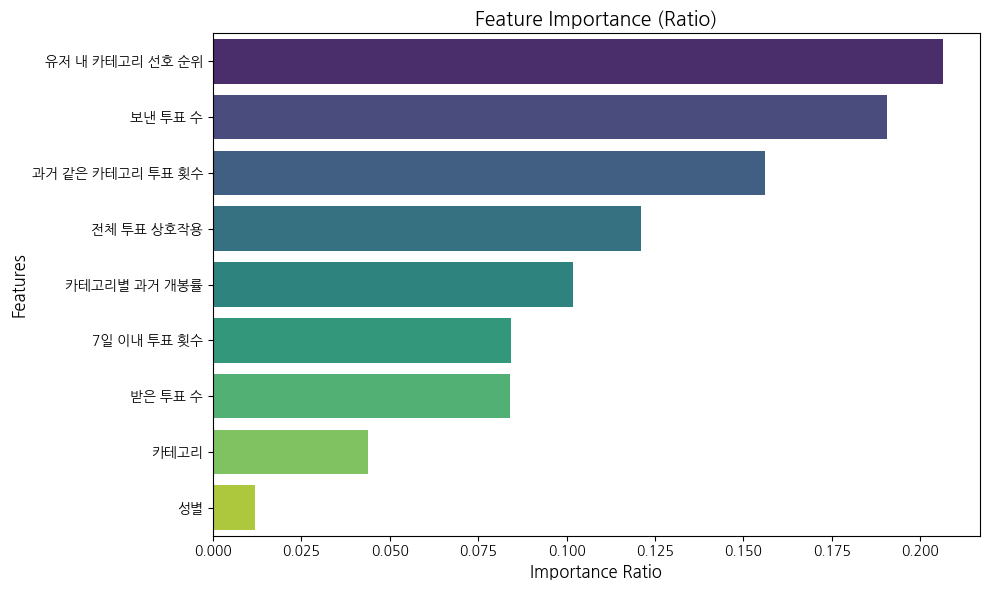

In [34]:
# 피쳐 중요도 데이터프레임 생성
feature_importances = pd.DataFrame({
    'feature': X_train.columns,
    'importance': final_model.feature_importances_
})

feature_importances['importance_ratio'] = feature_importances['importance'] / feature_importances['importance'].sum()

# 영문 피쳐명을 한글 라벨로 변환하기 위한 딕셔너리 정의
feature_name_mapping = {
    'category': '카테고리',
    'recent_7days_vote_count': '7일 이내 투표 횟수',
    'past_same_category_vote_count': '과거 같은 카테고리 투표 횟수',
    'sent_vote_count': '보낸 투표 수',
    'chosen_user_id_count': '받은 투표 수',
    'has_voted_before': '투표 경험 여부',
    'gender': '성별',
    'category_open_rate': '카테고리별 과거 개봉률',
    'user_category_rank': '유저 내 카테고리 선호 순위',
    'give_take_ratio': '전체 투표 상호작용'
}

# 피쳐 이름 매핑 적용
feature_importances['feature'] = feature_importances['feature'].map(feature_name_mapping)

# 정렬
feature_importances = feature_importances.sort_values(by='importance_ratio', ascending=False)

print("--- [피쳐 중요도 비율 순위] ---")
display(feature_importances[['feature', 'importance_ratio']])

# 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x='importance_ratio', y='feature', data=feature_importances, palette='viridis')
plt.title('Feature Importance (Ratio)', fontsize=14)
plt.xlabel('Importance Ratio', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

#### `has_voted_before` 삭제

#### 피쳐 중요도 이후 모델링

#### Random Forest

In [ ]:
# 데이터 준비 및 인코딩 단계
feature_cols = [
    'category','gender',
    'recent_7days_vote_count', 'past_same_category_vote_count', 'category_open_rate', 'user_category_rank',
    'give_take_ratio', 'sent_vote_count', 'chosen_user_id_count'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')

# Train / Test 데이터셋 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 최고 성능 파라미터
best_params_rf = {
    'random_state': 42,
    'n_jobs': -1,
    'n_estimators': 255,
    'max_depth': 20,
    'min_samples_split': 48,
    'min_samples_leaf': 7,
    'max_features': 'sqrt'
}

# 최종 Random Forest 모델 생성 및 학습
final_model_rf = RandomForestClassifier(**best_params_rf)
final_model_rf.fit(X_train_rf, y_train)

# 예측 확률 추출
y_pred_proba_opt_rf = final_model_rf.predict_proba(X_test_rf)[:, 1]

# PR-AUC 및 ROC-AUC 지표 계산
rf_pr_auc = average_precision_score(y_test, y_pred_proba_opt_rf)
rf_roc_auc = roc_auc_score(y_test, y_pred_proba_opt_rf)

# 상위 5% 커트라인 기준 임계값(Threshold) 설정 및 이진 분류
threshold_rf = np.percentile(y_pred_proba_opt_rf, 95)
y_pred_adjusted_opt_rf = (y_pred_proba_opt_rf >= threshold_rf).astype(int)

# 결과 출력
print(f"\n[Random Forest 최적 파라미터 적용 모델 최종 평가]")
print(f"PR-AUC Score: {rf_pr_auc:.4f}")
print(f"ROC-AUC Score: {rf_roc_auc:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_opt_rf))


[Random Forest 최적 파라미터 적용 모델 최종 평가]
PR-AUC Score: 0.1258
ROC-AUC Score: 0.7282

              precision    recall  f1-score   support

           0       0.96      0.96      0.96    229497
           1       0.17      0.18      0.18     11349

    accuracy                           0.92    240846
   macro avg       0.56      0.57      0.57    240846
weighted avg       0.92      0.92      0.92    240846



#### LightGBM

In [35]:
# 데이터 준비 및 인코딩 단계

feature_cols = [
    'category','gender',
    'recent_7days_vote_count', 'past_same_category_vote_count', 'category_open_rate', 'user_category_rank',
    'give_take_ratio', 'sent_vote_count', 'chosen_user_id_count'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')


# Train / Test 데이터셋 분할

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# Optuna가 찾아낸 최적의 하이퍼파라미터 딕셔너리 정의
best_params = {
    'objective': 'binary',
    'metric': 'average_precision',
    'boosting_type': 'gbdt',
    'random_state': 42,
    'verbose': -1,
    'learning_rate': 0.05102914059572818,
    'max_depth': 8,
    'num_leaves': 60,
    'min_child_samples': 75,
    'subsample': 0.908825456343595,
    'colsample_bytree': 0.8326981650434347,
    'scale_pos_weight': 2.68222920124868
}

# 최적 파라미터로 모델 생성 (n_estimators는 넉넉하게 잡고 조기 종료 활용)
final_model = lgb.LGBMClassifier(**best_params, n_estimators=500)

# 모델 학습
final_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=True)]
)

# 예측 확률 추출 및 임계값 조정 (상위 5% 커트라인)
y_pred_proba_opt = final_model.predict_proba(X_test)[:, 1]
threshold = np.percentile(y_pred_proba_opt, 95)
y_pred_adjusted_opt = (y_pred_proba_opt >= threshold).astype(int)

# 최종 성능 평가 결과 출력
final_pr_auc = average_precision_score(y_test, y_pred_proba_opt)
final_roc_auc = roc_auc_score(y_test, y_pred_proba_opt)

print(f"\n[최적 하이퍼파라미터 적용 모델 최종 평가]")
print(f"PR-AUC Score: {final_pr_auc:.4f}")
print(f"ROC-AUC Score: {final_roc_auc:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_opt))

Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[272]	valid_0's average_precision: 0.13253

[최적 하이퍼파라미터 적용 모델 최종 평가]
PR-AUC Score: 0.1325
ROC-AUC Score: 0.7378

              precision    recall  f1-score   support

           0       0.96      0.96      0.96    229497
           1       0.17      0.18      0.18     11349

    accuracy                           0.92    240846
   macro avg       0.57      0.57      0.57    240846
weighted avg       0.92      0.92      0.92    240846



#### XGBoost

In [ ]:
# 데이터 준비 및 인코딩 단계
feature_cols = [
    'category','gender',
    'recent_7days_vote_count', 'past_same_category_vote_count', 'category_open_rate', 'user_category_rank',
    'give_take_ratio', 'sent_vote_count', 'chosen_user_id_count'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')


# Train / Test 데이터셋 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Optuna가 찾아낸 XGBoost 최적의 하이퍼파라미터 딕셔너리 정의
best_params_xgb = {
    'objective': 'binary:logistic',
    'eval_metric': 'aucpr',
    'random_state': 42,
    'tree_method': 'hist',
    'enable_categorical': True,
    'learning_rate': 0.05945641449570623,
    'max_depth': 7,
    'min_child_weight': 8,
    'subsample': 0.7117656156601914,
    'colsample_bytree': 0.9949184153365462,
    'scale_pos_weight': 2.5183349073444554
}

# 최적 파라미터로 모델 생성
final_model_xgb = xgb.XGBClassifier(**best_params_xgb, n_estimators=500)

# 모델 학습
final_model_xgb.fit(
    X_train_opt, y_train,
    eval_set=[(X_test_opt, y_test)],
    verbose=50
)

# 예측 확률 추출 및 임계값 조정 (상위 5% 커트라인)
y_pred_proba_opt_xgb = final_model_xgb.predict_proba(X_test_opt)[:, 1]
threshold_xgb = np.percentile(y_pred_proba_opt_xgb, 95)
y_pred_adjusted_opt_xgb = (y_pred_proba_opt_xgb >= threshold_xgb).astype(int)

# 최종 성능 평가 결과 출력
final_pr_auc_xgb = average_precision_score(y_test, y_pred_proba_opt_xgb)
final_roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_opt_xgb)

print(f"\n[XGBoost 최적 하이퍼파라미터 적용 모델 최종 평가]")
print(f"PR-AUC Score: {final_pr_auc_xgb:.4f}")
print(f"ROC-AUC Score: {final_roc_auc_xgb:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_opt_xgb))

[0]	validation_0-aucpr:0.07877
[50]	validation_0-aucpr:0.12647
[100]	validation_0-aucpr:0.12999
[150]	validation_0-aucpr:0.13108
[200]	validation_0-aucpr:0.13110
[250]	validation_0-aucpr:0.13094
[300]	validation_0-aucpr:0.13113
[350]	validation_0-aucpr:0.13085
[400]	validation_0-aucpr:0.13074
[450]	validation_0-aucpr:0.13044
[499]	validation_0-aucpr:0.13011

[XGBoost 최적 하이퍼파라미터 적용 모델 최종 평가]
PR-AUC Score: 0.1302
ROC-AUC Score: 0.7374

              precision    recall  f1-score   support

           0       0.96      0.96      0.96    229497
           1       0.17      0.18      0.18     11349

    accuracy                           0.92    240846
   macro avg       0.57      0.57      0.57    240846
weighted avg       0.92      0.92      0.92    240846



### 최종 LightGBM

#### 클래스 가중치 하이퍼파라미터

In [28]:
# 훈련 데이터 기준 클래스 가중치 계산
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = neg_count / pos_count

# Optuna Objective 함수 정의
def objective_with_weight(trial):
    params = {
        'objective': 'binary',
        'metric': 'average_precision',
        'boosting_type': 'gbdt',
        'random_state': 42,
        'verbose': -1,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'scale_pos_weight': scale_pos_weight_val  # 👈 가중치가 반영된 상태에서 튜닝 진행
    }

    # 내부 검증을 위한 쪼개기 (Data Leakage 방지)
    X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

    model = lgb.LGBMClassifier(**params, n_estimators=300)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
    )

    preds = model.predict_proba(X_val)[:, 1]
    score = average_precision_score(y_val, preds)
    return score

# Optuna Study 실행
study_weight = optuna.create_study(direction='maximize')
study_weight.optimize(objective_with_weight, n_trials=30)

print("[클래스 가중치 반영 최적 파라미터]")
print(study_weight.best_params)

[I 2026-10-01 02:11:31,265] A new study created in memory with name: no-name-9d6c7bca-568d-4657-bd8b-45cff0749269
[I 2026-10-01 02:11:59,607] Trial 0 finished with value: 0.12412689876987712 and parameters: {'learning_rate': 0.0609347977643719, 'max_depth': 7, 'num_leaves': 45, 'min_child_samples': 66, 'subsample': 0.9700548792023755, 'colsample_bytree': 0.9900012527755411}. Best is trial 0 with value: 0.12412689876987712.
[I 2026-10-01 02:12:50,705] Trial 1 finished with value: 0.1244187385084107 and parameters: {'learning_rate': 0.03205889731677098, 'max_depth': 7, 'num_leaves': 64, 'min_child_samples': 75, 'subsample': 0.7015840565729404, 'colsample_bytree': 0.9329753516828044}. Best is trial 1 with value: 0.1244187385084107.
[I 2026-10-01 02:13:42,955] Trial 2 finished with value: 0.12060558781437362 and parameters: {'learning_rate': 0.015399604606723688, 'max_depth': 9, 'num_leaves': 31, 'min_child_samples': 91, 'subsample': 0.60032320367444, 'colsample_bytree': 0.9090515797243687

[클래스 가중치 반영 최적 파라미터]
{'learning_rate': 0.03741964803428634, 'max_depth': 6, 'num_leaves': 40, 'min_child_samples': 89, 'subsample': 0.6553376163244405, 'colsample_bytree': 0.9898759502017432}


In [31]:
# 데이터 준비 및 인코딩 단계

feature_cols = [
    'category', 'gender',
    'recent_7days_vote_count', 'past_same_category_vote_count',
    'category_open_rate', 'user_category_rank',
    'give_take_ratio', 'sent_vote_count', 'chosen_user_id_count'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')

# Train / Test 데이터셋 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# 클래스 가중치(scale_pos_weight) 자동 계산

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
ideal_scale_pos_weight = neg_count / pos_count

print(f"[클래스 분포 분석]")
print(f"- 개봉 안 함 (0): {neg_count:,}개")
print(f"- 개봉 함 (1): {pos_count:,}개")
print(f"- 수학적 최적 scale_pos_weight 값: {ideal_scale_pos_weight:.2f}\n")


# Optuna 최적 파라미터 적용 딕셔너리 정의

best_params = {
    'objective': 'binary',
    'metric': 'average_precision',
    'boosting_type': 'gbdt',
    'random_state': 42,
    'verbose': -1,
    'learning_rate': 0.03741964803428634,
    'max_depth': 6,
    'num_leaves': 40,
    'min_child_samples': 89,
    'subsample': 0.6553376163244405,
    'colsample_bytree': 0.9898759502017432,
    'scale_pos_weight': ideal_scale_pos_weight
}


# 최종 모델 생성 및 학습

final_model = lgb.LGBMClassifier(**best_params, n_estimators=500)

print("--- Optuna 최적 파라미터 + 가중치 적용 LightGBM 학습 시작 ---")
final_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=True)]
)


# 예측 확률 추출 및 임계값 조정

y_pred_proba_opt = final_model.predict_proba(X_test)[:, 1]

# 상위 5% 타겟팅 기준 설정
threshold = np.percentile(y_pred_proba_opt, 95)
y_pred_adjusted_opt = (y_pred_proba_opt >= threshold).astype(int)


# 최종 성능 평가 결과 출력

final_pr_auc = average_precision_score(y_test, y_pred_proba_opt)
final_roc_auc = roc_auc_score(y_test, y_pred_proba_opt)

print(f"\n[최적 하이퍼파라미터 + 가중치 적용 모델 최종 평가]")
print(f"PR-AUC Score: {final_pr_auc:.4f}")
print(f"ROC-AUC Score: {final_roc_auc:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_opt))

[클래스 분포 분석]
- 개봉 안 함 (0): 917,984개
- 개봉 함 (1): 45,398개
- 수학적 최적 scale_pos_weight 값: 20.22

--- Optuna 최적 파라미터 + 가중치 적용 LightGBM 학습 시작 ---
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[447]	valid_0's average_precision: 0.131446

[최적 하이퍼파라미터 + 가중치 적용 모델 최종 평가]
PR-AUC Score: 0.1314
ROC-AUC Score: 0.7374

              precision    recall  f1-score   support

           0       0.96      0.96      0.96    229497
           1       0.17      0.18      0.18     11349

    accuracy                           0.92    240846
   macro avg       0.57      0.57      0.57    240846
weighted avg       0.92      0.92      0.92    240846



#### SMOTE 하이퍼파라미터

In [29]:
# Optuna Objective 함수 정의
def objective_with_smote(trial):
    params = {
        'objective': 'binary',
        'metric': 'average_precision',
        'boosting_type': 'gbdt',
        'random_state': 42,
        'verbose': -1,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0)
    }

    X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

    # SMOTE 적용을 위한 카테고리형 변수 수치 변환
    X_tr_num = X_tr.copy()
    X_val_num = X_val.copy()
    X_tr_num['category'] = X_tr_num['category'].cat.codes
    X_val_num['category'] = X_val_num['category'].cat.codes

    # 훈련 셋(X_tr)에만 실시간으로 SMOTE 적용
    smote = SMOTE(random_state=42)
    X_tr_res, y_tr_res = smote.fit_resample(X_tr_num, y_tr)

    # 카테고리 타입 복구
    X_tr_res['category'] = X_tr_res['category'].astype('category')
    X_val_num['category'] = X_val_num['category'].astype('category')

    model = lgb.LGBMClassifier(**params, n_estimators=300)
    model.fit(
        X_tr_res, y_tr_res,
        eval_set=[(X_val_num, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
    )

    preds = model.predict_proba(X_val_num)[:, 1]
    score = average_precision_score(y_val, preds)
    return score

# Optuna Study 실행
study_smote = optuna.create_study(direction='maximize')
study_smote.optimize(objective_with_smote, n_trials=20)

print("[SMOTE 반영 최적 파라미터]")
print(study_smote.best_params)

[I 2026-10-01 02:32:38,269] A new study created in memory with name: no-name-915870d3-a05b-4ec0-bd7a-3a4b6e1ac100
[I 2026-10-01 02:34:19,475] Trial 0 finished with value: 0.0893170246712528 and parameters: {'learning_rate': 0.013841041473556734, 'max_depth': 8, 'num_leaves': 93, 'min_child_samples': 65, 'subsample': 0.8776977366782825, 'colsample_bytree': 0.9213038171676902}. Best is trial 0 with value: 0.0893170246712528.
[I 2026-10-01 02:35:04,597] Trial 1 finished with value: 0.09099944267284925 and parameters: {'learning_rate': 0.06199380587241754, 'max_depth': 8, 'num_leaves': 87, 'min_child_samples': 58, 'subsample': 0.9357394174161208, 'colsample_bytree': 0.8254394949018081}. Best is trial 1 with value: 0.09099944267284925.
[I 2026-10-01 02:36:25,812] Trial 2 finished with value: 0.091001394384334 and parameters: {'learning_rate': 0.04428212922253979, 'max_depth': 9, 'num_leaves': 46, 'min_child_samples': 100, 'subsample': 0.6530978216769022, 'colsample_bytree': 0.78772327805055

[SMOTE 반영 최적 파라미터]
{'learning_rate': 0.09415378010236372, 'max_depth': 6, 'num_leaves': 51, 'min_child_samples': 85, 'subsample': 0.6454309660991584, 'colsample_bytree': 0.9818293126545728}


In [30]:
# 데이터 준비 및 인코딩 단계

feature_cols = [
    'category', 'gender',
    'recent_7days_vote_count', 'past_same_category_vote_count',
    'category_open_rate', 'user_category_rank',
    'give_take_ratio', 'sent_vote_count', 'chosen_user_id_count'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')

# Train / Test 데이터셋 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# 훈련 데이터에만 SMOTE 리샘플링 적용
# SMOTE 입력을 위해 카테고리형 변수를 수치 코드로 일시 변환
X_train_num = X_train.copy()
X_test_num = X_test.copy()
X_train_num['category'] = X_train_num['category'].cat.codes
X_test_num['category'] = X_test_num['category'].cat.codes

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_num, y_train)

# SMOTE 완료 후 카테고리 타입 복구
X_train_resampled['category'] = X_train_resampled['category'].astype('category')
X_test_num['category'] = X_test_num['category'].astype('category')

print(f"[안내] SMOTE 적용 전 훈련 데이터 크기: {X_train.shape}")
print(f"[안내] SMOTE 적용 후 훈련 데이터 크기: {X_train_resampled.shape}\n")


# SMOTE 최적 파라미터 적용 딕셔너리 정의

best_params_smote = {
    'objective': 'binary',
    'metric': 'average_precision',
    'boosting_type': 'gbdt',
    'random_state': 42,
    'verbose': -1,
    'learning_rate': 0.09415378010236372,
    'max_depth': 6,
    'num_leaves': 51,
    'min_child_samples': 85,
    'subsample': 0.6454309660991584,
    'colsample_bytree': 0.9818293126545728
    # SMOTE를 사용하므로 scale_pos_weight는 제외합니다.
}


# 최종 모델 생성 및 학습 (조기 종료 적용)

final_model_smote = lgb.LGBMClassifier(**best_params_smote, n_estimators=500)

print("--- SMOTE 최적 파라미터 적용 LightGBM 학습 시작 ---")
final_model_smote.fit(
    X_train_resampled, y_train_resampled,
    eval_set=[(X_test_num, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=True)]
)


# 예측 확률 추출 및 임계값 조정 (상위 5% 커트라인)

y_pred_proba_smote = final_model_smote.predict_proba(X_test_num)[:, 1]

# 상위 5% 타겟팅 기준 설정
threshold_smote = np.percentile(y_pred_proba_smote, 95)
y_pred_adjusted_smote = (y_pred_proba_smote >= threshold_smote).astype(int)


# 최종 성능 평가 결과 출력

pr_auc_smote = average_precision_score(y_test, y_pred_proba_smote)
roc_auc_smote = roc_auc_score(y_test, y_pred_proba_smote)

print(f"\n[SMOTE 최적 파라미터 적용 모델 최종 평가]")
print(f"PR-AUC Score: {pr_auc_smote:.4f}")
print(f"ROC-AUC Score: {roc_auc_smote:.4f}\n")
print(classification_report(y_test, y_pred_adjusted_smote))

[안내] SMOTE 적용 전 훈련 데이터 크기: (963382, 9)
[안내] SMOTE 적용 후 훈련 데이터 크기: (1835968, 9)

--- SMOTE 최적 파라미터 적용 LightGBM 학습 시작 ---
Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[186]	valid_0's average_precision: 0.0943659

[SMOTE 최적 파라미터 적용 모델 최종 평가]
PR-AUC Score: 0.0944
ROC-AUC Score: 0.6793

              precision    recall  f1-score   support

           0       0.96      0.95      0.96    229497
           1       0.13      0.13      0.13     11349

    accuracy                           0.92    240846
   macro avg       0.54      0.54      0.54    240846
weighted avg       0.92      0.92      0.92    240846



### threshold 조정

#### LightGBM + threshold

In [41]:
# 예측 확률 추출 및 최적 퍼센타일(Threshold) 탐색

y_pred_proba_opt = final_model.predict_proba(X_test)[:, 1]

# 탐색할 퍼센타일 후보군 설정 (상위 20% ~ 상위 0% 구간, 0.5% 간격)
percentiles = np.arange(80.0, 100.0, 0.5)

best_percentile = 0
best_f1 = 0
best_threshold = 0
results = []

print("--- 임계값(퍼센타일) 최적화 탐색 시작 ---")
for p in percentiles:
    # 해당 퍼센타일에 해당하는 확률 커트라인 계산
    threshold = np.percentile(y_pred_proba_opt, p)
    y_pred_custom = (y_pred_proba_opt >= threshold).astype(int)

    # 평가 지표 계산 (Class 1 기준)
    precision = precision_score(y_test, y_pred_custom, zero_division=0)
    recall = recall_score(y_test, y_pred_custom, zero_division=0)
    f1 = f1_score(y_test, y_pred_custom, zero_division=0)

    results.append({
        'Percentile': 100 - p,
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    # F1-score가 가장 높아지는 지점 추적
    if f1 > best_f1:
        best_f1 = f1
        best_percentile = 100 - p
        best_threshold = threshold

# 탐색 결과 요약 출력
result_df = pd.DataFrame(results)
print("\n[상위 퍼센타일별 성능 변화 요약 (상위 구간 일부)]")
print(result_df.tail(10).to_string(index=False))

print("\n" + "="*40)
print(f"🎯 최적의 타겟팅 커트라인 발견!")
print(f"- 상위 퍼센타일: 상위 {best_percentile:.1f}%")
print(f"- 확률 임계값(Threshold): {best_threshold:.4f}")
print(f"- 이때의 F1-Score: {best_f1:.4f}")
print("="*40 + "\n")


# ==========================================
# 2. 찾은 최적 커트라인을 적용하여 최종 평가 수행
# ==========================================
# 탐색된 최적 퍼센타일 값 적용
target_percentile = best_percentile
p_target = 100 - target_percentile

# 해당 퍼센타일에 맞는 Threshold 재계산
optimal_threshold = np.percentile(y_pred_proba_opt, p_target)

# 최적 임계값으로 이진 분류 결과 생성
y_pred_custom_adjusted = (y_pred_proba_opt >= optimal_threshold).astype(int)

# 전체 AUC 지표 계산
final_pr_auc = average_precision_score(y_test, y_pred_proba_opt)
final_roc_auc = roc_auc_score(y_test, y_pred_proba_opt)

# 최종 결과 출력
print("=" * 50)
print(f"🎯 [최적 커트라인: 상위 {target_percentile:.1f}% 타겟팅 전략 적용 결과]")
print(f"- 확률 임계값 (Threshold): {optimal_threshold:.4f}")
print(f"- PR-AUC Score : {final_pr_auc:.4f}")
print(f"- ROC-AUC Score: {final_roc_auc:.4f}")
print("=" * 50)
print("\n[상세 분류 리포트 (Classification Report)]")
print(classification_report(y_test, y_pred_custom_adjusted))

--- 임계값(퍼센타일) 최적화 탐색 시작 ---

[상위 퍼센타일별 성능 변화 요약 (상위 구간 일부)]
 Percentile  Threshold  Precision   Recall  F1-Score
        5.0   0.740171   0.171635 0.182131  0.176727
        4.5   0.747177   0.176954 0.169002  0.172886
        4.0   0.755047   0.182686 0.155080  0.167755
        3.5   0.763088   0.189798 0.140982  0.161788
        3.0   0.771631   0.197896 0.126002  0.153970
        2.5   0.781322   0.206410 0.109525  0.143112
        2.0   0.792529   0.220262 0.093488  0.131263
        1.5   0.805245   0.233601 0.074368  0.112819
        1.0   0.821406   0.258614 0.054895  0.090565
        0.5   0.847269   0.309544 0.032866  0.059423

🎯 최적의 타겟팅 커트라인 발견!
- 상위 퍼센타일: 상위 12.5%
- 확률 임계값(Threshold): 0.6614
- 이때의 F1-Score: 0.1934

🎯 [최적 커트라인: 상위 12.5% 타겟팅 전략 적용 결과]
- 확률 임계값 (Threshold): 0.6614
- PR-AUC Score : 0.1314
- ROC-AUC Score: 0.7374

[상세 분류 리포트 (Classification Report)]
              precision    recall  f1-score   support

           0       0.97      0.89      0.92    229497
       

#### LightGBM(scale_pos_weight) + threshold

In [39]:
# 데이터 준비 및 인코딩 단계

feature_cols = [
    'category', 'gender',
    'recent_7days_vote_count', 'past_same_category_vote_count',
    'category_open_rate', 'user_category_rank',
    'give_take_ratio', 'sent_vote_count', 'chosen_user_id_count'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')

# Train / Test 데이터셋 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# 클래스 가중치(scale_pos_weight) 자동 계산

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
ideal_scale_pos_weight = neg_count / pos_count

print(f"[클래스 분포 분석]")
print(f"- 개봉 안 함 (0): {neg_count:,}개")
print(f"- 개봉 함 (1): {pos_count:,}개")
print(f"- 수학적 최적 scale_pos_weight 값: {ideal_scale_pos_weight:.2f}\n")


# Optuna 최적 파라미터 적용 딕셔너리 정의
best_params = {
    'objective': 'binary',
    'metric': 'average_precision',
    'boosting_type': 'gbdt',
    'random_state': 42,
    'verbose': -1,
    'learning_rate': 0.03741964803428634,
    'max_depth': 6,
    'num_leaves': 40,
    'min_child_samples': 89,
    'subsample': 0.6553376163244405,
    'colsample_bytree': 0.9898759502017432,
    'scale_pos_weight': ideal_scale_pos_weight
}


# 최종 모델 생성 및 학습

final_model = lgb.LGBMClassifier(**best_params, n_estimators=500)

print("--- Optuna 최적 파라미터 + 가중치 적용 LightGBM 학습 시작 ---")
final_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
)


# 예측 확률 추출 및 최적 임계값(퍼센타일) 탐색

y_pred_proba_opt = final_model.predict_proba(X_test)[:, 1]

# 탐색할 퍼센타일 후보군 설정 (예: 상위 1% ~ 20% 구간)
percentiles = np.arange(80.0, 100.0, 0.5)

best_percentile = 0
best_f1 = 0
best_threshold = 0

print("\n--- 임계값(퍼센타일) 최적화 탐색 중 ---")
for p in percentiles:
    threshold = np.percentile(y_pred_proba_opt, p)
    y_pred_custom = (y_pred_proba_opt >= threshold).astype(int)

    f1 = f1_score(y_test, y_pred_custom, zero_division=0)

    if f1 > best_f1:
        best_f1 = f1
        best_percentile = 100 - p  # 상위 몇 %인지
        best_threshold = threshold

print(f"🎯 최적 타겟팅 커트라인 발견: 상위 {best_percentile:.1f}% (Threshold: {best_threshold:.4f}, F1-Score: {best_f1:.4f})\n")


# 최적 임계값 적용 및 최종 성능 평가
y_pred_adjusted_opt = (y_pred_proba_opt >= best_threshold).astype(int)

final_pr_auc = average_precision_score(y_test, y_pred_proba_opt)
final_roc_auc = roc_auc_score(y_test, y_pred_proba_opt)

print("=" * 50)
print(f"🎯 [최적 퍼센타일(상위 {best_percentile:.1f}%) 적용 모델 최종 평가]")
print(f"- 확률 임계값 (Threshold): {best_threshold:.4f}")
print(f"- PR-AUC Score : {final_pr_auc:.4f}")
print(f"- ROC-AUC Score: {final_roc_auc:.4f}")
print("=" * 50)
print("\n[상세 분류 리포트 (Classification Report)]")
print(classification_report(y_test, y_pred_adjusted_opt))

[클래스 분포 분석]
- 개봉 안 함 (0): 917,984개
- 개봉 함 (1): 45,398개
- 수학적 최적 scale_pos_weight 값: 20.22

--- Optuna 최적 파라미터 + 가중치 적용 LightGBM 학습 시작 ---

--- 임계값(퍼센타일) 최적화 탐색 중 ---
🎯 최적 타겟팅 커트라인 발견: 상위 12.5% (Threshold: 0.6614, F1-Score: 0.1934)

🎯 [최적 퍼센타일(상위 12.5%) 적용 모델 최종 평가]
- 확률 임계값 (Threshold): 0.6614
- PR-AUC Score : 0.1314
- ROC-AUC Score: 0.7374

[상세 분류 리포트 (Classification Report)]
              precision    recall  f1-score   support

           0       0.97      0.89      0.92    229497
           1       0.13      0.35      0.19     11349

    accuracy                           0.86    240846
   macro avg       0.55      0.62      0.56    240846
weighted avg       0.93      0.86      0.89    240846



#### LightGBM(SMOTE) + threshold

In [40]:
# 데이터 준비 및 인코딩 단계

feature_cols = [
    'category', 'gender',
    'recent_7days_vote_count', 'past_same_category_vote_count',
    'category_open_rate', 'user_category_rank',
    'give_take_ratio', 'sent_vote_count', 'chosen_user_id_count'
]

X = df_mart[feature_cols].copy()
y = df_mart['is_opened'].copy()

# 범주형/이진형 변수 전처리
X['gender'] = X['gender'].map({'F': 0, 'M': 1}).fillna(0)
X['category'] = X['category'].astype('category')

# Train / Test 데이터셋 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# 훈련 데이터에만 SMOTE 리샘플링 적용

X_train_num = X_train.copy()
X_test_num = X_test.copy()
X_train_num['category'] = X_train_num['category'].cat.codes
X_test_num['category'] = X_test_num['category'].cat.codes

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_num, y_train)

X_train_resampled['category'] = X_train_resampled['category'].astype('category')
X_test_num['category'] = X_test_num['category'].astype('category')

print(f"[안내] SMOTE 적용 전 훈련 데이터 크기: {X_train.shape}")
print(f"[안내] SMOTE 적용 후 훈련 데이터 크기: {X_train_resampled.shape}\n")


# SMOTE 최적 파라미터 적용 딕셔너리 정의

best_params_smote = {
    'objective': 'binary',
    'metric': 'average_precision',
    'boosting_type': 'gbdt',
    'random_state': 42,
    'verbose': -1,
    'learning_rate': 0.09415378010236372,
    'max_depth': 6,
    'num_leaves': 51,
    'min_child_samples': 85,
    'subsample': 0.6454309660991584,
    'colsample_bytree': 0.9818293126545728
}


# 최종 모델 생성 및 학습

final_model_smote = lgb.LGBMClassifier(**best_params_smote, n_estimators=500)

print("--- SMOTE 최적 파라미터 적용 LightGBM 학습 시작 ---")
final_model_smote.fit(
    X_train_resampled, y_train_resampled,
    eval_set=[(X_test_num, y_test)],
    callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
)



# 예측 확률 추출 및 최적 임계값(퍼센타일) 탐색

y_pred_proba_smote = final_model_smote.predict_proba(X_test_num)[:, 1]

# 탐색할 퍼센타일 후보군 설정 (예: 상위 1% ~ 20% 구간)
percentiles = np.arange(80.0, 100.0, 0.5)

best_percentile = 0
best_f1 = 0
best_threshold = 0

print("\n--- 임계값(퍼센타일) 최적화 탐색 중 ---")
for p in percentiles:
    threshold = np.percentile(y_pred_proba_smote, p)
    y_pred_custom = (y_pred_proba_smote >= threshold).astype(int)

    f1 = f1_score(y_test, y_pred_custom, zero_division=0)

    if f1 > best_f1:
        best_f1 = f1
        best_percentile = 100 - p
        best_threshold = threshold

print(f"🎯 최적 타겟팅 커트라인 발견: 상위 {best_percentile:.1f}% (Threshold: {best_threshold:.4f}, F1-Score: {best_f1:.4f})\n")



# 최적 임계값 적용 및 최종 성능 평가
y_pred_adjusted_smote = (y_pred_proba_smote >= best_threshold).astype(int)

pr_auc_smote = average_precision_score(y_test, y_pred_proba_smote)
roc_auc_smote = roc_auc_score(y_test, y_pred_proba_smote)

print("=" * 50)
print(f"🎯 [SMOTE + 최적 퍼센타일(상위 {best_percentile:.1f}%) 적용 모델 최종 평가]")
print(f"- 확률 임계값 (Threshold): {best_threshold:.4f}")
print(f"- PR-AUC Score : {pr_auc_smote:.4f}")
print(f"- ROC-AUC Score: {roc_auc_smote:.4f}")
print("=" * 50)
print("\n[상세 분류 리포트 (Classification Report)]")
print(classification_report(y_test, y_pred_adjusted_smote))

[안내] SMOTE 적용 전 훈련 데이터 크기: (963382, 9)
[안내] SMOTE 적용 후 훈련 데이터 크기: (1835968, 9)

--- SMOTE 최적 파라미터 적용 LightGBM 학습 시작 ---

--- 임계값(퍼센타일) 최적화 탐색 중 ---
🎯 최적 타겟팅 커트라인 발견: 상위 16.5% (Threshold: 0.5789, F1-Score: 0.1523)

🎯 [SMOTE + 최적 퍼센타일(상위 16.5%) 적용 모델 최종 평가]
- 확률 임계값 (Threshold): 0.5789
- PR-AUC Score : 0.0944
- ROC-AUC Score: 0.6793

[상세 분류 리포트 (Classification Report)]
              precision    recall  f1-score   support

           0       0.96      0.84      0.90    229497
           1       0.10      0.34      0.15     11349

    accuracy                           0.82    240846
   macro avg       0.53      0.59      0.53    240846
weighted avg       0.92      0.82      0.86    240846

